# Práctica: Minería de reglas de asociación con Instacart Market Basket Analysis

García Alvarado Héctor Giovani
Minería de Datos, ESCOM-IPN

En esta práctica se construye un sistema de recomendación de productos con reglas de asociación a partir del dataset de Instacart (Kaggle). Se trabajó en Python, con mlxtend para Apriori y FP-Growth, una implementación propia de Eclat y una aplicación en Gradio.

El notebook sigue el orden de la práctica:

0. Configuración y descarga de datos
1. Preparación y análisis de datos
2. Apriori, FP-Growth y Eclat (propio)
3. Generación de reglas
4. Patrones de consumo
5. Reglas engañosas
6. Aplicación en Gradio
7. Popularidad contra reglas
8. Robustez
9. Reto final y reproducibilidad

## 0. Configuración

En la siguiente celda se concentran la semilla, los umbrales y los demás parámetros, para que al volver a ejecutar todo se obtengan los mismos resultados. Si en Colab Apriori tarda demasiado con el soporte más bajo, se puede quitar el último valor de `SOPORTES`.

In [1]:
%pip install -q mlxtend gradio kagglehub seaborn

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.0.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
import os, sys, time, math, random, gc, json, glob, platform
import tracemalloc, itertools, warnings, pickle, importlib
from collections import Counter, defaultdict

import numpy as np
import pandas as pd
import scipy
import scipy.sparse as sp
from scipy import stats
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns
import mlxtend
from mlxtend.frequent_patterns import apriori, fpgrowth

warnings.filterwarnings('ignore')

# Reproducibilidad
SEMILLA = 42
random.seed(SEMILLA)
np.random.seed(SEMILLA)
RNG = np.random.default_rng(SEMILLA)

# Rutas
EN_COLAB = 'google.colab' in sys.modules
# Carpeta con los CSV ya descomprimidos (solo se usa fuera de Colab; si no existe se descarga con kagglehub)
DIR_DATOS_LOCAL = 'data'
DIR_SALIDA = '/content/artefactos' if EN_COLAB else os.path.abspath('artefactos')  # CSV, modelo y app

# Parámetros
N_ORDENES_OBJETIVO = 120_000  # transacciones a muestrear (por usuario completo)
SOPORTES = [0.02, 0.01, 0.0075, 0.005, 0.003]  # Parte 2: cinco soportes mínimos
SOPORTE_REGLAS = 0.002  # Parte 3 (se reduce automáticamente si no salen 100 reglas)
CONF_MIN_REGLAS = 0.05  # confianza mínima para reglas candidatas
MEJORA_MIN = 0.01  # mejora mínima para no considerar una regla redundante
SOPORTE_SEG = 0.004  # Parte 4: soporte relativo dentro de cada segmento
MIN_CONTEO_PAR = 5  # base del recomendador: un par debe co-ocurrir >= 5 veces
PROP_ENTRENAMIENTO = 0.70  # Parte 7: 70 % de los pedidos de cada usuario
N_CANASTAS_EVAL = 5000  # canastas de prueba evaluadas
N_EVAL_ROBUSTEZ = 2000  # canastas usadas en la Parte 8
PROP_OCULTA = 0.5  # proporción de productos ocultos por canasta
K = 5  # recomendaciones por consulta
K_ENTRADA_MAX = 5  # máximo de productos de entrada (igual que la app)
LIFT_MIN_EVAL = 1.0  # lift mínimo usado por el sistema B en la evaluación
SOPORTE_APP = 0.001  # Parte 6: soporte para reglas de 2+ productos sobre el dataset completo
TOP_K_APP_CONF = 30  # Parte 6: reglas 1-1 que se conservan por producto (mejores por confianza)
TOP_K_APP_LIFT = 20  #          + las mejores por lift

sns.set_theme(style='whitegrid', context='notebook')
plt.rcParams['figure.dpi'] = 110
pd.set_option('display.max_colwidth', 110)
pd.set_option('display.width', 220)

VERSIONES = {'python': platform.python_version(), 'numpy': np.__version__, 'pandas': pd.__version__,
             'scipy': scipy.__version__, 'mlxtend': mlxtend.__version__, 'matplotlib': matplotlib.__version__,
             'seaborn': sns.__version__}
print(pd.Series(VERSIONES).to_string())
print('Entorno:', 'Google Colab' if EN_COLAB else 'local', '| salida en', DIR_SALIDA)

python        3.14.5
numpy          2.5.4
pandas         3.1.0
scipy         1.18.1
mlxtend       0.25.0
matplotlib    3.11.2
seaborn       0.13.2
Entorno: local | salida en artefactos


In [3]:
# En Colab se descarga con kagglehub (dataset público, no requiere kaggle.json).
# En local se usan los CSV ya descomprimidos si existe DIR_DATOS_LOCAL.
if not EN_COLAB and os.path.isdir(DIR_DATOS_LOCAL):
    DIR_DATOS = DIR_DATOS_LOCAL
else:
    import kagglehub
    DIR_DATOS = kagglehub.dataset_download('psparks/instacart-market-basket-analysis')
print('Path to dataset files:', DIR_DATOS)

Path to dataset files: data


In [4]:
os.makedirs(DIR_SALIDA, exist_ok=True)
ARCHIVOS = ['orders.csv', 'order_products__prior.csv', 'order_products__train.csv',
            'products.csv', 'aisles.csv', 'departments.csv']

def localizar(nombre):
    m = [p for p in glob.glob(os.path.join(DIR_DATOS, '**', nombre), recursive=True) if '__MACOSX' not in p]
    return sorted(m, key=len)[0] if m else None

RUTAS = {a: localizar(a) for a in ARCHIVOS}
faltan = [a for a, r in RUTAS.items() if r is None]
assert not faltan, f'Faltan archivos: {faltan}'
for a, r in RUTAS.items():
    print(f'{a:28s} {os.path.getsize(r)/2**20:8.1f} MB')

orders.csv                      103.9 MB
order_products__prior.csv       550.8 MB
order_products__train.csv        23.5 MB
products.csv                      2.1 MB
aisles.csv                        0.0 MB
departments.csv                   0.0 MB


# Parte 1. Preparación y análisis de datos

## 1.1 Exploración de los archivos

El dataset trae seis archivos:

| Archivo | Contenido |
|---|---|
| `orders.csv` | Un renglón por pedido: usuario, número de pedido del usuario, día (`order_dow`), hora y días desde el pedido anterior. `eval_set` dice si sus productos están en *prior*, en *train* o si es *test* (sin productos). |
| `order_products__prior.csv` | Productos de todos los pedidos previos de cada usuario. |
| `order_products__train.csv` | Productos del último pedido de los usuarios *train*. |
| `products.csv`, `aisles.csv`, `departments.csv` | Catálogo: producto, pasillo (categoría) y departamento. |

In [5]:
tipos_ord = {'order_id': 'int32', 'user_id': 'int32', 'order_number': 'int16', 'order_dow': 'int8',
             'order_hour_of_day': 'int8', 'days_since_prior_order': 'float32', 'eval_set': 'category'}
tipos_op = {'order_id': 'int32', 'product_id': 'int32', 'add_to_cart_order': 'int16', 'reordered': 'int8'}

orders = pd.read_csv(RUTAS['orders.csv'], dtype=tipos_ord)
products = pd.read_csv(RUTAS['products.csv'], dtype={'product_id': 'int32', 'aisle_id': 'int16', 'department_id': 'int8'})
aisles = pd.read_csv(RUTAS['aisles.csv'])
departments = pd.read_csv(RUTAS['departments.csv'])
op_prior = pd.read_csv(RUTAS['order_products__prior.csv'], dtype=tipos_op)
op_train = pd.read_csv(RUTAS['order_products__train.csv'], dtype=tipos_op)

tablas = {'orders': orders, 'order_products__prior': op_prior, 'order_products__train': op_train,
          'products': products, 'aisles': aisles, 'departments': departments}
resumen = pd.DataFrame({n: {'filas': len(d), 'columnas': d.shape[1], 'nulos': int(d.isna().sum().sum()),
                            'memoria_MB': round(d.memory_usage(deep=True).sum() / 2**20, 1)} for n, d in tablas.items()}).T
display(resumen)
for n, d in tablas.items():
    print(f'\n{n}:'); display(d.head(3))

print('Pedidos por eval_set:'); print(orders.eval_set.value_counts().to_string())
print(f'\nUsuarios: {orders.user_id.nunique():,} | Productos: {len(products):,} | '
      f'Pasillos: {len(aisles):,} | Departamentos: {len(departments):,}')
print(f'Nulos en days_since_prior_order: {orders.days_since_prior_order.isna().sum():,} '
      '(corresponden al primer pedido de cada usuario, es esperado)')

,filas,columnas,nulos,memoria_MB
orders,3421083.0,7.0,206209.0,55.5
order_products__prior,32434489.0,4.0,0.0,340.3
order_products__train,1384617.0,4.0,0.0,14.5
products,49688.0,4.0,0.0,4.1
aisles,134.0,2.0,0.0,0.0
departments,21.0,2.0,0.0,0.0



orders:


,order_id,user_id,eval_set,order_number,order_dow,order_hour_of_day,days_since_prior_order
0,2539329,1,prior,1,2,8,NaN
1,2398795,1,prior,2,3,7,15.0
2,473747,1,prior,3,3,12,21.0



order_products__prior:


,order_id,product_id,add_to_cart_order,reordered
0,2,33120,1,1
1,2,28985,2,1
2,2,9327,3,0



order_products__train:


... (4 outputs left out)

,aisle_id,aisle
0,1,prepared soups salads
1,2,specialty cheeses
2,3,energy granola bars



departments:


,department_id,department
0,1,frozen
1,2,other
2,3,bakery


Pedidos por eval_set:
eval_set
prior    3214874
train     131209
test       75000

Usuarios: 206,209 | Productos: 49,688 | Pasillos: 134 | Departamentos: 21
Nulos en days_since_prior_order: 206,209 (corresponden al primer pedido de cada usuario, es esperado)


## 1.2 Integración de productos, pasillos, departamentos y transacciones

Se unió `products` con `aisles` y `departments` para tener el catálogo completo. Después se juntaron los productos de `prior` y `train`, porque entre los dos contienen todos los pedidos que tienen productos. Los pedidos `test` no traen productos, por lo que se descartaron.

In [6]:
productos = (products.merge(aisles, on='aisle_id', how='left')
                     .merge(departments, on='department_id', how='left'))
order_products = pd.concat([op_prior, op_train], ignore_index=True)
del op_prior, op_train; gc.collect()
print(f'Catálogo integrado: {productos.shape} | registros pedido-producto: {len(order_products):,}')
display(productos.head())

Catálogo integrado: (49688, 6) | registros pedido-producto: 33,819,106


,product_id,product_name,aisle_id,department_id,aisle,department
0,1,Chocolate Sandwich Cookies,61,19,cookies cakes,snacks
1,2,All-Seasons Salt,104,13,spices seasonings,pantry
2,3,Robust Golden Unsweetened Oolong Tea,94,7,tea,beverages
3,4,Smart Ones Classic Favorites Mini Rigatoni With Vodka Cream Sauce,38,1,frozen meals,frozen
4,5,Green Chile Anytime Sauce,5,13,marinades meat preparation,pantry


## 1.3 Selección de al menos 100,000 transacciones

En lugar de tomar pedidos sueltos, se tomaron usuarios completos al azar (con semilla fija) hasta juntar `N_ORDENES_OBJETIVO` pedidos. Se hizo así porque, con pedidos sueltos, se rompe la secuencia de compras de cada usuario, y esa secuencia se necesita en la Parte 4.7 (primeras compras contra posteriores) y para separar 70/30 en la Parte 7. Al elegir usuarios al azar, la muestra conserva la distribución de tamaños de canasta y de popularidad del dataset completo.

Se tomaron unos 120 mil pedidos y no 100 mil exactos porque después se eliminan las compras atípicas y se necesita seguir por encima de los 100 mil.

In [7]:
ordenes_validas = orders[orders.eval_set != 'test']
ordenes_por_usuario = ordenes_validas.groupby('user_id').size()
usuarios_perm = RNG.permutation(ordenes_por_usuario.index.to_numpy())
acum = ordenes_por_usuario.loc[usuarios_perm].cumsum().to_numpy()
n_usuarios = min(int(np.searchsorted(acum, N_ORDENES_OBJETIVO)) + 1, len(usuarios_perm))
usuarios_muestra = np.sort(usuarios_perm[:n_usuarios])

ord_m = ordenes_validas[ordenes_validas.user_id.isin(usuarios_muestra)]
op_m = order_products[order_products.order_id.isin(ord_m.order_id)]
datos = (op_m.merge(ord_m, on='order_id')
             .merge(productos[['product_id', 'product_name', 'aisle_id', 'aisle', 'department_id', 'department']],
                    on='product_id', how='left'))
del order_products, op_m; gc.collect()

print(f'Usuarios muestreados: {n_usuarios:,} de {ordenes_por_usuario.size:,}')
print(f'Transacciones (pedidos): {datos.order_id.nunique():,} | registros: {len(datos):,} | '
      f'productos distintos: {datos.product_id.nunique():,}')

Usuarios muestreados: 7,306 de 206,209
Transacciones (pedidos): 120,003 | registros: 1,202,594 | productos distintos: 33,061


## 1.4 Los 20 productos más comprados y los 20 menos frecuentes

La frecuencia se mide como el número de transacciones que contienen el producto (soporte × N), que es la misma medida que usan los algoritmos.

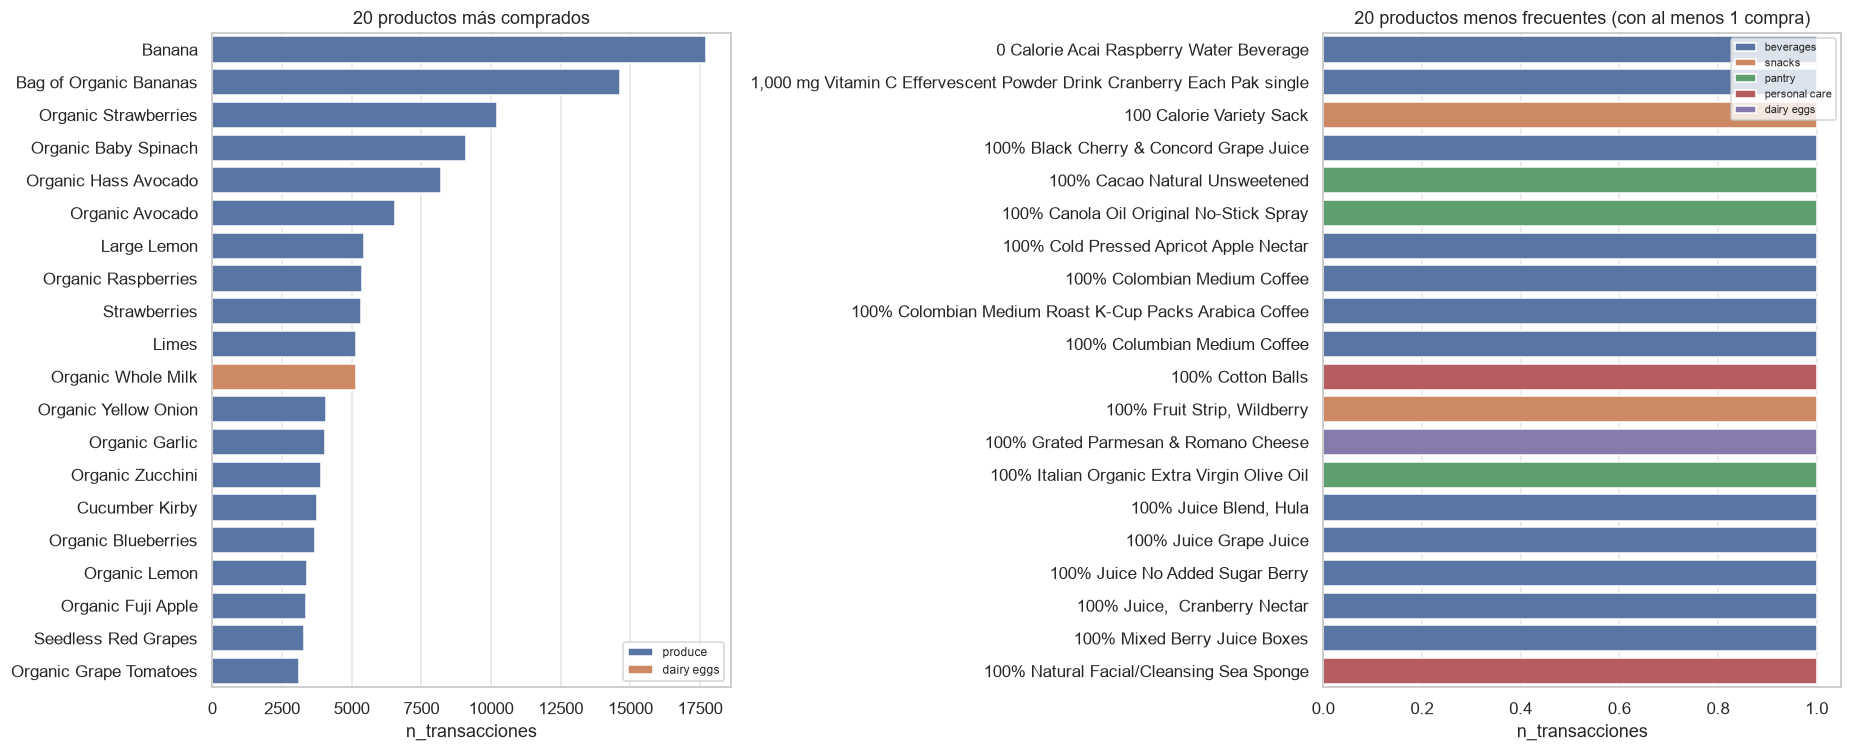

,product_id,product_name,department,n_transacciones,soporte
0,24852,Banana,produce,17705,0.147538
1,13176,Bag of Organic Bananas,produce,14624,0.121864
2,21137,Organic Strawberries,produce,10208,0.085065
3,21903,Organic Baby Spinach,produce,9103,0.075856
4,47209,Organic Hass Avocado,produce,8210,0.068415
5,47766,Organic Avocado,produce,6560,0.054665
6,47626,Large Lemon,produce,5456,0.045466
7,27966,Organic Raspberries,produce,5372,0.044766
8,16797,Strawberries,produce,5330,0.044416
9,26209,Limes,produce,5154,0.042949


,product_id,product_name,department,n_transacciones,soporte
0,14773,0 Calorie Acai Raspberry Water Beverage,beverages,1,0.000008
1,8325,"1,000 mg Vitamin C Effervescent Powder Drink Cranberry Each Pak single",beverages,1,0.000008
2,17238,100 Calorie Variety Sack,snacks,1,0.000008
3,21320,100% Black Cherry & Concord Grape Juice,beverages,1,0.000008
4,44286,100% Cacao Natural Unsweetened,pantry,1,0.000008
5,13473,100% Canola Oil Original No-Stick Spray,pantry,1,0.000008
6,37930,100% Cold Pressed Apricot Apple Nectar,beverages,1,0.000008
7,13327,100% Colombian Medium Coffee,beverages,1,0.000008
8,3031,100% Colombian Medium Roast K-Cup Packs Arabica Coffee,beverages,1,0.000008
9,43173,100% Columbian Medium Coffee,beverages,1,0.000008


Productos con una sola transacción: 6,969 (empates en el último lugar: el orden alfabético solo desempata para mostrar 20).
Productos del catálogo que no aparecen en la muestra: 16,627


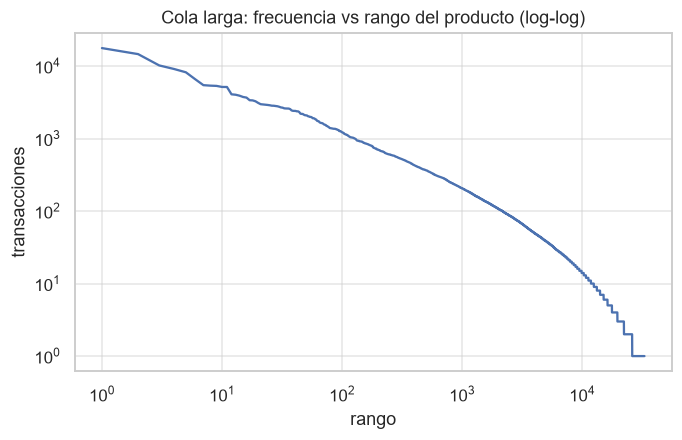

Los 100 productos más vendidos concentran el 23.3% de los artículos comprados.


In [8]:
N_MUESTRA = datos.order_id.nunique()
frec = (datos.groupby(['product_id', 'product_name', 'department'])['order_id'].nunique()
             .rename('n_transacciones').reset_index())
frec['soporte'] = frec.n_transacciones / N_MUESTRA
top20 = frec.nlargest(20, 'n_transacciones')
bottom20 = frec.sort_values(['n_transacciones', 'product_name']).head(20)

fig, ax = plt.subplots(1, 2, figsize=(17, 7))
sns.barplot(data=top20, y='product_name', x='n_transacciones', hue='department', dodge=False, ax=ax[0])
ax[0].set_title('20 productos más comprados'); ax[0].set_ylabel(''); ax[0].legend(fontsize=8)
sns.barplot(data=bottom20, y='product_name', x='n_transacciones', hue='department', dodge=False, ax=ax[1])
ax[1].set_title('20 productos menos frecuentes (con al menos 1 compra)'); ax[1].set_ylabel(''); ax[1].legend(fontsize=7)
plt.tight_layout(); plt.show()

display(top20.reset_index(drop=True))
display(bottom20.reset_index(drop=True))
print(f'Productos con una sola transacción: {(frec.n_transacciones == 1).sum():,} '
      f'(empates en el último lugar: el orden alfabético solo desempata para mostrar 20).')
print(f'Productos del catálogo que no aparecen en la muestra: {len(productos) - len(frec):,}')

r = np.sort(frec.n_transacciones.to_numpy())[::-1]
plt.figure(figsize=(7, 4)); plt.loglog(np.arange(1, len(r) + 1), r)
plt.title('Cola larga: frecuencia vs rango del producto (log-log)'); plt.xlabel('rango'); plt.ylabel('transacciones')
plt.show()
cuota_top = r[:100].sum() / r.sum()
print(f'Los 100 productos más vendidos concentran el {cuota_top:.1%} de los artículos comprados.')

La popularidad tiene una distribución de cola larga. De los 20 productos más comprados, 19 son frutas y verduras (*produce*) y el único que no es la Organic Whole Milk (*dairy eggs*). Arriba de todo están Banana (14.8 % de las canastas) y Bag of Organic Bananas (12.2 %). Los 100 productos más vendidos juntan el 23.3 % de todo lo comprado, mientras que 6,969 productos salen en una sola transacción y 16,627 productos del catálogo ni siquiera aparecen en la muestra. En la gráfica log-log la frecuencia baja casi en línea recta con el rango, como una ley de potencia.

Esto anticipa dos problemas. Los productos populares van a salir como consecuente de muchas reglas con confianza alta aunque no tengan una relación real con el antecedente, y los productos raros casi no van a tener reglas.

## 1.5 Número de productos por transacción

,count,mean,std,min,25%,50%,75%,90%,95%,99%,max
n_productos,120003.0,10.02,7.51,1.0,5.0,8.0,14.0,20.0,25.0,35.0,77.0


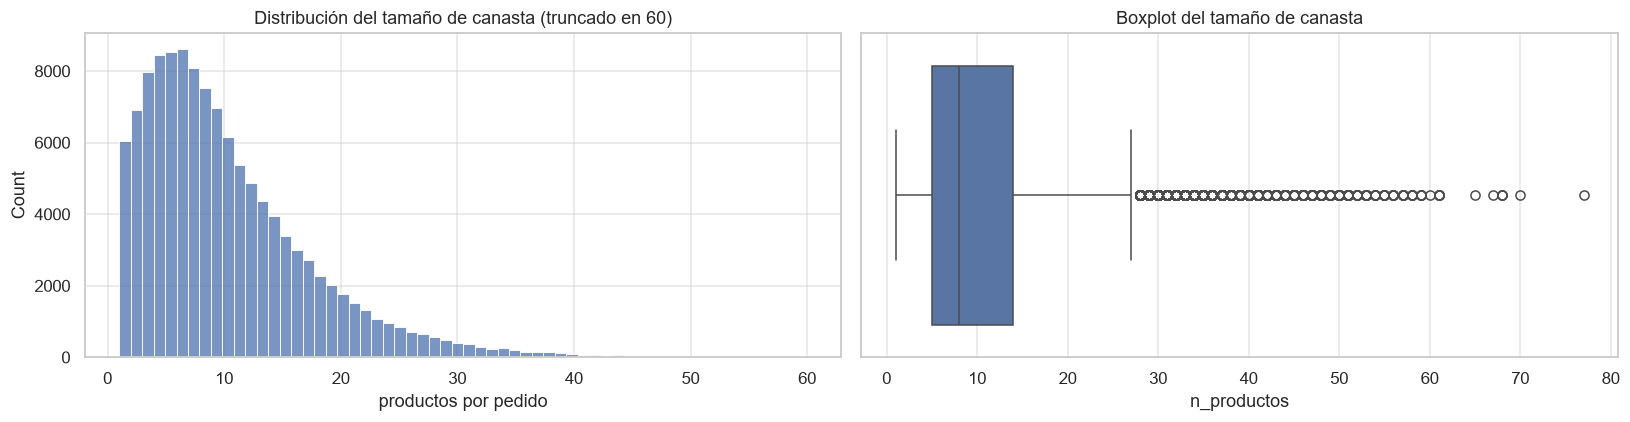

Canastas con 1 solo producto: 5.04%


In [9]:
tam = datos.groupby('order_id').size().rename('n_productos')
display(tam.describe(percentiles=[.25, .5, .75, .9, .95, .99]).to_frame().T.round(2))

fig, ax = plt.subplots(1, 2, figsize=(15, 4))
sns.histplot(tam.clip(upper=60), bins=60, ax=ax[0])
ax[0].set_title('Distribución del tamaño de canasta (truncado en 60)'); ax[0].set_xlabel('productos por pedido')
sns.boxplot(x=tam, ax=ax[1]); ax[1].set_title('Boxplot del tamaño de canasta')
plt.tight_layout(); plt.show()
print(f'Canastas con 1 solo producto: {(tam == 1).mean():.2%}')

## 1.6 Compras atípicas y su tratamiento

Para detectar compras atípicas se usó el criterio de Tukey sobre el tamaño de la canasta, con las cercas de 1.5·IQR (atípico moderado) y 3·IQR (atípico extremo).

Se decidió eliminar solo las canastas que superan Q3 + 3·IQR. Una canasta de *k* productos genera *k(k−1)/2* pares: con 10 productos son 45 pares, pero con 80 ya son 3,160. Unas cuantas canastas gigantes (despensa de oficina, revendedores, compras del mes) inflan la co-ocurrencia de productos que no tienen nada que ver entre sí. Con 1.5·IQR se habrían eliminado compras grandes que en Instacart son normales; con 3·IQR solo salen las extremas.

Las canastas de un solo producto se conservaron. Son compras reales y, aunque no generan reglas, cuentan en el denominador del soporte; quitarlas inflaría todos los soportes. También se verificó que no hubiera pedidos con el mismo producto repetido ni productos fuera del catálogo.

In [10]:
q1, q3 = tam.quantile([.25, .75]); iqr = q3 - q1
lim_15, lim_3, p99 = q3 + 1.5 * iqr, q3 + 3 * iqr, tam.quantile(.99)
display(pd.DataFrame({
    'criterio': ['Q3 + 1.5*IQR', 'Q3 + 3*IQR (elegido)', 'Percentil 99'],
    'límite': [lim_15, lim_3, p99],
    'canastas por encima': [(tam > lim_15).sum(), (tam > lim_3).sum(), (tam > p99).sum()],
    '% de canastas': [(tam > lim_15).mean(), (tam > lim_3).mean(), (tam > p99).mean()]}).round(4))

LIM_ATIPICO = lim_3
atipicas = tam[tam > LIM_ATIPICO].index
pares = tam.astype(float) * (tam - 1) / 2
print(f'Las canastas atípicas son el {len(atipicas)/len(tam):.2%} de las transacciones pero generan el '
      f'{pares.loc[atipicas].sum()/pares.sum():.2%} de todos los pares de productos.')
dep_atip = datos[datos.order_id.isin(atipicas)].groupby('order_id').department.nunique().mean()
dep_norm = datos[~datos.order_id.isin(atipicas)].groupby('order_id').department.nunique().mean()
print(f'Departamentos distintos por canasta: atípicas {dep_atip:.1f} vs normales {dep_norm:.1f}')

dups = datos.duplicated(['order_id', 'product_id']).sum()
sin_cat = datos.product_name.isna().sum()
print(f'Duplicados pedido-producto: {dups} | registros sin producto en catálogo: {sin_cat}')

datos_l = (datos[~datos.order_id.isin(atipicas) & datos.product_name.notna()]
           .drop_duplicates(['order_id', 'product_id']).copy())
N = datos_l.order_id.nunique()
print(f'\nTransacciones tras limpieza: {N:,} (se eliminaron {len(atipicas):,})')
if N < 100_000:
    print('Aviso: hay menos de 100,000 transacciones, hay que aumentar N_ORDENES_OBJETIVO.')

,criterio,límite,canastas por encima,% de canastas
0,Q3 + 1.5*IQR,27.5,3949,0.0329
1,Q3 + 3*IQR (elegido),41.0,470,0.0039
2,Percentil 99,35.0,1172,0.0098


Las canastas atípicas son el 0.39% de las transacciones pero generan el 5.90% de todos los pares de productos.
Departamentos distintos por canasta: atípicas 11.6 vs normales 4.7
Duplicados pedido-producto: 0 | registros sin producto en catálogo: 0

Transacciones tras limpieza: 119,533 (se eliminaron 470)


## 1.7 Preparación para los algoritmos

Cada transacción se representa como el conjunto ordenado de `product_id` del pedido. No se toma en cuenta la cantidad ni el orden en el carrito, porque las reglas de asociación solo consideran si el producto está o no está. Aparte se guarda una tabla `trans` con los datos de cada pedido (usuario, número de pedido, día, hora y tamaño), en el mismo orden que la lista `canastas`.

Las funciones principales (matriz binaria, generación de reglas, métricas y recomendador) se escribieron en el módulo `nucleo_reglas.py`, para usarlas tanto en el notebook como en la aplicación.

In [11]:
%%writefile nucleo_reglas.py
import math
import itertools
from collections import defaultdict

import numpy as np
import pandas as pd
import scipy.sparse as sp
from mlxtend.frequent_patterns import fpgrowth


# Codificación
def matriz_binaria(canastas, items=None, min_conteo=1):
    # Matriz dispersa de transacciones x productos
    todos = np.concatenate(canastas).astype(np.int64)
    if items is None:
        u, c = np.unique(todos, return_counts=True)
        items = u[c >= min_conteo]
    else:
        items = np.unique(np.asarray(items, dtype=np.int64))
    if len(items) == 0:
        return sp.csr_matrix((len(canastas), 0), dtype=bool), items
    filas = np.repeat(np.arange(len(canastas)), [len(x) for x in canastas])
    pos = np.minimum(np.searchsorted(items, todos), len(items) - 1)
    ok = items[pos] == todos
    M = sp.csr_matrix((np.ones(int(ok.sum()), dtype=bool), (filas[ok], pos[ok])),
                      shape=(len(canastas), len(items)))
    return M, items


def a_dataframe(M, items):
    return pd.DataFrame(M.toarray(), columns=[int(i) for i in items])


def conteo_minimo(min_soporte, n):
    # Número mínimo de transacciones equivalente al soporte mínimo
    return max(1, math.ceil(min_soporte * n - 1e-9))


def soporte_efectivo(min_soporte, n):
    # Para que los tres algoritmos usen el mismo umbral entero y no haya diferencias por redondeo
    return (conteo_minimo(min_soporte, n) - 0.5) / n


def normalizar_frecuentes(df_mlxtend):
    return {frozenset(int(x) for x in s): float(v)
            for s, v in zip(df_mlxtend['itemsets'], df_mlxtend['support'])}


# Reglas y métricas
def agregar_metricas(df):
    sa = df['soporte_antecedente'].to_numpy(float)
    sc = df['soporte_consecuente'].to_numpy(float)
    s = df['soporte'].to_numpy(float)
    conf = df['confianza'].to_numpy(float)
    df['lift'] = conf / sc
    df['leverage'] = s - sa * sc
    with np.errstate(divide='ignore', invalid='ignore'):
        df['conviction'] = np.where(conf < 1, (1 - sc) / (1 - conf), np.inf)
    df['jaccard'] = s / (sa + sc - s)
    df['len_antecedente'] = df['antecedente'].map(len).astype(int)
    df['len_consecuente'] = df['consecuente'].map(len).astype(int)
    return df


def generar_reglas(frecuentes, conf_min=0.0, solo_consecuente_unitario=False):
    # Genera A -> C para cada conjunto frecuente (A u C) y cada partición no vacía
    filas = []
    for itemset, s_ac in frecuentes.items():
        k = len(itemset)
        if k < 2:
            continue
        elems = sorted(itemset)
        for r in range(1, k):
            if solo_consecuente_unitario and k - r != 1:
                continue
            for ant in itertools.combinations(elems, r):
                ant_f = frozenset(ant)
                cons_f = itemset - ant_f
                s_a, s_c = frecuentes[ant_f], frecuentes[cons_f]
                conf = s_ac / s_a
                if conf < conf_min:
                    continue
                filas.append((tuple(ant), tuple(sorted(cons_f)), s_a, s_c, s_ac, conf))
    cols = ['antecedente', 'consecuente', 'soporte_antecedente', 'soporte_consecuente', 'soporte', 'confianza']
    return agregar_metricas(pd.DataFrame(filas, columns=cols))


def calcular_mejora(reglas, frecuentes):
    # mejora(A->C) = conf(A->C) - max conf(A'->C) con A' subconjunto propio no vacío de A
    out = []
    for a, c, conf in zip(reglas['antecedente'], reglas['consecuente'], reglas['confianza']):
        if len(a) < 2:
            out.append(np.nan)
            continue
        cf, mejor = frozenset(c), 0.0
        for r in range(1, len(a)):
            for sub in itertools.combinations(a, r):
                sf = frozenset(sub)
                mejor = max(mejor, frecuentes[sf | cf] / frecuentes[sf])
        out.append(conf - mejor)
    return np.array(out, dtype=float)


def frecuentes_fpgrowth(canastas, min_soporte, max_len=None):
    n = len(canastas)
    M, items = matriz_binaria(canastas, min_conteo=conteo_minimo(min_soporte, n))
    if M.shape[1] == 0:
        return {}
    r = fpgrowth(a_dataframe(M, items), min_support=soporte_efectivo(min_soporte, n),
                 use_colnames=True, max_len=max_len)
    return normalizar_frecuentes(r)


def minar(canastas, min_soporte, conf_min=0.0, max_len=3, solo_consecuente_unitario=False):
    fr = frecuentes_fpgrowth(canastas, min_soporte, max_len=max_len)
    reglas = generar_reglas(fr, conf_min, solo_consecuente_unitario)
    reglas['n_transacciones'] = np.rint(reglas['soporte'].to_numpy(float) * len(canastas)).astype(int)
    return reglas, fr


# Base de reglas del recomendador
def _top_por_grupo(grupo, valor, k):
    # Máscara con los k mayores valores de cada grupo
    orden = np.lexsort((-valor, grupo))
    g = grupo[orden]
    inicio = np.r_[0, np.flatnonzero(np.diff(g)) + 1]
    rango = np.arange(len(g)) - np.repeat(inicio, np.diff(np.r_[inicio, len(g)]))
    m = np.zeros(len(grupo), dtype=bool)
    m[orden[rango < k]] = True
    return m


def reglas_pares(canastas, min_conteo_par=5, top_k_conf=None, top_k_lift=None):
    # Todas las reglas 1 -> 1 cuyo par co-ocurre >= min_conteo_par veces
    n = len(canastas)
    M, items = matriz_binaria(canastas, min_conteo=min_conteo_par)
    Mi = M.astype(np.int32)
    del M
    cnt = np.asarray(Mi.sum(axis=0)).ravel()
    C = (Mi.T @ Mi).tocoo()
    del Mi
    m = (C.row != C.col) & (C.data >= min_conteo_par)
    i, j, cij = C.row[m], C.col[m], C.data[m].astype(float)
    del C, m
    if top_k_conf is not None or top_k_lift is not None:
        conf = cij / cnt[i]
        lift = conf / (cnt[j] / n)
        keep = np.zeros(len(i), dtype=bool)
        if top_k_conf:
            keep |= _top_por_grupo(i, conf, top_k_conf)
        if top_k_lift:
            keep |= _top_por_grupo(i, lift, top_k_lift)
        i, j, cij = i[keep], j[keep], cij[keep]
    df = pd.DataFrame({'antecedente': [(int(x),) for x in items[i]],
                       'consecuente': [(int(x),) for x in items[j]],
                       'soporte_antecedente': cnt[i] / n, 'soporte_consecuente': cnt[j] / n,
                       'soporte': cij / n, 'confianza': cij / cnt[i]})
    return agregar_metricas(df)


def construir_base(canastas, soporte_itemsets, min_conteo_par, max_len=3, top_k_conf=None, top_k_lift=None,
                   minador=None):
    # Base = reglas 1->1 (pares) + reglas con antecedente de 2 productos
    pares = reglas_pares(canastas, min_conteo_par, top_k_conf, top_k_lift)
    if minador is None:
        fr = frecuentes_fpgrowth(canastas, soporte_itemsets, max_len=max_len)
    else:
        fr = minador(canastas, soporte_itemsets, max_len)
    multi = generar_reglas(fr, 0.0, solo_consecuente_unitario=True)
    multi = multi[multi['len_antecedente'] >= 2]
    base = pd.concat([pares, multi], ignore_index=True)
    base['consecuente'] = base['consecuente'].map(lambda t: int(t[0]))
    base['n_transacciones'] = np.rint(base['soporte'].to_numpy(float) * len(canastas)).astype(int)
    return base.reset_index(drop=True)


def recomendar_populares(populares, seleccion, k=5):
    sel, out = set(int(x) for x in seleccion), []
    for p in populares:
        if p not in sel:
            out.append(int(p))
            if len(out) == k:
                break
    return out


class Recomendador:
    # Recomienda los consecuentes de las reglas cuyo antecedente está contenido en la selección

    def __init__(self, base, populares):
        self.base = base.reset_index(drop=True)
        self.ant = list(self.base['antecedente'])
        self.len_ant = self.base['len_antecedente'].to_numpy()
        self.ant_set = {int(k): frozenset(self.ant[k]) for k in np.flatnonzero(self.len_ant > 1)}
        self.cons = self.base['consecuente'].to_numpy(np.int64)
        self.sup = self.base['soporte'].to_numpy(float)
        self.conf = self.base['confianza'].to_numpy(float)
        self.lift = self.base['lift'].to_numpy(float)
        self.lev = self.base['leverage'].to_numpy(float)
        idx = defaultdict(list)
        for k, a in enumerate(self.ant):
            for it in a:
                idx[it].append(k)
        self.indice = {it: np.array(v, dtype=np.int64) for it, v in idx.items()}
        self.populares = [int(x) for x in populares]
        self.items_con_reglas = set(self.indice)

    def candidatos(self, sel):
        listas = [self.indice[i] for i in sel if i in self.indice]
        if not listas:
            return np.empty(0, dtype=np.int64)
        idx = np.unique(np.concatenate(listas))
        multi = np.flatnonzero(self.len_ant[idx] > 1)
        if len(multi):
            ok = np.ones(len(idx), dtype=bool)
            for p in multi:
                ok[p] = self.ant_set[idx[p]] <= sel
            idx = idx[ok]
        return idx

    def recomendar(self, seleccion, k=5, min_soporte=0.0, min_confianza=0.0, min_lift=0.0,
                   criterio='confianza', rellenar=False):
        sel = frozenset(int(x) for x in seleccion)
        idx = self.candidatos(sel)
        resultado = []
        if len(idx):
            m = ((self.sup[idx] >= min_soporte) & (self.conf[idx] >= min_confianza)
                 & (self.lift[idx] >= min_lift) & ~np.isin(self.cons[idx], list(sel)))
            idx = idx[m]
        if len(idx):
            clave = {'confianza': self.conf, 'lift': self.lift, 'leverage': self.lev}[criterio]
            idx = idx[np.lexsort((-self.lift[idx], -self.conf[idx], -clave[idx]))]
            _, primeros = np.unique(self.cons[idx], return_index=True)
            for r in idx[np.sort(primeros)][:k]:
                resultado.append({'producto': int(self.cons[r]), 'regla': int(r), 'origen': 'reglas'})
        if rellenar and len(resultado) < k:
            ya = set(sel) | {d['producto'] for d in resultado}
            for p in self.populares:
                if p not in ya:
                    resultado.append({'producto': p, 'regla': None, 'origen': 'popularidad'})
                    ya.add(p)
                    if len(resultado) >= k:
                        break
        return resultado

    def recomendar_ids(self, seleccion, k=5, **kw):
        return [d['producto'] for d in self.recomendar(seleccion, k, **kw)]

Overwriting nucleo_reglas.py


In [12]:
import nucleo_reglas
importlib.reload(nucleo_reglas)
from nucleo_reglas import *

# Transacciones alineadas con la tabla de contexto
datos_l = datos_l.sort_values(['order_id', 'product_id'])
oid = datos_l.order_id.to_numpy()
pid = datos_l.product_id.to_numpy().astype(np.int64)
cortes = np.flatnonzero(np.diff(oid)) + 1
canastas = np.split(pid, cortes)
ids_orden = oid[np.r_[0, cortes]]

trans = (datos_l.groupby('order_id')
         .agg(user_id=('user_id', 'first'), order_number=('order_number', 'first'),
              dow=('order_dow', 'first'), hora=('order_hour_of_day', 'first'),
              n_productos=('product_id', 'size'), prop_recompra=('reordered', 'mean'))
         .reset_index())
assert (trans.order_id.to_numpy() == ids_orden).all()

nombre_prod = dict(zip(productos.product_id.astype(int), productos.product_name))
depto_prod = dict(zip(productos.product_id.astype(int), productos.department))
nombre_depto = dict(zip(departments.department_id.astype(int), departments.department))

ids_u, cnt_u = np.unique(np.concatenate(canastas), return_counts=True)
frec_l = pd.DataFrame({'product_id': ids_u, 'n_transacciones': cnt_u})
frec_l['soporte'] = frec_l.n_transacciones / N
frec_l['product_name'] = frec_l.product_id.map(nombre_prod)
populares_all = frec_l.sort_values('n_transacciones', ascending=False, kind='stable').product_id.to_numpy()

print(f'{len(canastas):,} transacciones | {len(ids_u):,} productos distintos')
print('Ejemplo:', [nombre_prod[int(i)] for i in canastas[0]])

119,533 transacciones | 32,886 productos distintos
Ejemplo: ['Honeysuckle Hand Soap', 'Pinto Beans No Salt Added', 'Spring Water', 'Organic Extra Virgin Olive Oil', 'Olive Oil & Aloe Vera Hand Soap']


### 1.8 Partición por usuario (se usa en las Partes 5, 7 y 8)

Los pedidos de cada usuario se ordenan por `order_number`. El primer 70 % (redondeando hacia arriba) va a entrenamiento y el resto a prueba. Así se respeta el orden en el tiempo y el sistema se evalúa con compras que el usuario hizo después de las que vio.

In [13]:
trans['pos_usuario'] = trans.groupby('user_id')['order_number'].rank(method='first')
trans['n_ord_usuario'] = trans.groupby('user_id')['order_id'].transform('size')
trans['conjunto'] = np.where(trans.pos_usuario <= np.ceil(PROP_ENTRENAMIENTO * trans.n_ord_usuario), 'train', 'test')
idx_train = np.flatnonzero(trans.conjunto.eq('train').to_numpy())
idx_test = np.flatnonzero(trans.conjunto.eq('test').to_numpy())
canastas_train = [canastas[i] for i in idx_train]
canastas_test = [canastas[i] for i in idx_test]
print(trans.conjunto.value_counts().to_string())
print(f'Proporción de entrenamiento: {len(idx_train)/len(trans):.1%}')

# Ningún pedido de prueba es anterior a uno de entrenamiento del mismo usuario
chk = trans.groupby(['user_id', 'conjunto']).order_number.agg(['min', 'max']).unstack()
ok = (chk[('max', 'train')] < chk[('min', 'test')]) | chk[('min', 'test')].isna()
print(f'Usuarios con secuencia respetada: {ok.mean():.1%}')

conjunto
train    86932
test     32601
Proporción de entrenamiento: 72.7%
Usuarios con secuencia respetada: 100.0%


En resumen, en la Parte 1 se muestrearon usuarios completos (más de 100 mil transacciones), se eliminaron las canastas extremas (Q3 + 3·IQR), se conservaron las canastas de un producto, se revisaron duplicados, se representaron las canastas como presencia/ausencia y se separó 70/30 por usuario respetando el orden de los pedidos.

# Parte 2. Implementación y comparación de algoritmos

## Cómo funciona cada algoritmo

**Apriori** busca en anchura y trabaja con las transacciones en formato horizontal.
1. Cuenta los productos individuales y se queda con los que pasan el soporte mínimo (L₁).
2. En el nivel *k* arma candidatos de tamaño *k* uniendo conjuntos frecuentes de tamaño *k−1* que comparten prefijo.
3. Poda los candidatos que tengan algún subconjunto de tamaño *k−1* que no sea frecuente. Esto se puede por la propiedad antimonótona: si un conjunto no es frecuente, ninguno de sus superconjuntos lo es.
4. Recorre la base de datos para contar el soporte de los candidatos y repite hasta que ya no salgan más.

Su problema es que el número de candidatos se dispara al bajar el soporte (con *m* productos frecuentes puede haber hasta *m(m−1)/2* pares) y que tiene que leer los datos una vez por cada nivel.

**FP-Growth** no genera candidatos.
1. En una primera pasada cuenta los productos y los ordena de más a menos frecuente.
2. En la segunda pasada mete cada transacción (solo con sus productos frecuentes y en ese orden) en un FP-tree. Es un árbol de prefijos donde las transacciones que empiezan igual comparten rama, así que la base de datos queda comprimida.
3. Para cada producto, del menos al más frecuente, saca su base de patrones condicional (los caminos que llegan a él), arma un FP-tree condicional y mina de forma recursiva.

Solo lee los datos dos veces y escala mejor con soportes bajos, a cambio de la memoria que ocupa el árbol.

**Eclat** (implementación propia) busca en profundidad y usa formato vertical.
1. Pasa los datos a formato vertical: para cada producto guarda el conjunto de transacciones donde aparece (*tidset*).
2. El soporte de un conjunto es el tamaño de la intersección de los tidsets de sus productos, así que no hay que volver a leer los datos.
3. Recorre en profundidad por clases de equivalencia de prefijo. Para el prefijo {a}, intersecta su tidset con el de cada producto que va después; los que pasan el soporte forman la clase de {a} y se procesan recursivamente.

En esta implementación cada tidset es un bitset, o sea un entero de Python con un bit por transacción. La intersección queda como un `AND` y el soporte como un `popcount`, y las dos operaciones corren en C sobre miles de bits a la vez. Además, los productos se ordenan de menor a mayor soporte para que las primeras clases sean pequeñas.

Los tres reciben las mismas transacciones y la misma matriz. Antes se eliminan los productos con soporte menor al más bajo de los soportes que se van a probar. Esto no cambia el resultado, porque un producto que no es frecuente nunca puede estar en un conjunto frecuente.

In [14]:
N_TOT = len(canastas)
M_alg, items_alg = matriz_binaria(canastas, min_conteo=conteo_minimo(min(SOPORTES), N_TOT))
df_alg = a_dataframe(M_alg, items_alg)
print(f'Matriz para los algoritmos: {df_alg.shape[0]:,} transacciones x {df_alg.shape[1]:,} productos '
      f'({df_alg.memory_usage().sum()/2**20:.1f} MB como DataFrame booleano)')

Matriz para los algoritmos: 119,533 transacciones x 502 productos (57.2 MB como DataFrame booleano)


In [15]:
def popcount(x):
    return x.bit_count()

if not hasattr(int, 'bit_count'):  # Python < 3.10
    def popcount(x):
        return bin(x).count('1')


def _bitset(tids, n):
    b = np.zeros(n, dtype=bool)
    b[tids] = True
    return int.from_bytes(np.packbits(b, bitorder='little').tobytes(), 'little')


def eclat_propio(M, items, min_soporte, max_len=None):
    # Eclat con tidsets como bitsets
    n = M.shape[0]
    minc = conteo_minimo(min_soporte, n)
    C = M.tocsc()
    conteos = np.diff(C.indptr)
    # 1) Formato vertical: item -> bitset de transacciones
    nivel1 = []
    for j in np.flatnonzero(conteos >= minc):
        tids = C.indices[C.indptr[j]:C.indptr[j + 1]]
        nivel1.append((int(items[j]), _bitset(tids, n), int(conteos[j])))
    nivel1.sort(key=lambda t: t[2])  # soporte ascendente, así las primeras clases son chicas
    frecuentes = {}

    # 2) Búsqueda en profundidad por clases de equivalencia de prefijo
    def dfs(prefijo, clase):
        for i, (it, bits, c) in enumerate(clase):
            nuevo = prefijo + (it,)
            frecuentes[frozenset(nuevo)] = c / n
            if max_len and len(nuevo) >= max_len:
                continue
            sub = []
            for it2, bits2, _ in clase[i + 1:]:
                inter = bits & bits2  # intersección de tidsets
                cc = popcount(inter)  # soporte absoluto
                if cc >= minc:
                    sub.append((it2, inter, cc))
            if sub:
                dfs(nuevo, sub)

    dfs((), nivel1)
    return frecuentes


# Validación rápida contra un ejemplo pequeño hecho a mano
_mini = [np.array([1, 2, 3]), np.array([1, 2]), np.array([2, 3]), np.array([1, 3]), np.array([1, 2, 3])]
_M, _it = matriz_binaria(_mini)
_r = eclat_propio(_M, _it, 0.6)
print({tuple(sorted(k)): round(v, 2) for k, v in _r.items()})  # esperado: {1}, {2}, {3} 0.8 y cada par 0.6

{(1,): 0.8, (1, 2): 0.6, (1, 3): 0.6, (2,): 0.8, (2, 3): 0.6, (3,): 0.8}


### Medición

El tiempo se mide con `time.perf_counter()` justo alrededor de la llamada al algoritmo, sin contar la construcción de la matriz, que es igual para los tres. Para la memoria máxima se usa `tracemalloc`, que registra el pico de memoria de Python y NumPy. Esa medición se hace en una segunda corrida aparte, porque `tracemalloc` hace más lento el código y alteraría el tiempo. Los tres algoritmos usan el mismo umbral entero de conteo (`soporte_efectivo`), para que ninguna diferencia venga del redondeo.

In [16]:
def medir(fn, *args):
    gc.collect()
    t0 = time.perf_counter(); res = fn(*args); t = time.perf_counter() - t0
    gc.collect()
    tracemalloc.start(); fn(*args); _, pico = tracemalloc.get_traced_memory(); tracemalloc.stop()
    return res, t, pico / 2**20

ALGORITMOS = {
    'Apriori': lambda s: normalizar_frecuentes(apriori(df_alg, min_support=soporte_efectivo(s, N_TOT),
                                                       use_colnames=True, low_memory=True)),
    'FP-Growth': lambda s: normalizar_frecuentes(fpgrowth(df_alg, min_support=soporte_efectivo(s, N_TOT),
                                                          use_colnames=True)),
    'Eclat (propio)': lambda s: eclat_propio(M_alg, items_alg, s),
}

filas, resultados_alg = [], {}
for s in SOPORTES:
    for nombre, fn in ALGORITMOS.items():
        res, t, mem = medir(fn, s)
        resultados_alg[(nombre, s)] = res
        largos = Counter(len(x) for x in res)
        filas.append({'algoritmo': nombre, 'soporte_min': s, 'conteo_min': conteo_minimo(s, N_TOT),
                      'tiempo_s': t, 'memoria_pico_MB': mem, 'n_conjuntos': len(res),
                      'max_longitud': max(largos) if largos else 0,
                      **{f'k={k}': v for k, v in sorted(largos.items())}})
        print(f's={s:<7} {nombre:15s} {t:9.3f} s  {mem:9.1f} MB  {len(res):6d} conjuntos')

comp = pd.DataFrame(filas).fillna(0)
comp.to_csv(os.path.join(DIR_SALIDA, 'comparacion_algoritmos.csv'), index=False)
display(comp.round(4))

s=0.02    Apriori             0.445 s        9.9 MB      39 conjuntos
s=0.02    FP-Growth           0.811 s        7.8 MB      39 conjuntos
s=0.02    Eclat (propio)      0.008 s        3.2 MB      39 conjuntos
s=0.01    Apriori             0.728 s       10.4 MB     116 conjuntos
s=0.01    FP-Growth           0.845 s       28.7 MB     116 conjuntos
s=0.01    Eclat (propio)      0.032 s        4.6 MB     116 conjuntos
s=0.0075  Apriori             0.796 s       10.8 MB     170 conjuntos
s=0.0075  FP-Growth           0.832 s       39.7 MB     170 conjuntos
s=0.0075  Eclat (propio)      0.092 s        6.3 MB     170 conjuntos
s=0.005   Apriori             1.159 s       11.8 MB     316 conjuntos
s=0.005   FP-Growth           1.093 s       60.0 MB     316 conjuntos
s=0.005   Eclat (propio)      0.211 s        7.9 MB     316 conjuntos
s=0.003   Apriori             2.220 s       13.9 MB     784 conjuntos
s=0.003   FP-Growth           1.817 s       95.5 MB     784 conjuntos
s=0.003   Eclat (pro

,algoritmo,soporte_min,conteo_min,tiempo_s,memoria_pico_MB,n_conjuntos,max_longitud,k=1,k=2,k=3
0,Apriori,0.0200,2391,0.4455,9.8510,39,2,38,1,0.0
1,FP-Growth,0.0200,2391,0.8111,7.8308,39,2,38,1,0.0
2,Eclat (propio),0.0200,2391,0.0082,3.1573,39,2,38,1,0.0
3,Apriori,0.0100,1196,0.7281,10.4330,116,2,100,16,0.0
4,FP-Growth,0.0100,1196,0.8445,28.6776,116,2,100,16,0.0
5,Eclat (propio),0.0100,1196,0.0318,4.6317,116,2,100,16,0.0
6,Apriori,0.0075,897,0.7963,10.7557,170,2,143,27,0.0
7,FP-Growth,0.0075,897,0.8324,39.7413,170,2,143,27,0.0
8,Eclat (propio),0.0075,897,0.0918,6.2918,170,2,143,27,0.0
9,Apriori,0.0050,598,1.1586,11.8226,316,2,244,72,0.0


s=0.02    FP-Growth vs Apriori         mismos conjuntos: True | máx. diferencia de soporte: 0.00e+00
s=0.02    FP-Growth vs Eclat (propio)  mismos conjuntos: True | máx. diferencia de soporte: 0.00e+00
s=0.01    FP-Growth vs Apriori         mismos conjuntos: True | máx. diferencia de soporte: 0.00e+00
s=0.01    FP-Growth vs Eclat (propio)  mismos conjuntos: True | máx. diferencia de soporte: 0.00e+00
s=0.0075  FP-Growth vs Apriori         mismos conjuntos: True | máx. diferencia de soporte: 0.00e+00
s=0.0075  FP-Growth vs Eclat (propio)  mismos conjuntos: True | máx. diferencia de soporte: 0.00e+00
s=0.005   FP-Growth vs Apriori         mismos conjuntos: True | máx. diferencia de soporte: 0.00e+00
s=0.005   FP-Growth vs Eclat (propio)  mismos conjuntos: True | máx. diferencia de soporte: 0.00e+00
s=0.003   FP-Growth vs Apriori         mismos conjuntos: True | máx. diferencia de soporte: 0.00e+00
s=0.003   FP-Growth vs Eclat (propio)  mismos conjuntos: True | máx. diferencia de soporte:

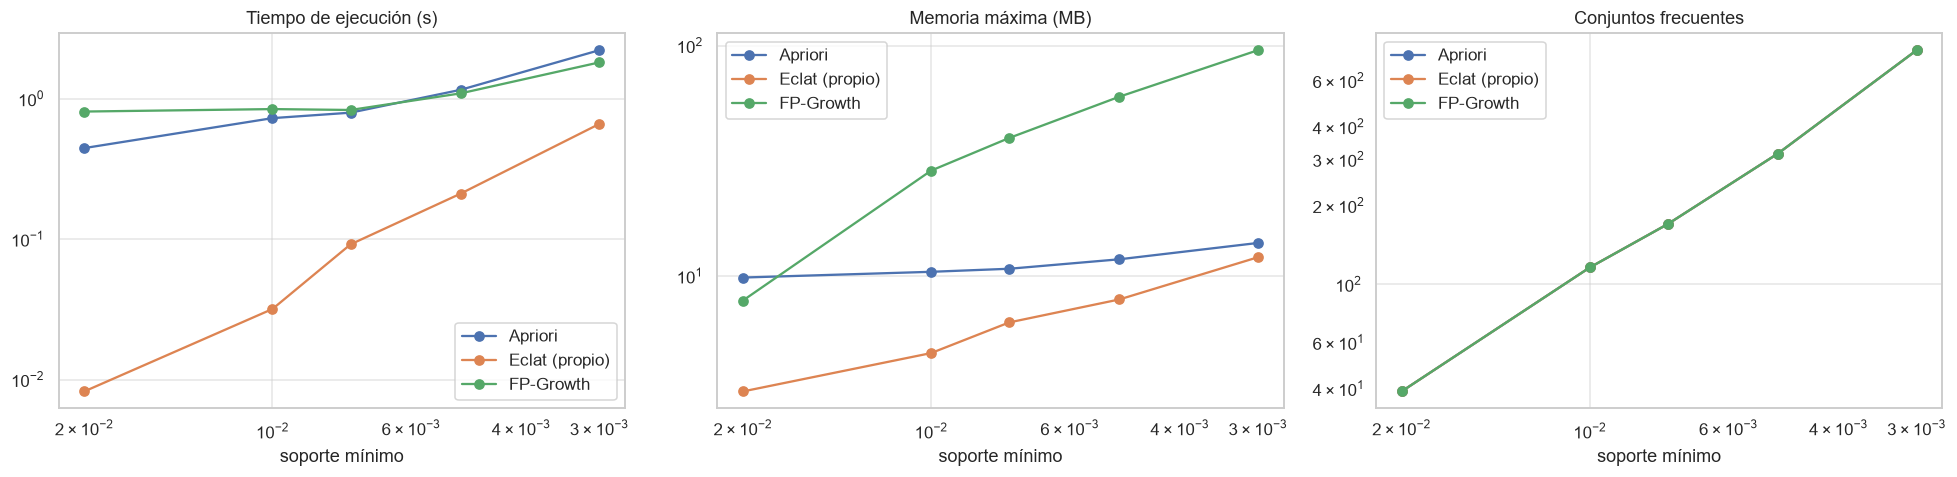

Tiempo (s):


algoritmo,Apriori,Eclat (propio),FP-Growth
soporte_min,,,
0.0200,0.445,0.008,0.811
0.0100,0.728,0.032,0.845
0.0075,0.796,0.092,0.832
0.0050,1.159,0.211,1.093
0.0030,2.220,0.662,1.817


Memoria pico (MB):


algoritmo,Apriori,Eclat (propio),FP-Growth
soporte_min,,,
0.0200,9.9,3.2,7.8
0.0100,10.4,4.6,28.7
0.0075,10.8,6.3,39.7
0.0050,11.8,7.9,60.0
0.0030,13.9,12.1,95.5


soporte 0.02: más rápido = Eclat (propio), menos memoria = Eclat (propio), Apriori/FP-Growth = 0.5x
soporte 0.01: más rápido = Eclat (propio), menos memoria = Eclat (propio), Apriori/FP-Growth = 0.9x
soporte 0.0075: más rápido = Eclat (propio), menos memoria = Eclat (propio), Apriori/FP-Growth = 1.0x
soporte 0.005: más rápido = Eclat (propio), menos memoria = Eclat (propio), Apriori/FP-Growth = 1.1x
soporte 0.003: más rápido = Eclat (propio), menos memoria = Eclat (propio), Apriori/FP-Growth = 1.2x


In [17]:
# Verificación: los tres algoritmos deben encontrar exactamente los mismos conjuntos y soportes
for s in SOPORTES:
    ref = resultados_alg[('FP-Growth', s)]
    for nombre in ['Apriori', 'Eclat (propio)']:
        otro = resultados_alg[(nombre, s)]
        iguales = set(ref) == set(otro)
        dif = max((abs(ref[k] - otro[k]) for k in ref if k in otro), default=0)
        print(f's={s:<7} FP-Growth vs {nombre:15s} mismos conjuntos: {iguales} | máx. diferencia de soporte: {dif:.2e}')

fig, ax = plt.subplots(1, 3, figsize=(18, 4.5))
for nombre, g in comp.groupby('algoritmo'):
    ax[0].plot(g.soporte_min, g.tiempo_s, marker='o', label=nombre)
    ax[1].plot(g.soporte_min, g.memoria_pico_MB, marker='o', label=nombre)
    ax[2].plot(g.soporte_min, g.n_conjuntos, marker='o', label=nombre)
for a, t in zip(ax, ['Tiempo de ejecución (s)', 'Memoria máxima (MB)', 'Conjuntos frecuentes']):
    a.set_xscale('log'); a.set_yscale('log'); a.invert_xaxis(); a.set_xlabel('soporte mínimo'); a.set_title(t); a.legend()
plt.tight_layout(); plt.show()

piv_t = comp.pivot(index='soporte_min', columns='algoritmo', values='tiempo_s').sort_index(ascending=False)
piv_m = comp.pivot(index='soporte_min', columns='algoritmo', values='memoria_pico_MB').sort_index(ascending=False)
print('Tiempo (s):'); display(piv_t.round(3))
print('Memoria pico (MB):'); display(piv_m.round(1))
for s in piv_t.index:
    print(f'soporte {s}: más rápido = {piv_t.loc[s].idxmin()}, menos memoria = {piv_m.loc[s].idxmin()}, '
          f'Apriori/FP-Growth = {piv_t.loc[s, "Apriori"]/piv_t.loc[s, "FP-Growth"]:.1f}x')

### Análisis de las diferencias

En los cinco soportes los tres algoritmos encontraron exactamente los mismos conjuntos con el mismo soporte (diferencia máxima 0). Con eso se comprueba que la implementación de Eclat es correcta, y que lo único que cambia entre ellos es la eficiencia.

Al bajar el soporte de 0.02 a 0.003, los conjuntos frecuentes pasan de 39 a 784 (20 veces más) y aparecen los primeros de 3 productos. Apriori pasa de 0.43 s a 2.91 s y FP-Growth de 0.78 s a 2.04 s.

Con soportes altos (0.02 y 0.0075) Apriori fue más rápido que FP-Growth, porque hay pocos candidatos y pesa más el costo fijo de armar el FP-tree. Con soportes bajos FP-Growth le gana (1.3 veces más rápido en 0.005 y 1.4 en 0.003), que es lo que dice la teoría. Pero FP-Growth es el que más memoria usa: 95.5 MB en 0.003 contra 13.9 MB de Apriori con `low_memory=True`, porque tiene que guardar el árbol y los árboles condicionales.

Eclat fue el más rápido y el que menos memoria usó en todos los soportes. En 0.003 tardó 0.76 s con 12.1 MB, 2.7 veces más rápido que FP-Growth y 3.8 veces más que Apriori. Las intersecciones de bitsets (`AND` y `popcount` en C) le ahorran volver a recorrer las transacciones. Su ventaja contra Apriori sí se va reduciendo al bajar el soporte (de unas 66 veces a 3.8), porque crece el número de tidsets intermedios.

Hay que tomar en cuenta que la comparación depende de cómo está programado cada uno: mlxtend trabaja sobre un DataFrame booleano denso y Eclat sobre bitsets compactos. Con soportes mucho más bajos la memoria de Eclat también subiría.

# Parte 3. Generación de reglas de asociación

Las reglas se generaron con FP-Growth sobre todas las transacciones limpias. Por cada conjunto frecuente *X* y cada forma de partirlo en *X = A ∪ C* se obtiene la regla *A → C*. A cada regla se le calcularon estas métricas:

| Métrica | Fórmula | Qué mide |
|---|---|---|
| Soporte | P(A ∪ C) | Qué tan común es el patrón completo |
| Confianza | P(C ∣ A) | Probabilidad de comprar C si se compró A |
| Lift | conf / P(C) | Cuántas veces más probable es C dado A que en general (1 = independencia) |
| Leverage | P(A ∪ C) − P(A)·P(C) | Diferencia absoluta respecto a la independencia |
| Conviction | (1 − P(C)) / (1 − conf) | Cuánto más se equivocaría la regla si A y C fueran independientes (∞ si conf = 1) |
| Jaccard | P(A ∪ C) / (P(A) + P(C) − P(A ∪ C)) | Similitud entre los conjuntos de transacciones de A y de C |

Si con el soporte inicial salen menos de 100 reglas, el soporte se reduce un 25 % cada vez hasta llegar a 100.

In [18]:
sop = SOPORTE_REGLAS
while True:
    reglas, frec_reglas = minar(canastas, sop, conf_min=CONF_MIN_REGLAS, max_len=4)
    print(f'soporte mínimo = {sop:.5f}: {len(frec_reglas):,} conjuntos frecuentes, {len(reglas):,} reglas '
          f'(confianza >= {CONF_MIN_REGLAS})')
    if len(reglas) >= 100 or sop <= 2.5e-4:
        break
    sop = round(sop * 0.75, 6)
SOPORTE_REGLAS_USADO = sop
reglas['mejora'] = calcular_mejora(reglas, frec_reglas)
reglas['redundante'] = reglas.mejora < MEJORA_MIN


def nombre_corto(i, dic=None, n=30):
    s = (dic or nombre_prod).get(int(i), str(i))
    return s if len(s) <= n else s[:n - 3] + '...'

def texto_items(t, dic=None, corto=False):
    dic = dic or nombre_prod
    return ', '.join(nombre_corto(i, dic) if corto else dic.get(int(i), str(i)) for i in t)

def texto_regla(a, c, dic=None, corto=False):
    if not isinstance(c, (tuple, list)):
        c = (c,)
    return '{' + texto_items(a, dic, corto) + '} → {' + texto_items(c, dic, corto) + '}'

def deptos_de(t):
    if not isinstance(t, (tuple, list)):
        t = (t,)
    return sorted({depto_prod.get(int(i), '?') for i in t})

def decorar(df, dic=None):
    df = df.copy()
    df.insert(0, 'regla', [texto_regla(a, c, dic) for a, c in zip(df.antecedente, df.consecuente)])
    if dic is None:
        df['depto_antecedente'] = [', '.join(deptos_de(a)) for a in df.antecedente]
        df['depto_consecuente'] = [', '.join(deptos_de(c)) for c in df.consecuente]
    return df

COLS = ['regla', 'soporte', 'confianza', 'lift', 'leverage', 'conviction', 'jaccard', 'n_transacciones']
def ver(df, cols=COLS, n=None):
    d = df[cols] if n is None else df[cols].head(n)
    display(d.reset_index(drop=True).round(4))

reglas = decorar(reglas)
print(f'Reglas: {len(reglas):,} | antecedente de 1: {(reglas.len_antecedente == 1).sum():,} | '
      f'de 2+: {(reglas.len_antecedente >= 2).sum():,} | redundantes: {reglas.redundante.sum():,}')
display(reglas[['soporte', 'confianza', 'lift', 'leverage', 'jaccard']].describe().round(4))

soporte mínimo = 0.00200: 1,403 conjuntos frecuentes, 905 reglas (confianza >= 0.05)
Reglas: 905 | antecedente de 1: 836 | de 2+: 69 | redundantes: 8


,soporte,confianza,lift,leverage,jaccard
count,905.0000,905.0000,905.0000,905.0000,905.0000
mean,0.0038,0.1493,2.9613,0.0020,0.0425
std,0.0025,0.0806,3.7399,0.0014,0.0220
min,0.0020,0.0503,0.8196,-0.0010,0.0129
25%,0.0024,0.0839,1.8093,0.0013,0.0296
50%,0.0030,0.1336,2.3241,0.0017,0.0394
75%,0.0041,0.1954,3.1071,0.0023,0.0494
max,0.0204,0.4511,46.6506,0.0123,0.2211


In [19]:
# Exportación del CSV de reglas (entregable 4)
exp = reglas.copy()
exp['antecedente_ids'] = exp.antecedente.map(lambda t: '|'.join(map(str, t)))
exp['consecuente_ids'] = exp.consecuente.map(lambda t: '|'.join(map(str, t)))
exp['antecedente_nombres'] = exp.antecedente.map(texto_items)
exp['consecuente_nombres'] = exp.consecuente.map(texto_items)
cols_csv = ['regla', 'antecedente_ids', 'consecuente_ids', 'antecedente_nombres', 'consecuente_nombres',
            'len_antecedente', 'len_consecuente', 'soporte', 'soporte_antecedente', 'soporte_consecuente',
            'confianza', 'lift', 'leverage', 'conviction', 'jaccard', 'n_transacciones', 'mejora',
            'redundante', 'depto_antecedente', 'depto_consecuente']
ruta_csv = os.path.join(DIR_SALIDA, 'reglas_asociacion.csv')
exp[cols_csv].sort_values('lift', ascending=False).to_csv(ruta_csv, index=False)
print(f'Guardado: {ruta_csv} ({len(exp):,} reglas)')

Guardado: artefactos\reglas_asociacion.csv (905 reglas)


## 3.1 Las 20 reglas con mayor confianza

In [20]:
top_conf = reglas.sort_values(['confianza', 'lift'], ascending=False).head(20)
ver(top_conf, COLS + ['soporte_consecuente'])
print(f'Consecuentes más repetidos en el top 20 por confianza: '
      f'{Counter(texto_items(c) for c in top_conf.consecuente).most_common(3)}')

,regla,soporte,confianza,lift,leverage,conviction,jaccard,n_transacciones,soporte_consecuente
0,"{Organic Large Extra Fancy Fuji Apple, Organic Hass Avocado} → {Bag of Organic Bananas}",0.0021,0.4511,3.7273,0.0015,1.6013,0.0169,249,0.1210
1,{Total 2% Lowfat Greek Strained Yogurt with Peach} → {Total 2% with Strawberry Lowfat Greek Strained Yogurt},0.0026,0.4254,42.0226,0.0025,1.7227,0.1880,305,0.0101
2,{Gala Apples} → {Banana},0.0029,0.4239,2.8879,0.0019,1.4810,0.0195,351,0.1468
3,{Total 2% Lowfat Greek Strained Yogurt With Blueberry} → {Total 2% with Strawberry Lowfat Greek Strained Y...,0.0032,0.4187,41.3579,0.0032,1.7027,0.2211,386,0.0101
4,"{Organic Raspberries, Organic Hass Avocado} → {Bag of Organic Bananas}",0.0039,0.4139,3.4204,0.0028,1.4998,0.0310,469,0.1210
5,"{Organic Cucumber, Organic Hass Avocado} → {Bag of Organic Bananas}",0.0022,0.4126,3.4093,0.0015,1.4964,0.0177,262,0.1210
6,"{Organic Lemon, Bag of Organic Bananas} → {Organic Hass Avocado}",0.0026,0.4122,6.1000,0.0022,1.5864,0.0364,310,0.0676
7,{Organic Bosc Pear} → {Bag of Organic Bananas},0.0027,0.4109,3.3951,0.0019,1.4920,0.0218,325,0.1210
8,"{Organic Baby Spinach, Organic Raspberries} → {Bag of Organic Bananas}",0.0024,0.3947,3.2614,0.0016,1.4521,0.0190,283,0.1210
9,"{Organic Strawberries, Organic Avocado} → {Banana}",0.0027,0.3840,2.6158,0.0017,1.3850,0.0178,321,0.1468


Consecuentes más repetidos en el top 20 por confianza: [('Bag of Organic Bananas', 9), ('Banana', 6), ('Total 2% with Strawberry Lowfat Greek Strained Yogurt', 2)]


## 3.2 Las 20 reglas con mayor lift

,regla,soporte,confianza,lift,leverage,conviction,jaccard,n_transacciones
0,{Total 2% Lowfat Greek Strained Yogurt With Blueberry} → {Total 2% Lowfat Greek Strained Yogurt with Peach},0.0022,0.2798,46.6506,0.0021,1.3802,0.1868,258
1,{Total 2% Lowfat Greek Strained Yogurt with Peach} → {Total 2% Lowfat Greek Strained Yogurt With Blueberry},0.0022,0.3598,46.6506,0.0021,1.5500,0.1868,258
2,{Total 2% Lowfat Greek Strained Yogurt with Peach} → {Total 2% with Strawberry Lowfat Greek Strained Yogurt},0.0026,0.4254,42.0226,0.0025,1.7227,0.1880,305
3,{Total 2% with Strawberry Lowfat Greek Strained Yogurt} → {Total 2% Lowfat Greek Strained Yogurt with Peach},0.0026,0.2521,42.0226,0.0025,1.3290,0.1880,305
4,{Total 2% Lowfat Greek Strained Yogurt With Blueberry} → {Total 2% with Strawberry Lowfat Greek Strained Y...,0.0032,0.4187,41.3579,0.0032,1.7027,0.2211,386
5,{Total 2% with Strawberry Lowfat Greek Strained Yogurt} → {Total 2% Lowfat Greek Strained Yogurt With Blue...,0.0032,0.3190,41.3579,0.0032,1.4571,0.2211,386
6,{Sparkling Lemon Water} → {Lime Sparkling Water},0.0024,0.2520,19.4428,0.0023,1.3195,0.1203,290
7,{Lime Sparkling Water} → {Sparkling Lemon Water},0.0024,0.1872,19.4428,0.0023,1.2185,0.1203,290
8,{Blackberries} → {Raspberries},0.0021,0.2755,15.6011,0.0020,1.3559,0.0906,251
9,{Raspberries} → {Blackberries},0.0021,0.1189,15.6011,0.0020,1.1263,0.0906,251


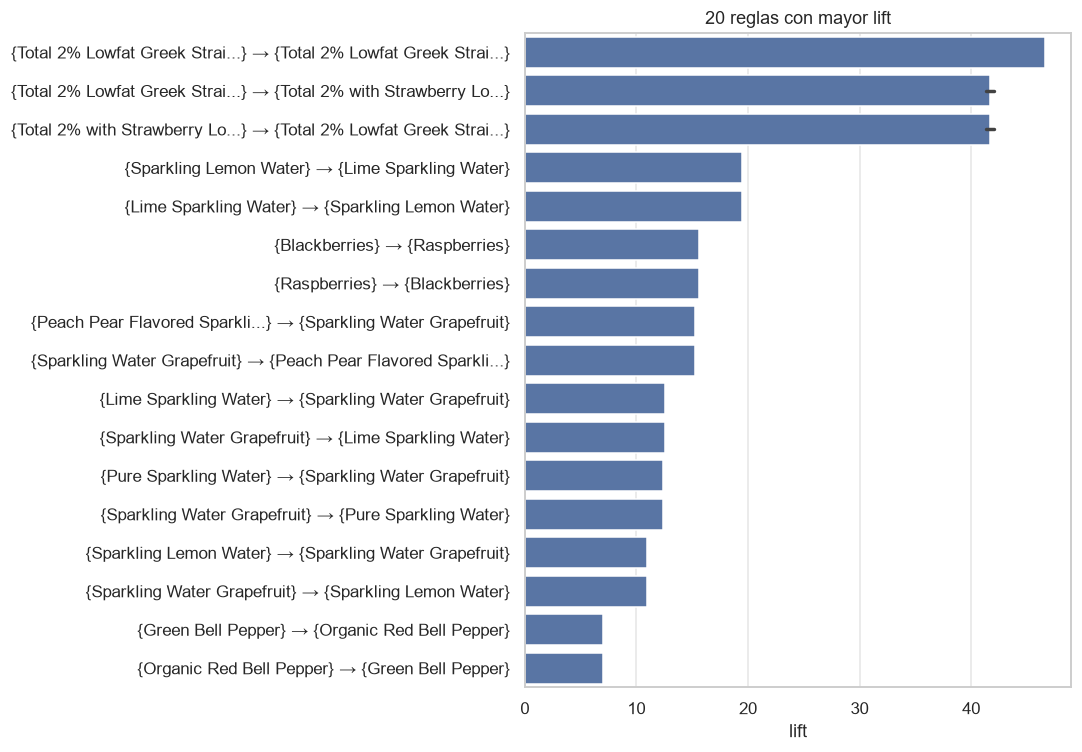

Coincidencias entre el top 20 por confianza y el top 20 por lift: 4


In [21]:
top_lift = reglas.sort_values(['lift', 'confianza'], ascending=False).head(20)
ver(top_lift)
fig, ax = plt.subplots(figsize=(10, 7))
sns.barplot(x=top_lift.lift, y=[texto_regla(a, c, corto=True) for a, c in zip(top_lift.antecedente, top_lift.consecuente)], ax=ax)
ax.set_title('20 reglas con mayor lift'); ax.set_xlabel('lift'); plt.tight_layout(); plt.show()
print(f'Coincidencias entre el top 20 por confianza y el top 20 por lift: '
      f'{len(set(top_conf.regla) & set(top_lift.regla))}')

## 3.3 Diez reglas con antecedentes de dos o tres productos

In [22]:
multi = reglas[reglas.len_antecedente.between(2, 3)]
sop3 = SOPORTE_REGLAS_USADO
while len(multi) < 10 and sop3 > 2.5e-4:
    sop3 = round(sop3 / 2, 6)
    r3, f3 = minar(canastas, sop3, conf_min=CONF_MIN_REGLAS, max_len=4)
    r3['mejora'] = calcular_mejora(r3, f3)
    multi = decorar(r3[r3.len_antecedente.between(2, 3)])
    print(f'Se buscaron reglas multiproducto con soporte {sop3}: {len(multi)}')
multi10 = multi.sort_values(['lift', 'confianza'], ascending=False).head(10)
ver(multi10, COLS + ['mejora'])

,regla,soporte,confianza,lift,leverage,conviction,jaccard,n_transacciones,mejora
0,"{Large Lemon, Organic Avocado} → {Limes}",0.0020,0.2681,6.2967,0.0017,1.3081,0.0419,241,0.0818
1,"{Limes, Organic Avocado} → {Large Lemon}",0.0020,0.2780,6.1588,0.0017,1.3225,0.0400,241,0.0805
2,"{Organic Lemon, Bag of Organic Bananas} → {Organic Hass Avocado}",0.0026,0.4122,6.1000,0.0022,1.5864,0.0364,310,0.1460
3,"{Organic Strawberries, Organic Hass Avocado} → {Organic Raspberries}",0.0032,0.2441,5.5238,0.0026,1.2645,0.0595,385,0.1039
4,"{Banana, Limes} → {Large Lemon}",0.0022,0.2458,5.4462,0.0018,1.2661,0.0425,264,0.0483
5,"{Bag of Organic Bananas, Organic Cucumber} → {Organic Hass Avocado}",0.0022,0.3484,5.1555,0.0018,1.4310,0.0306,262,0.1210
6,"{Banana, Limes} → {Organic Avocado}",0.0024,0.2626,4.8249,0.0019,1.2823,0.0386,282,0.0922
7,"{Bag of Organic Bananas, Organic Strawberries} → {Organic Raspberries}",0.0038,0.2042,4.6200,0.0030,1.2010,0.0648,458,0.0707
8,"{Bag of Organic Bananas, Organic Hass Avocado} → {Organic Cucumber}",0.0022,0.1073,4.5933,0.0017,1.0940,0.0527,262,0.0287
9,"{Bag of Organic Bananas, Organic Hass Avocado} → {Organic Lemon}",0.0026,0.1269,4.5445,0.0020,1.1134,0.0567,310,0.0169


## 3.4 Reglas con alta confianza y lift ≤ 1

Se consideró confianza alta la que está en el percentil 75 o más de todas las reglas candidatas.

In [23]:
umbral_alta = reglas.confianza.quantile(0.75)
alta_baja = reglas[(reglas.confianza >= umbral_alta) & (reglas.lift <= 1)].sort_values('confianza', ascending=False)
print(f'Umbral de confianza alta (p75): {umbral_alta:.3f}, reglas con lift <= 1: {len(alta_baja)}')
if len(alta_baja):
    ver(alta_baja, COLS + ['soporte_consecuente'], n=15)
else:
    print('No hay reglas que cumplan ambas condiciones; se muestran las reglas con lift <= 1 de mayor confianza:')
    ver(reglas[reglas.lift <= 1].sort_values('confianza', ascending=False), COLS + ['soporte_consecuente'], n=15)

Umbral de confianza alta (p75): 0.195, reglas con lift <= 1: 0
No hay reglas que cumplan ambas condiciones; se muestran las reglas con lift <= 1 de mayor confianza:


,regla,soporte,confianza,lift,leverage,conviction,jaccard,n_transacciones,soporte_consecuente
0,{Organic Yellow Onion} → {Banana},0.0047,0.1419,0.9666,-0.0002,0.9943,0.0270,567,0.1468
1,{Organic Cucumber} → {Banana},0.0033,0.1415,0.9638,-0.0001,0.9938,0.0198,395,0.1468
2,{Organic Ginger Root} → {Banana},0.0021,0.1352,0.9211,-0.0002,0.9866,0.0131,250,0.1468
3,{Organic Hass Avocado} → {Banana},0.0089,0.1322,0.9007,-0.0010,0.9832,0.0435,1068,0.1468
4,{Organic Lemon} → {Banana},0.0034,0.1234,0.8406,-0.0007,0.9733,0.0201,412,0.1468
5,{Half & Half} → {Bag of Organic Bananas},0.0023,0.1178,0.9738,-0.0001,0.9964,0.0168,278,0.1210
6,{Organic Fuji Apple} → {Bag of Organic Bananas},0.0031,0.1100,0.9093,-0.0003,0.9877,0.0210,366,0.1210
7,{Cucumber Kirby} → {Bag of Organic Bananas},0.0034,0.1092,0.9024,-0.0004,0.9867,0.0227,403,0.1210
8,{Banana} → {Organic Hass Avocado},0.0089,0.0609,0.9007,-0.0010,0.9929,0.0435,1068,0.0676
9,{Strawberries} → {Organic Hass Avocado},0.0025,0.0554,0.8196,-0.0005,0.9871,0.0224,293,0.0676


En estas reglas la confianza sale alta porque el consecuente ya es muy popular: su soporte es parecido o hasta mayor que la confianza. Comprar el antecedente no aumenta la probabilidad de llevar el consecuente, y a veces la baja. Lo único que "descubre" la regla es que ese producto se vende mucho.

## 3.5 Reglas redundantes

Se considera redundante una regla *A → C* con |A| ≥ 2 cuando existe un subconjunto propio *A′ ⊂ A* tal que *A′ → C* tiene confianza igual o mayor. En ese caso agregar productos al antecedente no mejora la predicción (criterio de mejora mínima de Bayardo et al., 1999). La tolerancia es `MEJORA_MIN`.

In [24]:
red = reglas[reglas.redundante].sort_values('mejora')
print(f'Reglas con antecedente de 2+: {(reglas.len_antecedente >= 2).sum()} | redundantes: {len(red)}')
if len(red):
    ver(red, COLS + ['mejora'], n=15)
    ej = red.iloc[0]
    print('\nEjemplo explicado:', ej.regla)
    for r_ in range(1, len(ej.antecedente)):
        for sub in itertools.combinations(ej.antecedente, r_):
            sf, cf = frozenset(sub), frozenset(ej.consecuente)
            print(f'   {texto_regla(sub, ej.consecuente)}  conf = {frec_reglas[sf | cf] / frec_reglas[sf]:.3f}')
    print(f'   regla completa conf = {ej.confianza:.3f} (mejora = {ej.mejora:+.4f})')

Reglas con antecedente de 2+: 69 | redundantes: 8


,regla,soporte,confianza,lift,leverage,conviction,jaccard,n_transacciones,mejora
0,"{Organic Strawberries, Organic Hass Avocado} → {Banana}",0.0023,0.1776,1.2096,0.0004,1.0374,0.0149,280,-0.0390
1,"{Organic Strawberries, Banana} → {Organic Hass Avocado}",0.0023,0.1282,1.8971,0.0011,1.0695,0.0281,280,-0.0282
2,"{Organic Strawberries, Organic Raspberries} → {Banana}",0.0023,0.2051,1.3969,0.0007,1.0733,0.0148,276,-0.0115
3,"{Organic Strawberries, Banana} → {Organic Raspberries}",0.0023,0.1264,2.8593,0.0015,1.0941,0.0384,276,-0.0071
4,"{Banana, Large Lemon} → {Limes}",0.0022,0.1905,4.4740,0.0017,1.1827,0.0425,264,0.0042
5,"{Limes, Large Lemon} → {Banana}",0.0022,0.2627,1.7896,0.0010,1.1572,0.0144,264,0.0058
6,"{Organic Strawberries, Banana} → {Organic Baby Spinach}",0.0028,0.1548,2.0628,0.0015,1.0943,0.0313,338,0.0067
7,"{Organic Strawberries, Organic Baby Spinach} → {Banana}",0.0028,0.2264,1.5423,0.0010,1.1029,0.0181,338,0.0099



Ejemplo explicado: {Organic Strawberries, Organic Hass Avocado} → {Banana}
   {Organic Strawberries} → {Banana}  conf = 0.217
   {Organic Hass Avocado} → {Banana}  conf = 0.132
   regla completa conf = 0.178 (mejora = -0.0390)


## 3.6 Las 10 reglas más útiles

Para elegirlas no se usó solo la confianza. Primero se filtraron las reglas con lift > 1.2, conviction > 1 y que no fueran redundantes. Después se les asignó un puntaje igual al promedio de sus percentiles en cuatro métricas: lift (qué tan lejos está de la independencia), leverage (cuántas transacciones de más explica), confianza (qué tan seguido se cumple) y Jaccard (qué tanto coinciden A y C en las mismas canastas). Por último, para no recomendar siempre lo mismo, se aceptaron como máximo 2 reglas con el mismo consecuente y no se repitió un par de productos en sentido inverso.

In [25]:
cand = reglas[(reglas.lift > 1.2) & (~reglas.redundante) & (reglas.conviction > 1)].copy()
for m in ['lift', 'leverage', 'confianza', 'jaccard']:
    cand['pct_' + m] = cand[m].rank(pct=True)
cand['puntaje'] = cand[['pct_lift', 'pct_leverage', 'pct_confianza', 'pct_jaccard']].mean(axis=1)
cand = cand.sort_values('puntaje', ascending=False)
sel, cuenta, vistos = [], Counter(), set()
for _, r_ in cand.iterrows():
    par = frozenset(r_.antecedente) | frozenset(r_.consecuente)
    if cuenta[r_.consecuente] >= 2 or par in vistos:
        continue
    sel.append(r_); cuenta[r_.consecuente] += 1; vistos.add(par)
    if len(sel) == 10:
        break
utiles = pd.DataFrame(sel)
ver(utiles, COLS + ['puntaje'])
utiles[COLS + ['puntaje']].to_csv(os.path.join(DIR_SALIDA, 'top10_reglas_utiles.csv'), index=False)

,regla,soporte,confianza,lift,leverage,conviction,jaccard,n_transacciones,puntaje
0,{Total 2% Lowfat Greek Strained Yogurt With Blueberry} → {Total 2% with Strawberry Lowfat Greek Strained Y...,0.0032,0.4187,41.3579,0.0032,1.7027,0.2211,386,0.9699
1,{Lime Sparkling Water} → {Sparkling Water Grapefruit},0.0038,0.2905,12.5908,0.0035,1.3769,0.1167,450,0.9540
2,{Total 2% Lowfat Greek Strained Yogurt with Peach} → {Total 2% with Strawberry Lowfat Greek Strained Yogurt},0.0026,0.4254,42.0226,0.0025,1.7227,0.1880,305,0.9451
3,{Jalapeno Peppers} → {Limes},0.0039,0.2776,6.5207,0.0033,1.3254,0.0745,470,0.9318
4,{Organic Lemon} → {Organic Hass Avocado},0.0074,0.2662,3.9398,0.0055,1.2708,0.0844,889,0.9254
5,{Organic Garlic} → {Organic Yellow Onion},0.0068,0.2063,6.1722,0.0057,1.2179,0.1142,814,0.9238
6,{Organic Cilantro} → {Limes},0.0051,0.2225,5.2263,0.0041,1.2314,0.0844,609,0.9122
7,{Total 2% Lowfat Greek Strained Yogurt with Peach} → {Total 2% Lowfat Greek Strained Yogurt With Blueberry},0.0022,0.3598,46.6506,0.0021,1.5500,0.1868,258,0.9068
8,{Limes} → {Large Lemon},0.0084,0.1975,4.3755,0.0065,1.1898,0.1060,1005,0.9066
9,{Sparkling Lemon Water} → {Lime Sparkling Water},0.0024,0.2520,19.4428,0.0023,1.3195,0.1203,290,0.8953


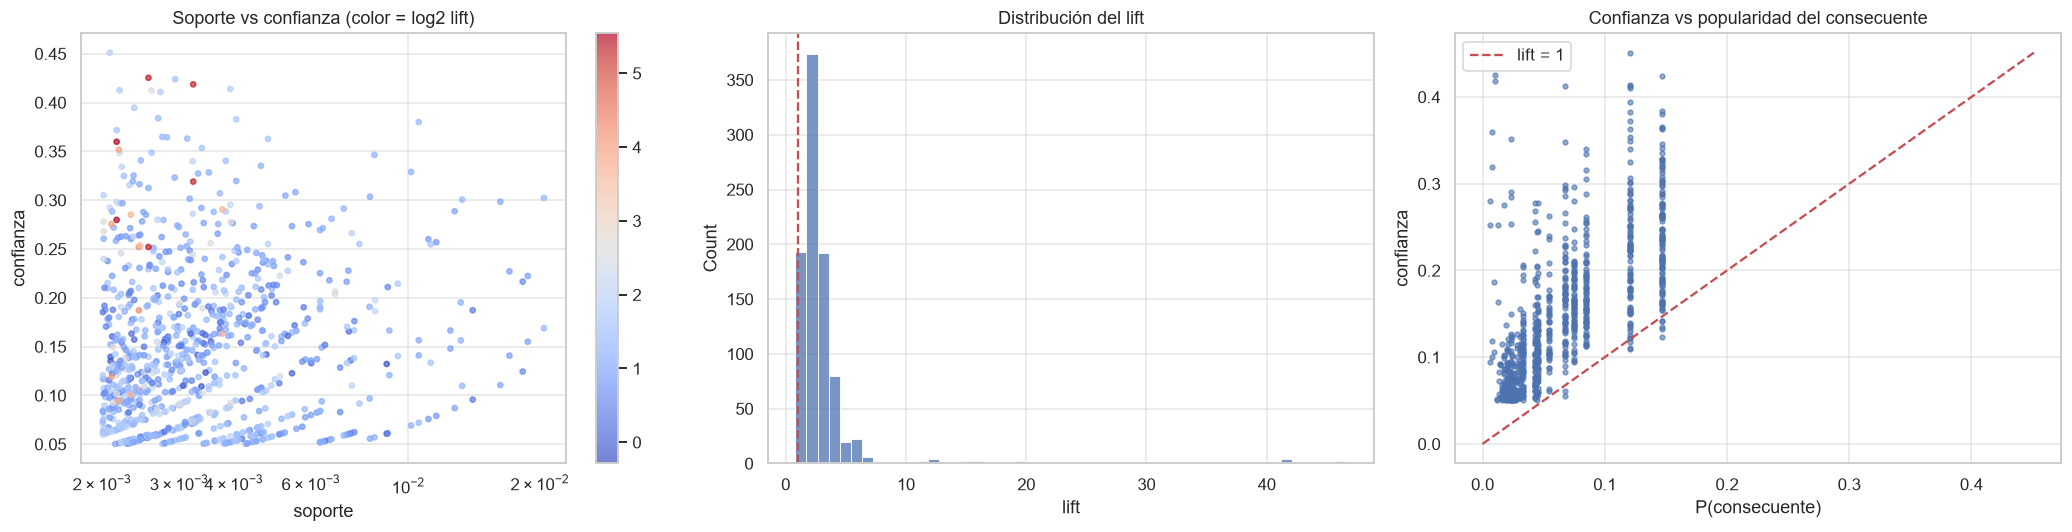

In [26]:
# Visualizaciones generales de las reglas
fig, ax = plt.subplots(1, 3, figsize=(19, 5))
sc_ = ax[0].scatter(reglas.soporte, reglas.confianza, c=np.log2(reglas.lift), cmap='coolwarm', s=12, alpha=.7)
ax[0].set_xscale('log'); ax[0].set_xlabel('soporte'); ax[0].set_ylabel('confianza'); ax[0].set_title('Soporte vs confianza (color = log2 lift)')
plt.colorbar(sc_, ax=ax[0])
sns.histplot(reglas.lift, bins=50, ax=ax[1]); ax[1].axvline(1, color='r', ls='--'); ax[1].set_title('Distribución del lift')
ax[2].scatter(reglas.soporte_consecuente, reglas.confianza, s=10, alpha=.6)
lim = max(reglas.soporte_consecuente.max(), reglas.confianza.max())
ax[2].plot([0, lim], [0, lim], 'r--', label='lift = 1')
ax[2].set_xlabel('P(consecuente)'); ax[2].set_ylabel('confianza'); ax[2].set_title('Confianza vs popularidad del consecuente'); ax[2].legend()
plt.tight_layout(); plt.show()

# Parte 4. Análisis de patrones de consumo

Para comparar días, horas, tamaños de canasta y demás, las reglas se minan dentro de cada grupo con un soporte relativo `SOPORTE_SEG`. De cada grupo se obtiene el número de reglas, el lift mediano y las reglas más fuertes (solo las que tienen al menos 20 transacciones, para no reportar ruido). También se calcula la similitud de Jaccard entre las reglas de cada par de grupos y un índice de participación: el porcentaje de canastas del grupo que tienen el producto dividido entre el porcentaje general. Si sale mayor que 1, el producto está sobrerrepresentado en ese grupo.

In [27]:
TOP_IDS = frec_l.nlargest(15, 'n_transacciones').product_id.to_numpy()

def reglas_por_segmento(etiquetas, orden=None, soporte=SOPORTE_SEG, conf=CONF_MIN_REGLAS, min_trans=1000):
    res = {}
    for seg in (orden if orden is not None else sorted(pd.unique(etiquetas))):
        idx = np.flatnonzero(etiquetas == seg)
        if len(idx) < min_trans:
            print(f'  segmento {seg}: solo {len(idx)} transacciones, se omite'); continue
        r, _ = minar([canastas[i] for i in idx], soporte, conf_min=conf, max_len=3)
        res[seg] = (len(idx), r)
    return res

def resumir_segmentos(res, nombre_seg, n_top=3, min_n=20):
    filas = []
    for seg, (n, r) in res.items():
        rf = r[r.n_transacciones >= min_n]
        top = rf.nlargest(n_top, 'lift')
        filas.append({nombre_seg: seg, 'transacciones': n, 'reglas': len(r),
                      'lift_mediano': r.lift.median() if len(r) else np.nan,
                      'conf_mediana': r.confianza.median() if len(r) else np.nan,
                      'reglas_mas_fuertes': ' | '.join(texto_regla(a, c, corto=True) for a, c in zip(top.antecedente, top.consecuente))})
    return pd.DataFrame(filas)

def jaccard_segmentos(res):
    claves = {seg: set(zip(r.antecedente, r.consecuente)) for seg, (n, r) in res.items()}
    segs = list(claves)
    J = pd.DataFrame(index=segs, columns=segs, dtype=float)
    for a in segs:
        for b in segs:
            u = claves[a] | claves[b]
            J.loc[a, b] = len(claves[a] & claves[b]) / len(u) if u else np.nan
    return J

def indice_participacion(etiquetas, ids=TOP_IDS, orden=None):
    M_, its = matriz_binaria(canastas, items=ids)
    M_ = M_.astype(np.float32)
    glob_ = np.asarray(M_.mean(axis=0)).ravel()
    cols = {}
    for seg in (orden if orden is not None else sorted(pd.unique(etiquetas))):
        m = etiquetas == seg
        if m.sum():
            cols[seg] = np.asarray(M_[np.flatnonzero(m)].mean(axis=0)).ravel() / glob_
    return pd.DataFrame(cols, index=[nombre_corto(i) for i in its])

def analizar_segmentos(etiquetas, nombre_seg, orden=None):
    res = reglas_por_segmento(etiquetas, orden)
    resumen_ = resumir_segmentos(res, nombre_seg)
    display(resumen_)
    J = jaccard_segmentos(res)
    idx = indice_participacion(etiquetas, orden=orden)
    fig, ax = plt.subplots(1, 2, figsize=(18, 6), gridspec_kw={'width_ratios': [1, 1.3]})
    sns.heatmap(J.astype(float), annot=True, fmt='.2f', cmap='Blues', ax=ax[0])
    ax[0].set_title(f'Similitud de Jaccard entre reglas por {nombre_seg}')
    sns.heatmap(idx, annot=True, fmt='.2f', cmap='RdBu_r', center=1, ax=ax[1])
    ax[1].set_title(f'Índice de participación por {nombre_seg} (1 = igual al global)')
    plt.tight_layout(); plt.show()
    return res, resumen_, J, idx

## 4.1 Productos que se compran juntos con mayor frecuencia

,par,soporte,transacciones,lift
0,Bag of Organic Bananas + Organic Hass Avocado,0.0204,2442,2.4979
1,Bag of Organic Bananas + Organic Strawberries,0.0188,2243,1.8376
2,Organic Strawberries + Banana,0.0183,2184,1.4752
3,Bag of Organic Bananas + Organic Baby Spinach,0.0170,2037,1.8769
4,Banana + Organic Avocado,0.0162,1941,2.0328
5,Organic Baby Spinach + Banana,0.0140,1679,1.2755
6,Bag of Organic Bananas + Organic Raspberries,0.0133,1588,2.4838
7,Organic Strawberries + Organic Hass Avocado,0.0132,1577,2.3136
8,Strawberries + Banana,0.0128,1527,1.9665
9,Organic Strawberries + Organic Baby Spinach,0.0125,1493,1.9730


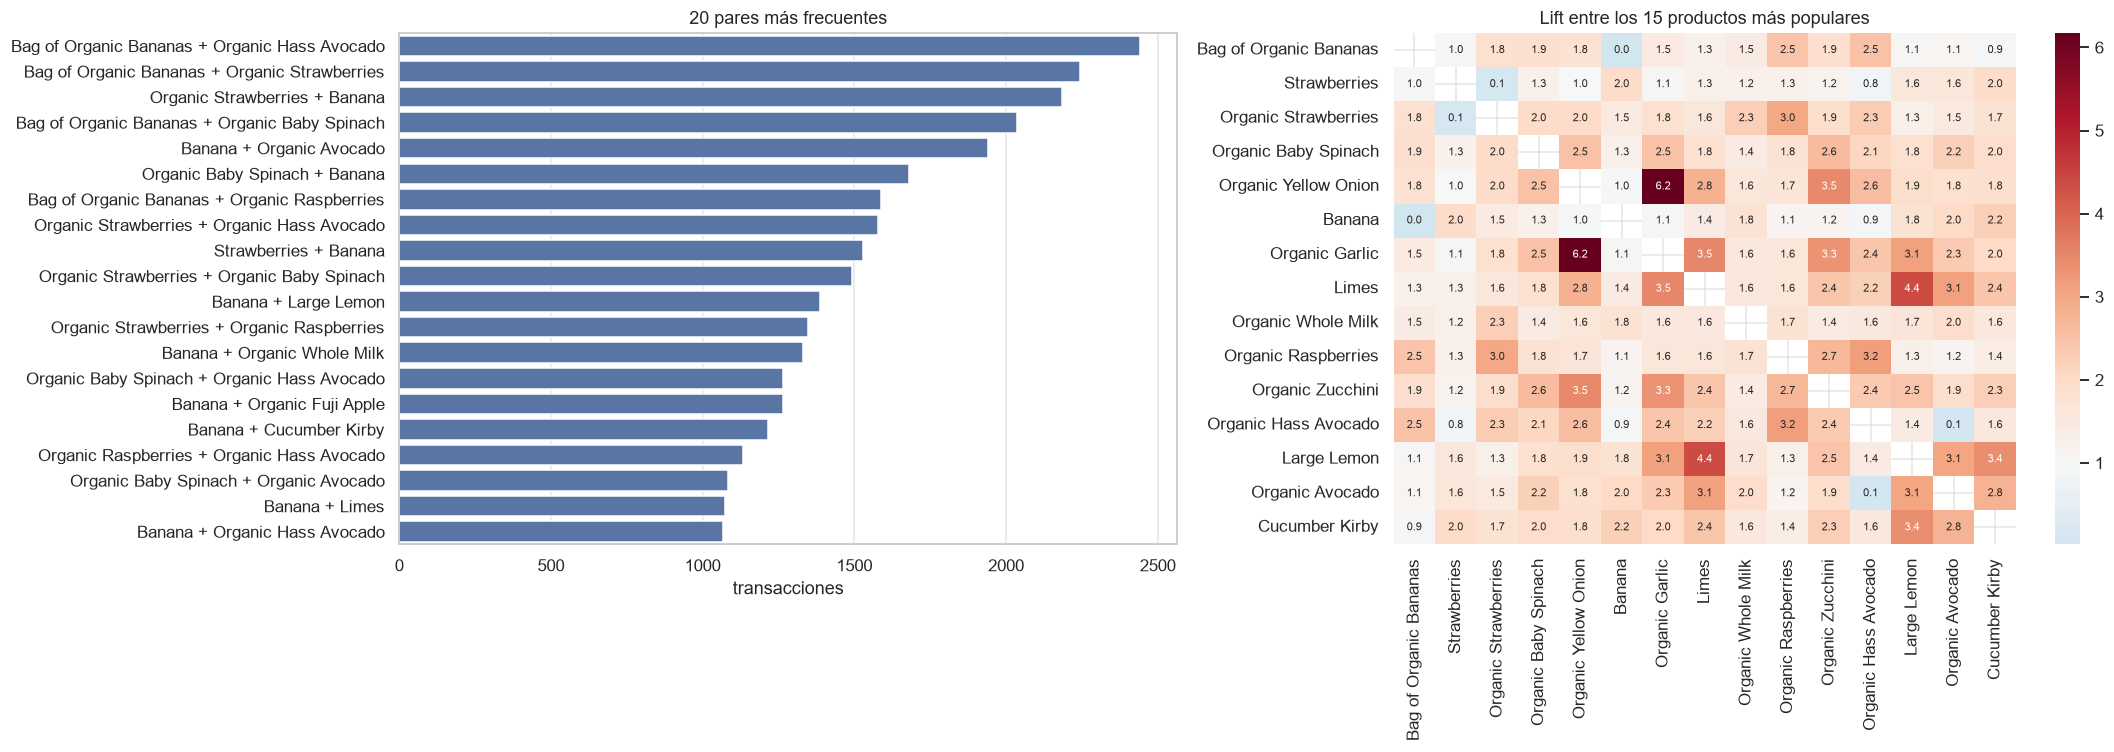

In [28]:
pares_frec = sorted(((k, v) for k, v in frec_reglas.items() if len(k) == 2), key=lambda kv: -kv[1])[:20]
tabla_pares = pd.DataFrame([{
    'par': ' + '.join(nombre_prod[i] for i in sorted(k)), 'soporte': v, 'transacciones': round(v * N),
    'lift': v / (frec_reglas[frozenset([a])] * frec_reglas[frozenset([b])])}
    for k, v in pares_frec for a, b in [sorted(k)]])
display(tabla_pares.round(4))

M15, its15 = matriz_binaria(canastas, items=TOP_IDS)
M15 = M15.astype(np.float32)
co = (M15.T @ M15).toarray() / N
s15 = np.diag(co).copy()
lift15 = co / np.outer(s15, s15); np.fill_diagonal(lift15, np.nan)
fig, ax = plt.subplots(1, 2, figsize=(20, 7))
sns.barplot(data=tabla_pares, x='transacciones', y='par', ax=ax[0]); ax[0].set_title('20 pares más frecuentes'); ax[0].set_ylabel('')
etq15 = [nombre_corto(i, n=22) for i in its15]
sns.heatmap(pd.DataFrame(lift15, index=etq15, columns=etq15), annot=True, fmt='.1f', cmap='RdBu_r', center=1, ax=ax[1], annot_kws={'size': 7})
ax[1].set_title('Lift entre los 15 productos más populares')
plt.tight_layout(); plt.show()

Los 20 pares más frecuentes son todos de productos muy populares (plátanos, fresas, espinaca y aguacate). El primero es Bag of Organic Bananas + Organic Hass Avocado, con 2,442 transacciones y lift 2.50. Pero que un par salga mucho no significa que estén muy relacionados. Organic Baby Spinach + Banana tiene lift 1.28, y Banana + Organic Hass Avocado tiene lift 0.90, o sea que aparecen juntos menos de lo que se esperaría por azar aunque estén en el top 20. En cambio, pares menos frecuentes como Organic Raspberries + Organic Hass Avocado (lift 3.17) u Organic Strawberries + Organic Raspberries (3.02) sí muestran una atracción real.

También se observa que Banana y Bag of Organic Bananas se portan como sustitutos con clientes distintos. La bolsa orgánica va con Organic Hass Avocado (lift 2.50), mientras que la banana suelta va con Organic Avocado (2.03) y no con el Hass (0.90).

## 4.2 Diferencias entre patrones de compra de distintos departamentos

,articulos,transacciones,productos_distintos,tasa_recompra,%_articulos,%_canastas_con_depto,articulos_por_canasta_si_presente
department,,,,,,,
produce,348430,89623,1409,0.653,0.295,0.750,3.888
dairy eggs,196334,80112,2713,0.670,0.166,0.670,2.451
snacks,102795,51383,4210,0.572,0.087,0.430,2.001
beverages,97207,53615,2916,0.653,0.082,0.449,1.813
frozen,80850,43491,2955,0.540,0.068,0.364,1.859
pantry,68147,40958,3580,0.345,0.058,0.343,1.664
bakery,42479,32253,1151,0.630,0.036,0.270,1.317
canned goods,38070,24688,1414,0.458,0.032,0.207,1.542
deli,37508,28181,953,0.607,0.032,0.236,1.331


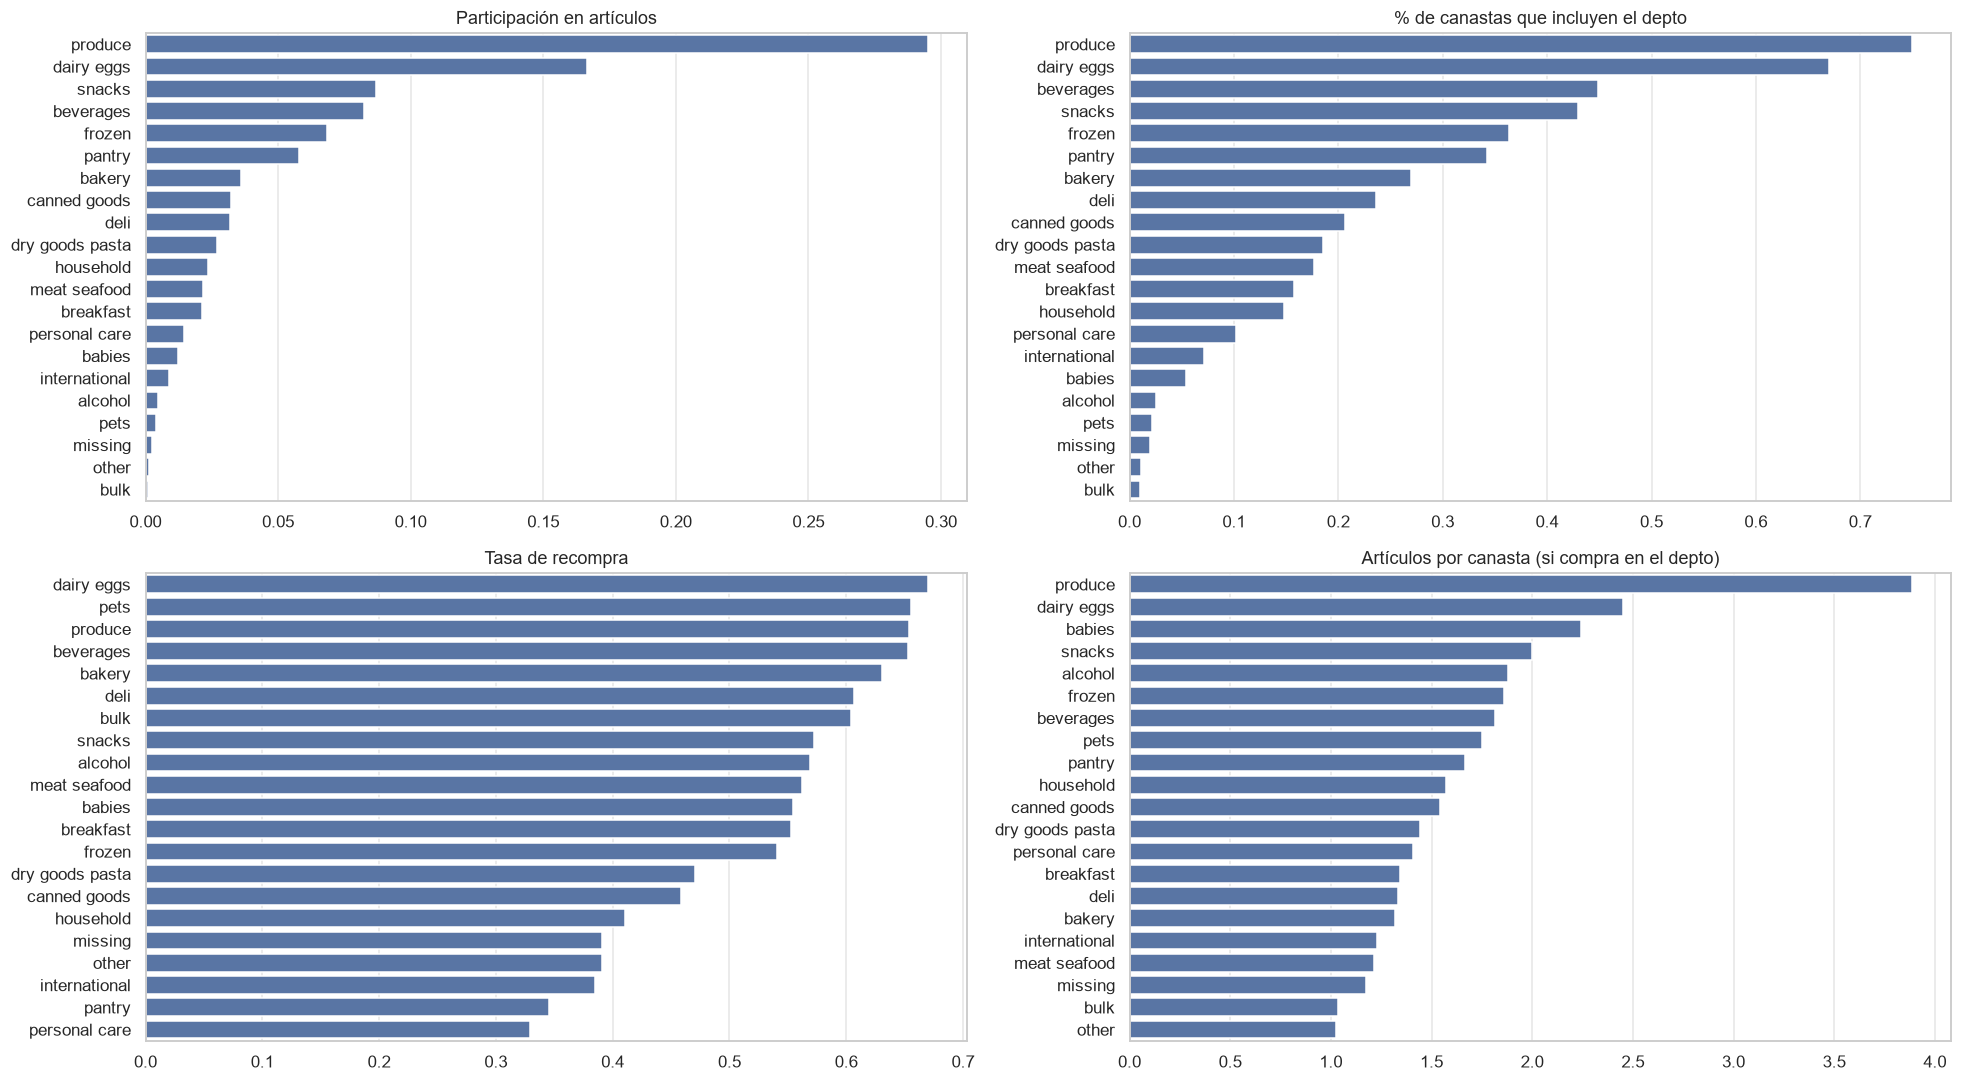

Reglas DENTRO de los 4 departamentos con más artículos (soporte relativo a las canastas que compran en ese depto):


,departamento,canastas,reglas,lift_mediano,reglas_mas_fuertes
0,produce,89623,397,1.708147,{Jalapeno Peppers} → {Limes} | {Limes} → {Jalapeno Peppers} | {Organic Yellow Onion} → {Organic Garlic}
1,dairy eggs,80112,2,27.718427,{Total 2% Lowfat Greek Strai...} → {Total 2% with Strawberry Lo...} | {Total 2% with Strawberry Lo...} → {...
2,snacks,51383,0,NaN,
3,beverages,53615,10,5.647460,{Sparkling Lemon Water} → {Lime Sparkling Water} | {Lime Sparkling Water} → {Sparkling Lemon Water} | {Pea...


In [29]:
por_depto = (datos_l.groupby('department')
             .agg(articulos=('product_id', 'size'), transacciones=('order_id', 'nunique'),
                  productos_distintos=('product_id', 'nunique'), tasa_recompra=('reordered', 'mean')))
por_depto['%_articulos'] = por_depto.articulos / por_depto.articulos.sum()
por_depto['%_canastas_con_depto'] = por_depto.transacciones / N
por_depto['articulos_por_canasta_si_presente'] = por_depto.articulos / por_depto.transacciones
por_depto = por_depto.sort_values('articulos', ascending=False)
display(por_depto.round(3))

fig, ax = plt.subplots(2, 2, figsize=(18, 10))
for a, col, t in zip(ax.ravel(), ['%_articulos', '%_canastas_con_depto', 'tasa_recompra', 'articulos_por_canasta_si_presente'],
                     ['Participación en artículos', '% de canastas que incluyen el depto', 'Tasa de recompra', 'Artículos por canasta (si compra en el depto)']):
    d = por_depto[col].sort_values(ascending=False)
    sns.barplot(x=d.values, y=d.index, ax=a); a.set_title(t); a.set_ylabel('')
plt.tight_layout(); plt.show()

def canastas_desde_filas(df):
    df = df.sort_values(['order_id', 'product_id'])
    o = df.order_id.to_numpy(); p = df.product_id.to_numpy().astype(np.int64)
    c = np.flatnonzero(np.diff(o)) + 1
    return np.split(p, c) if len(o) else []

print('Reglas DENTRO de los 4 departamentos con más artículos (soporte relativo a las canastas que compran en ese depto):')
filas_d = []
for d in por_depto.index[:4]:
    cd = canastas_desde_filas(datos_l[datos_l.department == d])
    r, _ = minar(cd, SOPORTE_SEG, conf_min=CONF_MIN_REGLAS, max_len=3)
    rf = r[r.n_transacciones >= 20]
    top = rf.nlargest(3, 'lift')
    filas_d.append({'departamento': d, 'canastas': len(cd), 'reglas': len(r),
                    'lift_mediano': r.lift.median() if len(r) else np.nan,
                    'reglas_mas_fuertes': ' | '.join(texto_regla(a, c, corto=True) for a, c in zip(top.antecedente, top.consecuente))})
display(pd.DataFrame(filas_d))

*produce* y *dairy eggs* son los que mandan: aparecen en el 75 % y el 67 % de las canastas, juntan el 46 % de los artículos y se recompran entre 65 y 67 % de las veces. Son departamentos de compra recurrente, igual que *beverages* (65 %), *bakery* (63 %) y *pets* (65.5 %). Mascotas está en solo el 2 % de las canastas, pero quien compra ahí repite la misma marca. Del otro lado, *personal care* (33 %), *pantry* (34.5 %), *international* (38.5 %) y *household* (41 %) son de compra ocasional: tienen muchos productos distintos (3,454 en cuidado personal) y casi no se recompran.

Dentro de cada departamento también cambia mucho. *produce* genera 397 reglas internas con lift mediano de 1.71, casi todas combinaciones para cocinar como jalapeño con limón o cebolla con ajo. *dairy eggs* solo genera 2 (entre sabores del mismo yogur, con lift de casi 28) y *snacks* ninguna con este soporte. En lácteos y botanas cada quien tiene "su" producto y no hay combinaciones que dominen; en frutas y verduras sí las hay.

## 4.3 Asociaciones entre productos de departamentos diferentes

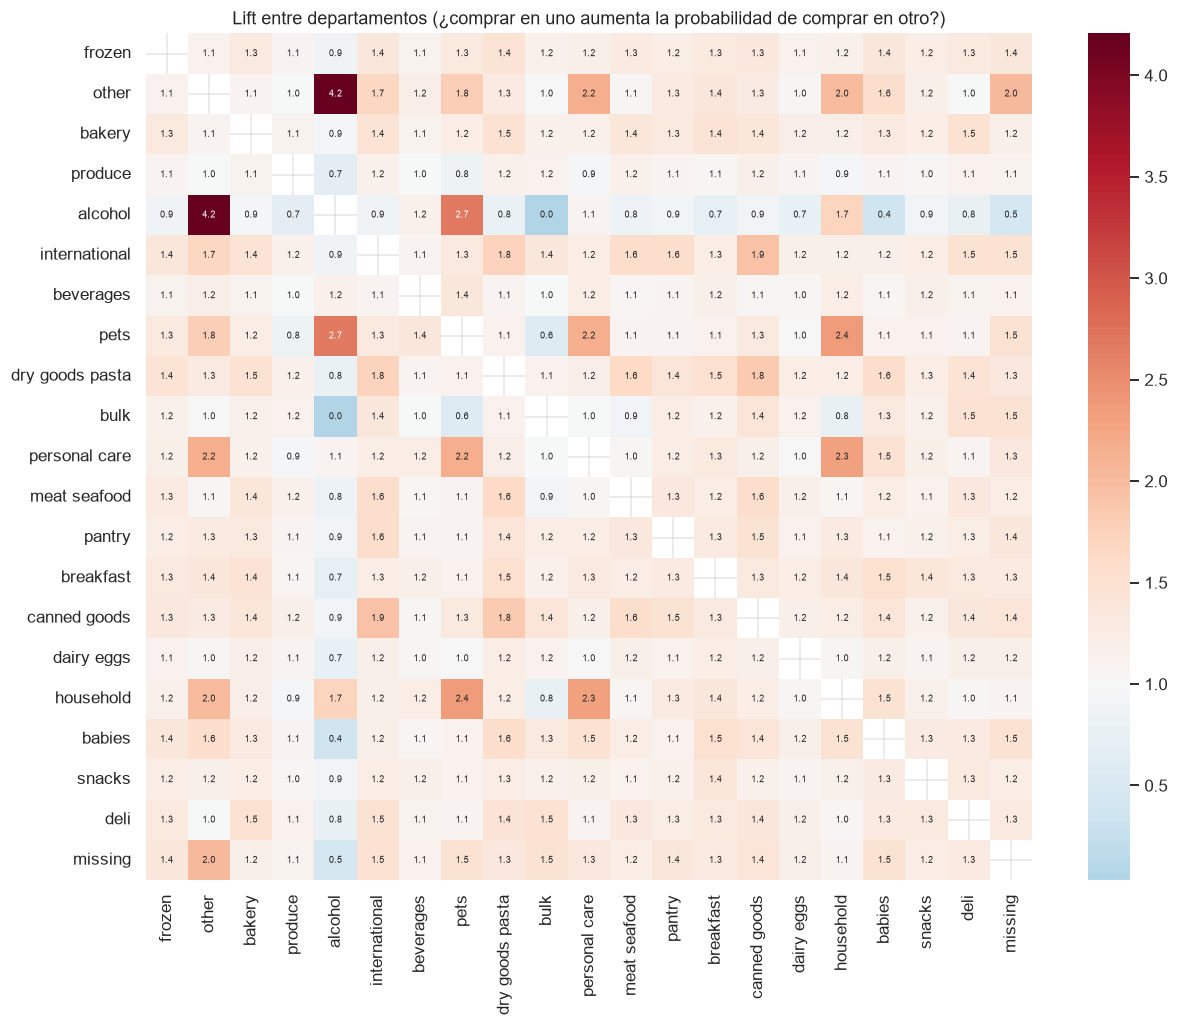

Reglas a nivel departamento (top 10 por lift):


,regla,soporte,confianza,lift,leverage,conviction,jaccard,n_transacciones
0,"{dry goods pasta} → {canned goods, dairy eggs}",0.0618,0.3332,2.0122,0.0311,1.2514,0.2136,7385
1,"{canned goods, dairy eggs} → {dry goods pasta}",0.0618,0.3731,2.0122,0.0311,1.2993,0.2136,7385
2,"{dry goods pasta, dairy eggs} → {canned goods}",0.0618,0.4026,1.9495,0.0301,1.3283,0.2072,7385
3,"{produce, dry goods pasta} → {canned goods}",0.0651,0.4025,1.9486,0.0317,1.3279,0.2148,7785
4,"{canned goods} → {produce, dry goods pasta}",0.0651,0.3153,1.9486,0.0317,1.2242,0.2148,7785
5,"{produce, canned goods} → {dry goods pasta}",0.0651,0.3572,1.9265,0.0313,1.2672,0.2152,7785
6,"{dry goods pasta} → {produce, canned goods}",0.0651,0.3513,1.9265,0.0313,1.2604,0.2152,7785
7,{canned goods} → {dry goods pasta},0.0708,0.3426,1.8479,0.0325,1.2391,0.2203,8458
8,{dry goods pasta} → {canned goods},0.0708,0.3817,1.8479,0.0325,1.2832,0.2203,8458
9,"{frozen, pantry} → {dry goods pasta}",0.0505,0.3285,1.7718,0.0220,1.2131,0.1751,6041



Reglas a nivel producto entre departamentos distintos: 143 de 905 (15.8%)


,regla,soporte,confianza,lift,leverage,conviction,jaccard,n_transacciones,depto_antecedente,depto_consecuente
0,{Organic Baby Carrots} → {Original Hummus},0.0022,0.0916,4.1644,0.0017,1.0766,0.0506,267,produce,deli
1,{Original Hummus} → {Organic Baby Carrots},0.0022,0.1015,4.1644,0.0017,1.0859,0.0506,267,deli,produce
2,{Pineapple Chunks} → {Organic Baby Spinach},0.0022,0.2967,3.9549,0.0016,1.3152,0.0273,262,frozen,produce
3,{Blueberries} → {Strawberries},0.0030,0.1697,3.8345,0.0023,1.1511,0.0515,364,frozen,produce
4,{Strawberries} → {Blueberries},0.0030,0.0688,3.8345,0.0023,1.0546,0.0515,364,produce,frozen
5,{Frozen Organic Wild Blueberries} → {Organic Baby Spinach},0.0027,0.2800,3.7316,0.0020,1.2846,0.0327,320,frozen,produce
6,"{Organic Strawberries, Banana} → {Organic Whole Milk}",0.0026,0.1397,3.2629,0.0018,1.1126,0.0436,305,produce,dairy eggs
7,"{Organic Whole Milk} → {Organic Strawberries, Banana}",0.0026,0.0596,3.2629,0.0018,1.0440,0.0436,305,dairy eggs,produce
8,{Organic Reduced Fat 2% Milk} → {Organic Raspberries},0.0021,0.1422,3.2179,0.0015,1.1143,0.0375,256,dairy eggs,produce
9,{Frozen Organic Wild Blueberries} → {Organic Hass Avocado},0.0021,0.2152,3.1847,0.0014,1.1881,0.0274,246,frozen,produce


In [30]:
dd = datos_l[['order_id', 'department_id']].drop_duplicates().rename(columns={'department_id': 'product_id'})
canastas_depto = canastas_desde_filas(dd)
assert len(canastas_depto) == N

Md, its_d = matriz_binaria(canastas_depto)
Md = Md.astype(np.float32)
co_d = (Md.T @ Md).toarray() / N
s_d = np.diag(co_d).copy()
lift_d = co_d / np.outer(s_d, s_d); np.fill_diagonal(lift_d, np.nan)
etq_d = [nombre_depto[int(i)] for i in its_d]
plt.figure(figsize=(13, 10))
sns.heatmap(pd.DataFrame(lift_d, index=etq_d, columns=etq_d), annot=True, fmt='.1f', cmap='RdBu_r', center=1, annot_kws={'size': 6})
plt.title('Lift entre departamentos (¿comprar en uno aumenta la probabilidad de comprar en otro?)'); plt.show()

reglas_dep, _ = minar(canastas_depto, 0.05, conf_min=0.3, max_len=3)
reglas_dep = decorar(reglas_dep, dic=nombre_depto)
print('Reglas a nivel departamento (top 10 por lift):')
ver(reglas_dep.sort_values('lift', ascending=False), n=10)

cruzadas = reglas[[not (set(deptos_de(a)) & set(deptos_de(c))) for a, c in zip(reglas.antecedente, reglas.consecuente)]]
print(f'\nReglas a nivel producto entre departamentos distintos: {len(cruzadas)} de {len(reglas)} ({len(cruzadas)/len(reglas):.1%})')
ver(cruzadas.sort_values('lift', ascending=False), COLS + ['depto_antecedente', 'depto_consecuente'], n=10)

A nivel departamento, las asociaciones más fuertes son entre *dry goods pasta*, *canned goods*, *dairy eggs* y *produce* (lift de 1.8 a 2.0), como una compra de despensa. Por ejemplo, {dry goods pasta} → {canned goods} tiene confianza 0.38 y lift 1.85 en 8,458 canastas: quien compra pasta seca suele llevar enlatados (salsas, tomate) para cocinarla.

A nivel producto, solo 143 de las 905 reglas (15.8 %) cruzan departamentos. Las más fuertes son de productos que se usan juntos: Organic Baby Carrots con Original Hummus (lift 4.16, *produce* y *deli*), fruta congelada con espinaca para licuados (Pineapple Chunks → Organic Baby Spinach, lift 3.95) y Blueberries congeladas con Strawberries (3.83). Para un recomendador estas son las más interesantes, porque sugieren algo que el cliente no vería en el mismo pasillo.

## 4.4 Patrones según el día de la semana

Instacart guarda el día como `order_dow`, de 0 a 6, pero no dice qué día es cada número. Lo más común es suponer que 0 es domingo; aquí se reporta como "día 0" a "día 6".

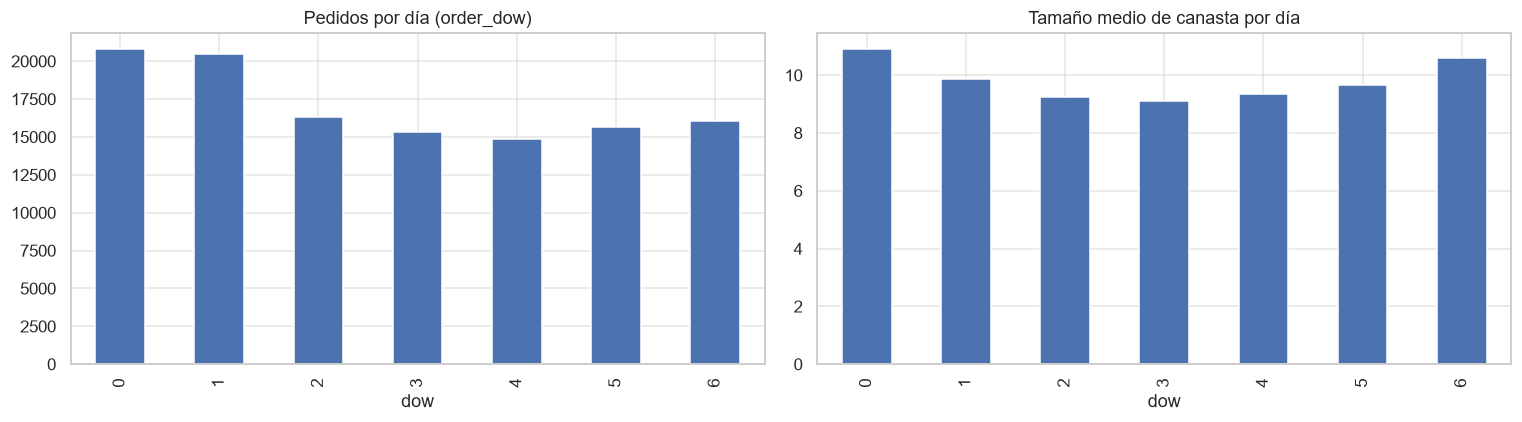

,día,transacciones,reglas,lift_mediano,conf_mediana,reglas_mas_fuertes
0,0,20812,442,2.065494,0.156250,{Limes} → {Bunched Cilantro} | {Bunched Cilantro} → {Limes} | {Cucumber Kirby} → {Red Vine Tomato}
1,1,20500,307,2.214803,0.167345,{Total 2% Lowfat Greek Strai...} → {Total 2% with Strawberry Lo...} | {Total 2% with Strawberry Lo...} → {...
2,2,16328,167,2.307226,0.150706,{Organic Yellow Onion} → {Organic Garlic} | {Organic Garlic} → {Organic Yellow Onion} | {Limes} → {Organic...
3,3,15358,141,2.288884,0.146552,{Organic Yellow Onion} → {Organic Garlic} | {Organic Garlic} → {Organic Yellow Onion} | {Limes} → {Organic...
4,4,14879,174,2.363373,0.161984,{Lime Sparkling Water} → {Sparkling Water Grapefruit} | {Sparkling Water Grapefruit} → {Lime Sparkling Wat...
5,5,15631,200,2.317196,0.158172,{Total 2% Lowfat Greek Strai...} → {Total 2% with Strawberry Lo...} | {Total 2% with Strawberry Lo...} → {...
6,6,16025,319,2.093364,0.157407,{Organic Yellow Onion} → {Organic Garlic} | {Organic Garlic} → {Organic Yellow Onion} | {Organic Garlic} →...


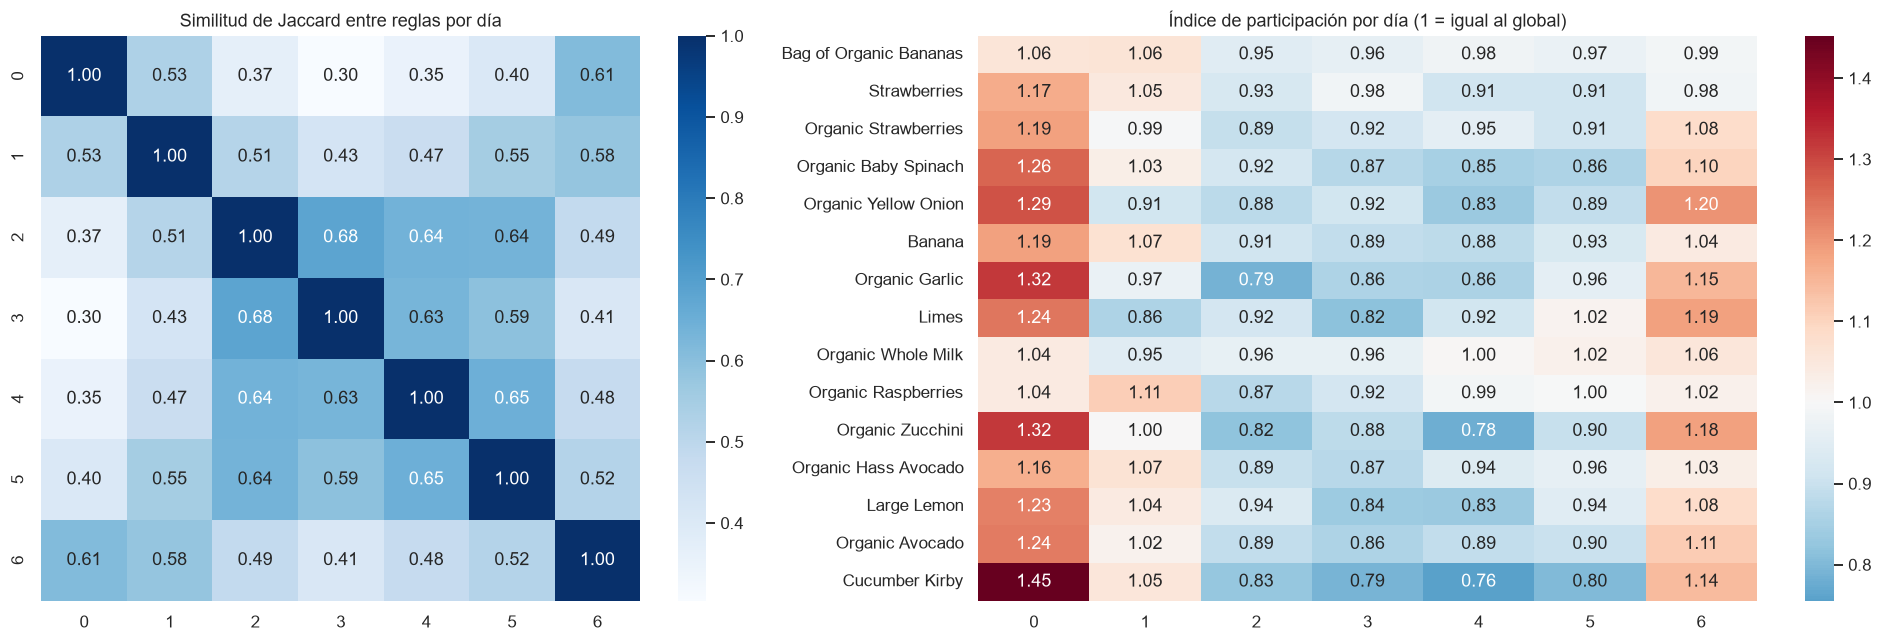

In [31]:
dias = trans.dow.to_numpy()
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
trans.dow.value_counts().sort_index().plot.bar(ax=ax[0], title='Pedidos por día (order_dow)')
trans.groupby('dow').n_productos.mean().plot.bar(ax=ax[1], title='Tamaño medio de canasta por día')
plt.tight_layout(); plt.show()
res_dia, resumen_dia, J_dia, idx_dia = analizar_segmentos(dias, 'día')

Los días 0 y 1 tienen más pedidos (unos 20,800 y 20,500, contra 14,900 a 16,300 los demás), y los días 0 y 6 tienen las canastas más grandes (cerca de 10.9 y 10.6 productos, contra 9.1 a 9.4 a mitad de semana). Si 0 es domingo, eso cae en fin de semana, que es cuando se hace la compra grande. Esos días también generan más reglas (442 el día 0 y 319 el día 6, contra 141 a 200 de los días 2 a 5) y su lift mediano es un poco menor (2.07 a 2.09 contra 2.2 a 2.36).

En el índice de participación, el día 0 tiene de más los ingredientes de cocina (Cucumber Kirby 1.45, Organic Garlic 1.32, Organic Zucchini 1.32, Organic Yellow Onion 1.29), y el día 6 lo mismo pero menos marcado. De los días 2 a 5 casi todos los productos quedan por debajo de 1. El Jaccard separa dos bloques: los días 2 a 5 se parecen mucho entre sí (0.59 a 0.68) y los días 0, 1 y 6 forman otro grupo (0.53 a 0.61). Entre bloques se parecen poco (0.30 entre los días 0 y 3). Entre semana los patrones se mantienen y cambian en fin de semana.

## 4.5 Patrones según la hora del día

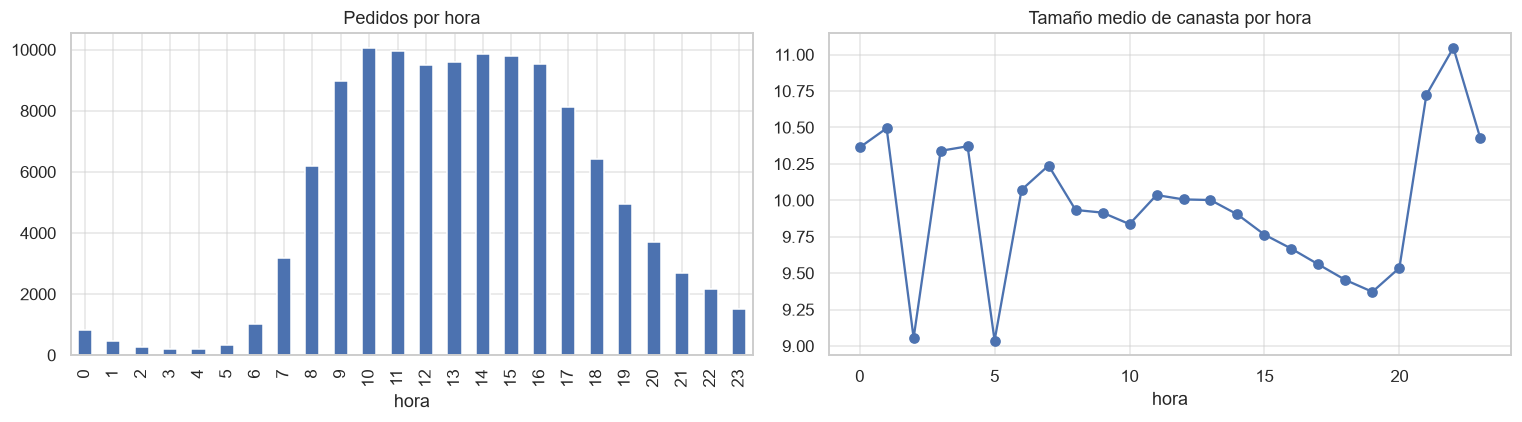

,franja horaria,transacciones,reglas,lift_mediano,conf_mediana,reglas_mas_fuertes
0,1 Madrugada (0-5),2303,575,3.807870,0.225352,{Soda} → {Elbow Macaroni & Cheese Sid...} | {Elbow Macaroni & Cheese Sid...} → {Soda} | {Organic Baby Spin...
1,2 Mañana (6-11),39351,258,2.166715,0.165673,{Total 2% Lowfat Greek Strai...} → {Total 2% with Strawberry Lo...} | {Total 2% with Strawberry Lo...} → {...
2,3 Tarde (12-17),56423,235,2.089751,0.148450,{Limes} → {Bunched Cilantro} | {Bunched Cilantro} → {Limes} | {Jalapeno Peppers} → {Limes}
3,4 Noche (18-23),21456,268,2.271978,0.165639,{Organic Garlic} → {Organic Yellow Onion} | {Organic Yellow Onion} → {Organic Garlic} | {Limes} → {Organic...


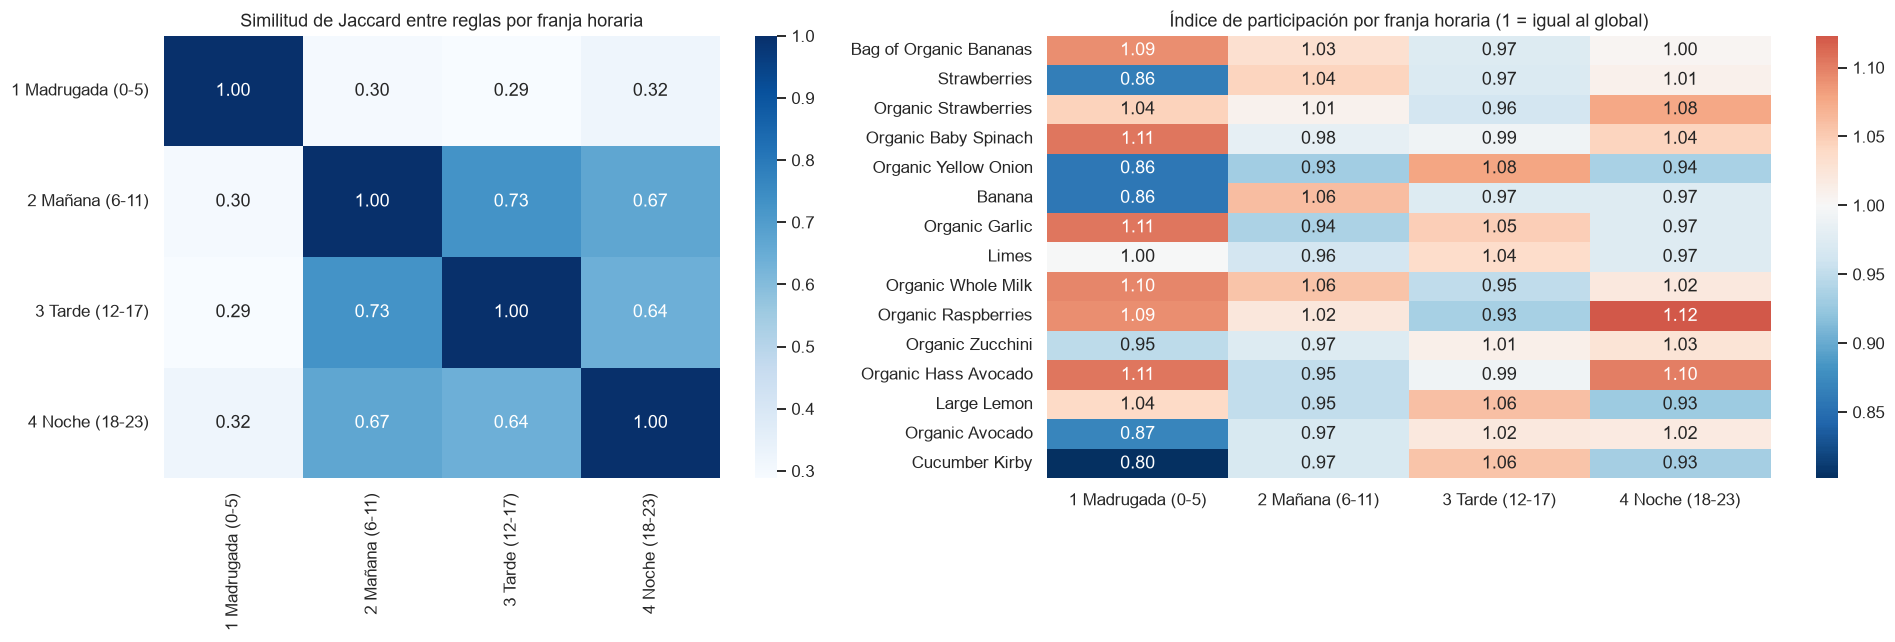

In [32]:
horas = trans.hora.to_numpy()
franja = np.select([horas < 6, horas < 12, horas < 18], ['1 Madrugada (0-5)', '2 Mañana (6-11)', '3 Tarde (12-17)'], '4 Noche (18-23)')
orden_franja = ['1 Madrugada (0-5)', '2 Mañana (6-11)', '3 Tarde (12-17)', '4 Noche (18-23)']
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
trans.hora.value_counts().sort_index().plot.bar(ax=ax[0], title='Pedidos por hora')
trans.groupby('hora').n_productos.mean().plot(ax=ax[1], marker='o', title='Tamaño medio de canasta por hora')
plt.tight_layout(); plt.show()
res_hora, resumen_hora, J_hora, idx_hora = analizar_segmentos(franja, 'franja horaria', orden=orden_franja)

La mayoría de los pedidos se hace entre las 9 y las 16 h (unos 9,000 a 10,000 por hora) y luego van bajando hasta la medianoche; de las 0 a las 5 h solo hay 2,303 pedidos (1.9 %). El tamaño de la canasta baja en la tarde (unos 9.4 productos a las 19 h) y sube en la noche (unos 11 a las 22 h), así que los pedidos de noche son compras más grandes y planeadas. Mañana, tarde y noche comparten la mayoría de sus reglas (Jaccard de 0.64 a 0.73) y tienen un lift mediano parecido (2.09 a 2.27).

La madrugada es otra cosa: su Jaccard con las demás franjas es de solo 0.29 a 0.32, su lift mediano es 3.81 y tiene reglas propias como {Soda} con {Elbow Macaroni & Cheese}. Esto hay que tomarlo con cuidado. Con 2,303 transacciones, el soporte relativo equivale a unas 10 canastas, y muchas de sus 575 reglas pueden ser ruido. En el índice de participación las diferencias entre franjas son chicas (0.80 a 1.12); de madrugada se compran menos Banana y Strawberries (0.86) y un poco más Organic Baby Spinach, Organic Garlic y Organic Hass Avocado (1.11).

## 4.6 Relación entre el tamaño de la canasta y los productos adquiridos

1) 1-5      37886
2) 6-10     37356
3) 11-20    33721
4) 21+      10570


,tamaño de canasta,transacciones,reglas,lift_mediano,conf_mediana,reglas_mas_fuertes
0,1) 1-5,37886,0,NaN,NaN,
1,2) 6-10,37356,44,1.633643,0.111683,{Organic Strawberries} → {Organic Blueberries} | {Organic Blueberries} → {Organic Strawberries} | {Organic...
2,3) 11-20,33721,646,1.543291,0.146821,{Total 2% Lowfat Greek Strai...} → {Total 2% with Strawberry Lo...} | {Total 2% with Strawberry Lo...} → {...
3,4) 21+,10570,6795,1.630507,0.144847,{Lemon Sparkling Water} → {Grapefruit Sparkling Water} | {Grapefruit Sparkling Water} → {Lemon Sparkling W...


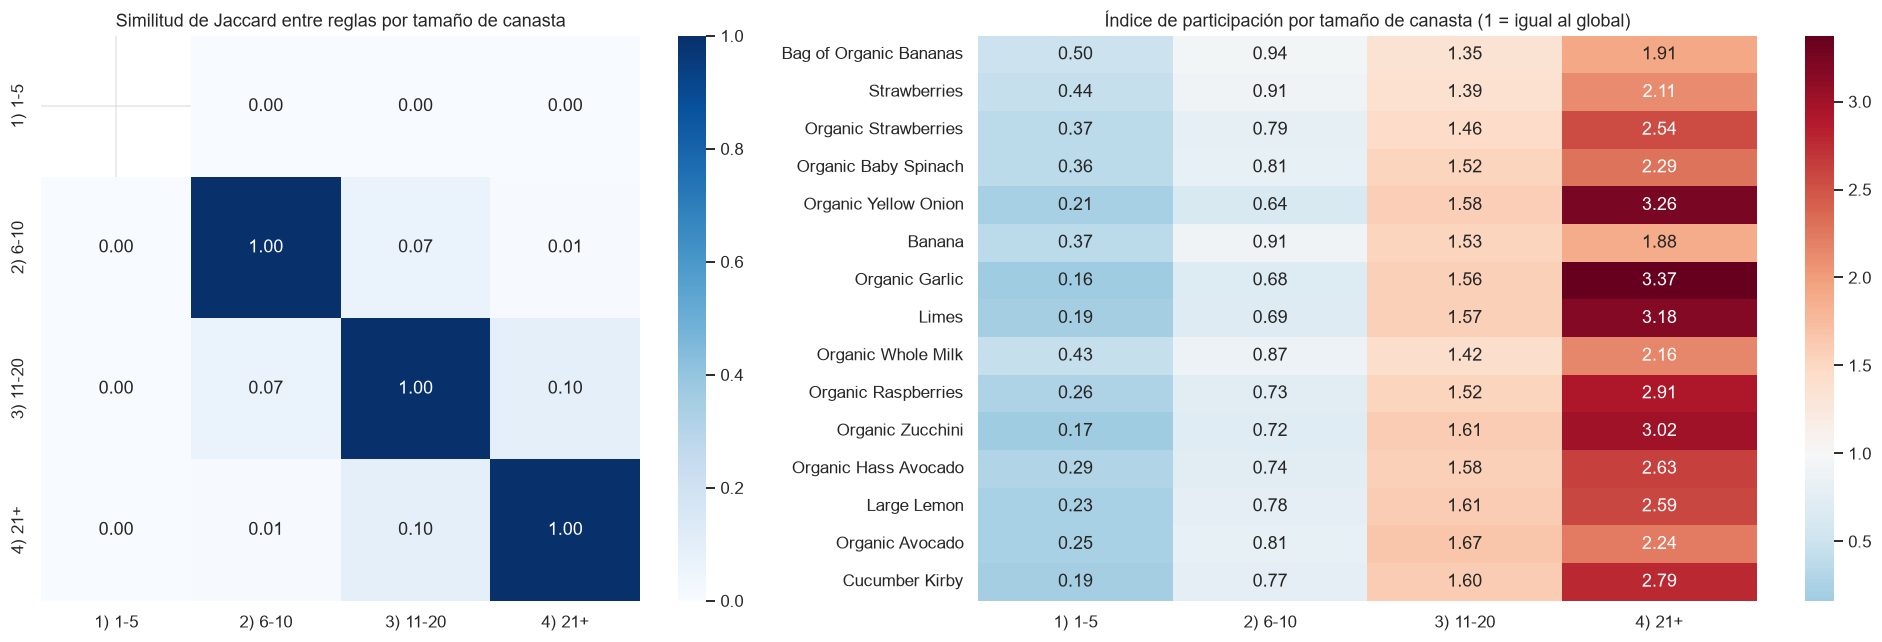

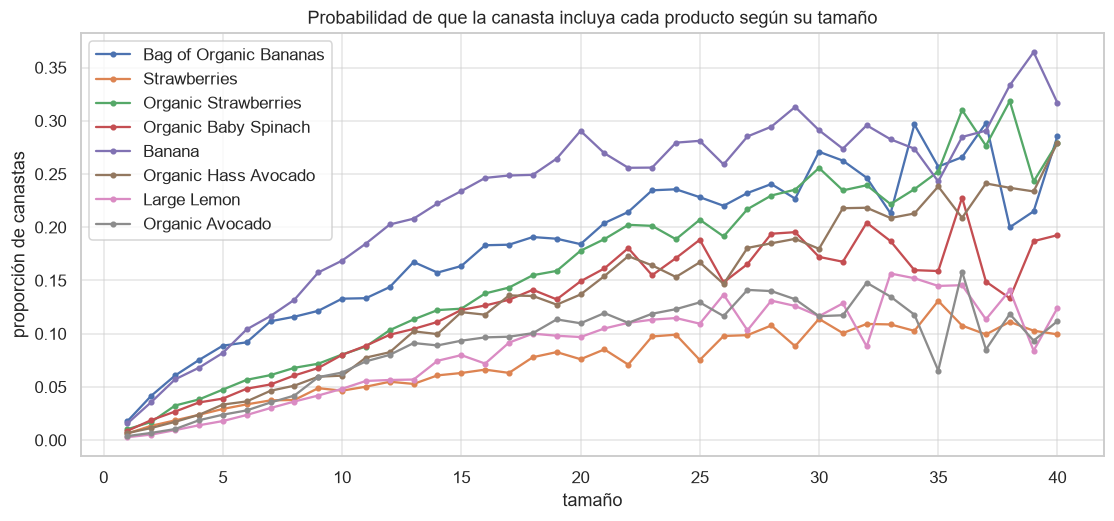

In [33]:
tam_arr = trans.n_productos.to_numpy()
grupo_tam = np.select([tam_arr <= 5, tam_arr <= 10, tam_arr <= 20], ['1) 1-5', '2) 6-10', '3) 11-20'], '4) 21+')
print(pd.Series(grupo_tam).value_counts().sort_index().to_string())
res_tam, resumen_tam, J_tam, idx_tam = analizar_segmentos(grupo_tam, 'tamaño de canasta', orden=['1) 1-5', '2) 6-10', '3) 11-20', '4) 21+'])

M8, its8 = matriz_binaria(canastas, items=TOP_IDS[:8])
df8 = pd.DataFrame(M8.toarray(), columns=[nombre_corto(i, n=25) for i in its8])
df8['tamaño'] = np.minimum(tam_arr, 40)
df8.groupby('tamaño').mean().plot(figsize=(12, 5), marker='.')
plt.title('Probabilidad de que la canasta incluya cada producto según su tamaño'); plt.ylabel('proporción de canastas'); plt.show()

De todo lo analizado, el tamaño de la canasta es lo que más cambia los patrones. Las canastas de 1 a 5 productos (32 % de los pedidos) no generan ni una regla con este soporte relativo. Las de 6 a 10 generan 44, las de 11 a 20 generan 646, y las de 21 o más generan 6,795 siendo solo el 9 % de las transacciones. El Jaccard entre grupos es casi 0 (0.10 o menos), así que cada tamaño tiene sus propias reglas.

El índice de participación muestra que los productos populares están muy sobrerrepresentados en las canastas grandes (Organic Garlic 3.37, Organic Yellow Onion 3.26 y Limes 3.18 en las de 21 o más) y subrepresentados en las chicas (0.16 a 0.50). Las canastas chicas son reposiciones rápidas de pocas cosas variadas y las grandes son la compra de la semana, con ingredientes para cocinar. El lift mediano sale parecido en los tres grupos que tienen reglas (1.54 a 1.63) porque cada grupo se compara contra su propia probabilidad base. Esto confirma algo que se retoma en la Parte 5: muchas reglas solo reflejan que el cliente compró mucho.

## 4.7 Primeras compras observadas contra compras posteriores

Se consideraron "primeras compras observadas" los pedidos 1 a 3 de cada usuario en el dataset. Puede que no sean de verdad sus primeras compras en Instacart.

                  pedidos  tamaño_medio  prop_recompra
etapa                                                 
posteriores (4+)    97684         9.887          0.683
primeras (1-3)      21849         9.823          0.232


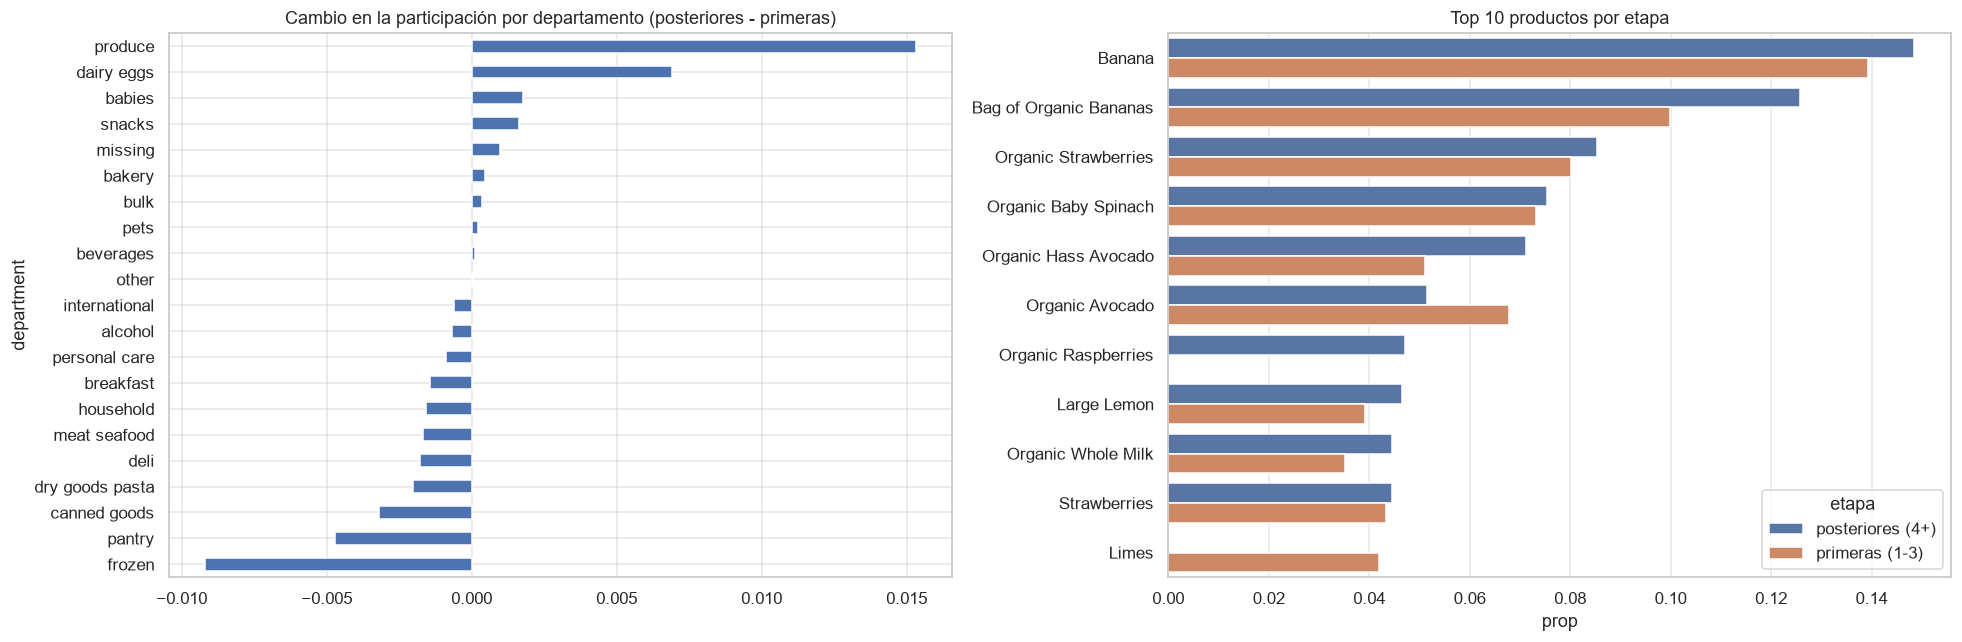

,etapa,transacciones,reglas,lift_mediano,conf_mediana,reglas_mas_fuertes
0,primeras (1-3),21849,194,2.208044,0.153430,{Bunched Cilantro} → {Limes} | {Limes} → {Bunched Cilantro} | {Organic Garlic} → {Organic Yellow Onion}
1,posteriores (4+),97684,260,2.144769,0.158499,{Organic Garlic} → {Organic Yellow Onion} | {Organic Yellow Onion} → {Organic Garlic} | {Organic Cilantro}...


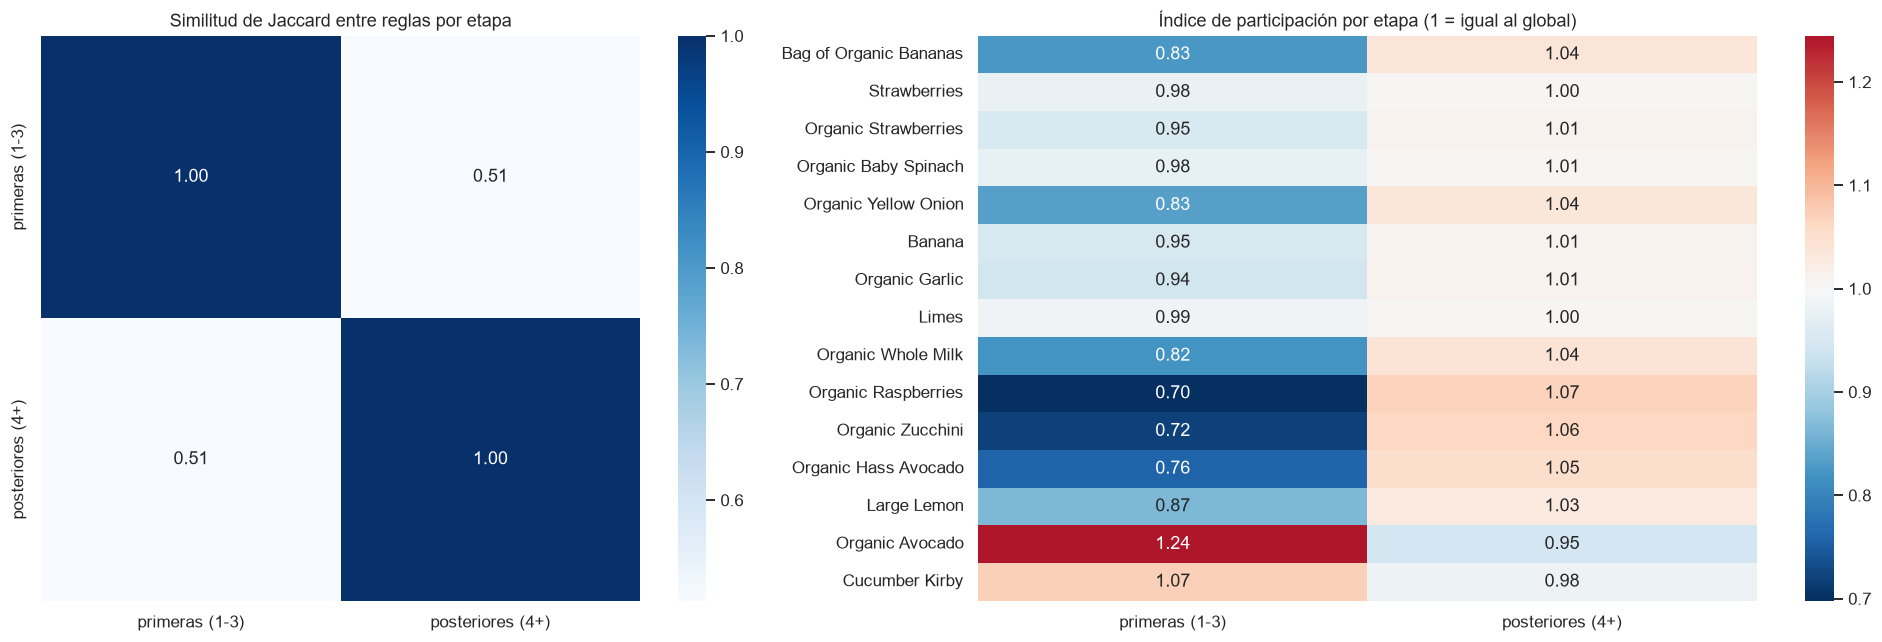

In [34]:
etapa = np.where(trans.order_number.to_numpy() <= 3, 'primeras (1-3)', 'posteriores (4+)')
trans['etapa'] = etapa
print(trans.groupby('etapa').agg(pedidos=('order_id', 'size'), tamaño_medio=('n_productos', 'mean'),
                                prop_recompra=('prop_recompra', 'mean')).round(3).to_string())

lab = pd.Series(etapa, index=trans.order_id)
datos_l['etapa'] = datos_l.order_id.map(lab)
mix = pd.crosstab(datos_l.department, datos_l.etapa, normalize='columns')
mix['diferencia'] = mix['posteriores (4+)'] - mix['primeras (1-3)']
fig, ax = plt.subplots(1, 2, figsize=(18, 6))
mix.sort_values('diferencia')['diferencia'].plot.barh(ax=ax[0], title='Cambio en la participación por departamento (posteriores - primeras)')
top_et = (datos_l.groupby(['etapa', 'product_name']).order_id.nunique()
          .div(trans.groupby('etapa').size(), level='etapa').rename('prop').reset_index())
top_et = top_et.sort_values('prop', ascending=False).groupby('etapa').head(10)
sns.barplot(data=top_et, x='prop', y='product_name', hue='etapa', ax=ax[1]); ax[1].set_title('Top 10 productos por etapa'); ax[1].set_ylabel('')
plt.tight_layout(); plt.show()
res_etapa, resumen_etapa, J_etapa, idx_etapa = analizar_segmentos(etapa, 'etapa', orden=['primeras (1-3)', 'posteriores (4+)'])

El tamaño promedio de la canasta casi no cambia entre etapas (9.8 contra 9.9 productos), pero la recompra pasa de 23 % en los pedidos 1 a 3 a 68 % del pedido 4 en adelante. Con el tiempo los usuarios dejan de explorar y repiten lo de siempre. La recompra no es cero al principio porque los pedidos 2 y 3 ya pueden repetir cosas del pedido 1.

La mezcla de departamentos se mueve hacia *produce* (+1.5 puntos) y *dairy eggs* (+0.7), y se aleja de *frozen* (−0.9), *pantry* y *canned goods*. Esto sugiere que los clientes nuevos llenan la despensa y el congelador, y los recurrentes compran sobre todo cosas frescas. Por producto, en las primeras compras sale de más Organic Avocado (1.24), mientras que Organic Raspberries, Organic Zucchini y Organic Hass Avocado aparecen más después (índice de 0.70 a 0.76 en la primera etapa). Las reglas de las dos etapas coinciden en la mitad (Jaccard 0.51) y tienen un lift mediano parecido (2.21 contra 2.14). Las combinaciones básicas (cebolla con ajo, cilantro con limón) están desde el principio, y en las compras posteriores salen más reglas (260 contra 194).

# Parte 5. Identificación de reglas engañosas

Las reglas se minan solo con el conjunto de entrenamiento y se verifican en el de prueba (pedidos posteriores de los mismos usuarios), para no evaluarlas con los mismos datos de los que salieron.

Se toman las 10 reglas que parecen más importantes, que son las de mayor confianza (con antecedentes distintos), y para cada una se calcula:
- soporte, confianza y lift en entrenamiento;
- P(C) contra la confianza, y la ganancia = confianza − P(C);
- una prueba χ² de independencia entre A y C;
- confianza y lift en prueba;
- qué tanto acierta la regla contra simplemente recomendar el producto más popular en esas mismas canastas.

In [35]:
ids_tr, cnt_tr = np.unique(np.concatenate(canastas_train), return_counts=True)
populares_tr = ids_tr[np.argsort(-cnt_tr, kind='stable')]
TOP10_POP = set(int(x) for x in populares_tr[:10])
n_tr = len(canastas_train)

reglas_tr, frec_tr = minar(canastas_train, SOPORTE_REGLAS_USADO, conf_min=CONF_MIN_REGLAS, max_len=3)
reglas_tr = decorar(reglas_tr[reglas_tr.len_consecuente == 1])
sel5 = reglas_tr.sort_values('confianza', ascending=False).drop_duplicates('antecedente').head(10).copy()

ids5 = sorted({i for a, c in zip(sel5.antecedente, sel5.consecuente) for i in a + c} | set(int(x) for x in populares_tr[:20]))
M_te5, its5 = matriz_binaria(canastas_test, items=ids5)
D_te5 = M_te5.toarray()
col5 = {int(it): j for j, it in enumerate(its5)}
def contiene(items):
    return D_te5[:, [col5[i] for i in items]].all(axis=1)

filas5 = []
for _, r_ in sel5.iterrows():
    a, c = r_.antecedente, r_.consecuente
    nA, nC, nAC = (round(x * n_tr) for x in (r_.soporte_antecedente, r_.soporte_consecuente, r_.soporte))
    chi2, p, _, _ = stats.chi2_contingency([[nAC, nA - nAC], [nC - nAC, n_tr - nA - nC + nAC]])
    A, C = contiene(a), contiene(c)
    conf_te = (A & C).sum() / A.sum() if A.sum() else np.nan
    pC_te = C.mean()
    pop1 = next(int(x) for x in populares_tr if int(x) not in a)
    acierto_pop = D_te5[A, col5[pop1]].mean() if A.sum() else np.nan
    filas5.append({'regla': r_.regla, 'soporte': r_.soporte, 'confianza': r_.confianza, 'P(C)': r_.soporte_consecuente,
                   'ganancia': r_.confianza - r_.soporte_consecuente, 'lift': r_.lift,
                   'consecuente_top10_popular': c[0] in TOP10_POP, 'p_valor_chi2': p,
                   'canastas_prueba_con_A': int(A.sum()), 'confianza_prueba': conf_te, 'P(C)_prueba': pC_te,
                   'lift_prueba': conf_te / pC_te if pC_te else np.nan,
                   'producto_popular_alternativo': nombre_prod[pop1], 'acierto_popular_prueba': acierto_pop})
eval5 = pd.DataFrame(filas5)

def veredicto(r):
    if r.lift <= 1:
        return 'NO usar: A no aumenta la probabilidad de C (la confianza viene de la popularidad de C)'
    if r.p_valor_chi2 >= 0.01 or not (r.lift_prueba >= 1.05):
        return 'NO usar: la asociación no es significativa o no se sostiene en prueba'
    if r.consecuente_top10_popular and r.ganancia < 0.05:
        return 'Uso limitado: aporta poco frente a recomendar productos populares'
    if r.confianza_prueba <= r.acierto_popular_prueba:
        return 'Uso limitado: el producto popular acierta igual o más en esas canastas'
    return 'SÍ usar: asociación real que supera a la popularidad'
eval5['veredicto'] = eval5.apply(veredicto, axis=1)
display(eval5.round(4))
eval5.to_csv(os.path.join(DIR_SALIDA, 'reglas_enganosas.csv'), index=False)

,regla,soporte,confianza,P(C),ganancia,lift,consecuente_top10_popular,p_valor_chi2,canastas_prueba_con_A,confianza_prueba,P(C)_prueba,lift_prueba,producto_popular_alternativo,acierto_popular_prueba,veredicto
0,{Total 2% Lowfat Greek Strained Yogurt with Peach} → {Total 2% with Strawberry Lowfat Greek Strained Yogurt},0.0026,0.4272,0.0102,0.4171,42.0602,False,0.0,188,0.4202,0.0100,41.8941,Banana,0.2926,SÍ usar: asociación real que supera a la popularidad
1,"{Organic Avocado, Cucumber Kirby} → {Banana}",0.0021,0.4192,0.1458,0.2734,2.8758,True,0.0,137,0.4161,0.1495,2.7829,Banana,0.4161,Uso limitado: el producto popular acierta igual o más en esas canastas
2,"{Organic Lemon, Bag of Organic Bananas} → {Organic Hass Avocado}",0.0022,0.4108,0.0656,0.3452,6.2623,True,0.0,287,0.4146,0.0729,5.6892,Banana,0.0000,SÍ usar: asociación real que supera a la popularidad
3,{Total 2% Lowfat Greek Strained Yogurt With Blueberry} → {Total 2% with Strawberry Lowfat Greek Strained Y...,0.0032,0.4094,0.0102,0.3992,40.3015,False,0.0,238,0.4454,0.0100,44.4030,Banana,0.4244,SÍ usar: asociación real que supera a la popularidad
4,{Gala Apples} → {Banana},0.0029,0.4085,0.1458,0.2627,2.8024,True,0.0,216,0.4676,0.1495,3.1276,Banana,0.4676,Uso limitado: el producto popular acierta igual o más en esas canastas
5,"{Organic Strawberries, Organic Avocado} → {Banana}",0.0029,0.4061,0.1458,0.2603,2.7859,True,0.0,213,0.3192,0.1495,2.1354,Banana,0.3192,Uso limitado: el producto popular acierta igual o más en esas canastas
6,"{Organic Baby Spinach, Organic Raspberries} → {Bag of Organic Bananas}",0.0021,0.3849,0.1134,0.2715,3.3946,True,0.0,252,0.4127,0.1413,2.9198,Banana,0.1508,SÍ usar: asociación real que supera a la popularidad
7,{Organic Bosc Pear} → {Bag of Organic Bananas},0.0024,0.3819,0.1134,0.2685,3.3679,True,0.0,249,0.4739,0.1413,3.3527,Banana,0.1486,SÍ usar: asociación real que supera a la popularidad
8,"{Large Lemon, Organic Avocado} → {Banana}",0.0026,0.3779,0.1458,0.2321,2.5924,True,0.0,293,0.3379,0.1495,2.2600,Banana,0.3379,Uso limitado: el producto popular acierta igual o más en esas canastas
9,"{Organic Raspberries, Organic Hass Avocado} → {Bag of Organic Bananas}",0.0033,0.3772,0.1134,0.2638,3.3259,True,0.0,380,0.4868,0.1413,3.4443,Banana,0.1263,SÍ usar: asociación real que supera a la popularidad


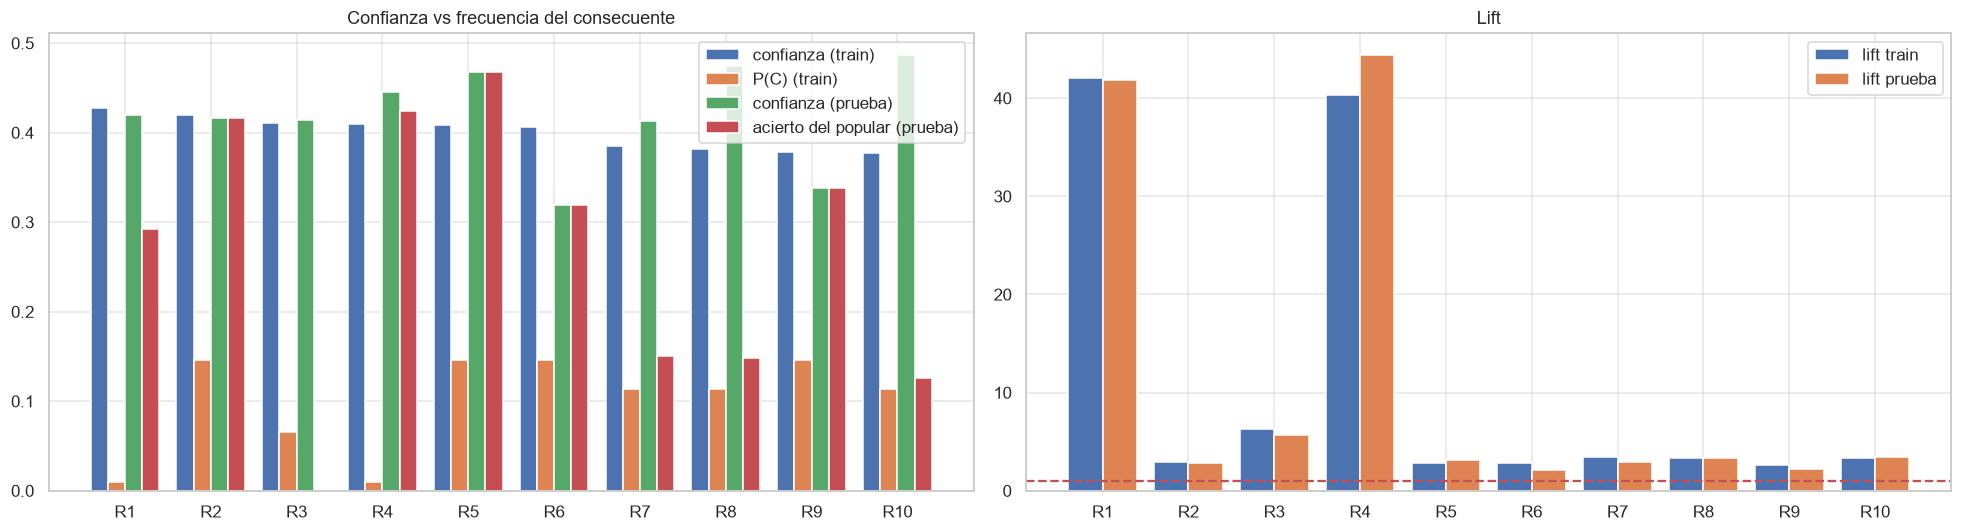

R1 {Total 2% Lowfat Greek Strained Yogurt with Peach} → {Total 2% with Strawberry Lowfat Greek Strained Yogurt}
R2 {Organic Avocado, Cucumber Kirby} → {Banana}
R3 {Organic Lemon, Bag of Organic Bananas} → {Organic Hass Avocado}
R4 {Total 2% Lowfat Greek Strained Yogurt With Blueberry} → {Total 2% with Strawberry Lowfat Greek Strained Yogurt}
R5 {Gala Apples} → {Banana}
R6 {Organic Strawberries, Organic Avocado} → {Banana}
R7 {Organic Baby Spinach, Organic Raspberries} → {Bag of Organic Bananas}
R8 {Organic Bosc Pear} → {Bag of Organic Bananas}
R9 {Large Lemon, Organic Avocado} → {Banana}
R10 {Organic Raspberries, Organic Hass Avocado} → {Bag of Organic Bananas}

De las 100 reglas con mayor confianza (entrenamiento):
  - 0% tienen lift < 1.2 y 0% tienen lift <= 1
  - 90% recomiendan un producto del top 10 de popularidad
  - correlación de Spearman entre confianza y P(C): 0.73
  - correlación de Spearman entre confianza y lift: -0.00


In [36]:
x = np.arange(len(eval5)); w = .2
etq5 = [f'R{i+1}' for i in range(len(eval5))]
fig, ax = plt.subplots(1, 2, figsize=(18, 5))
ax[0].bar(x - 1.5*w, eval5.confianza, w, label='confianza (train)')
ax[0].bar(x - .5*w, eval5['P(C)'], w, label='P(C) (train)')
ax[0].bar(x + .5*w, eval5.confianza_prueba, w, label='confianza (prueba)')
ax[0].bar(x + 1.5*w, eval5.acierto_popular_prueba, w, label='acierto del popular (prueba)')
ax[0].set_xticks(x); ax[0].set_xticklabels(etq5); ax[0].legend(); ax[0].set_title('Confianza vs frecuencia del consecuente')
ax[1].bar(x, eval5.lift, .4, label='lift train'); ax[1].bar(x + .4, eval5.lift_prueba, .4, label='lift prueba')
ax[1].axhline(1, color='r', ls='--'); ax[1].set_xticks(x + .2); ax[1].set_xticklabels(etq5); ax[1].legend(); ax[1].set_title('Lift')
plt.tight_layout(); plt.show()
for e, r_ in zip(etq5, eval5.regla):
    print(e, r_)

# Confianza alta no siempre es una asociación útil
rt = reglas_tr.sort_values('confianza', ascending=False)
top100 = rt.head(100)
print(f'\nDe las 100 reglas con mayor confianza (entrenamiento):')
print(f'  - {(top100.lift < 1.2).mean():.0%} tienen lift < 1.2 y {(top100.lift <= 1).mean():.0%} tienen lift <= 1')
print(f'  - {top100.consecuente.map(lambda c: c[0] in TOP10_POP).mean():.0%} recomiendan un producto del top 10 de popularidad')
print(f'  - correlación de Spearman entre confianza y P(C): {stats.spearmanr(rt.confianza, rt.soporte_consecuente)[0]:.2f}')
print(f'  - correlación de Spearman entre confianza y lift: {stats.spearmanr(rt.confianza, rt.lift)[0]:.2f}')

### Errores de interpretación que hay que evitar

- Confundir confianza con asociación. Si P(C) = 15 % y la confianza es 14 %, la regla "acierta" 14 % de las veces, pero recomendarle C a cualquiera acierta 15 %.
- Leerla como causa. A → C no quiere decir que comprar A *provoque* comprar C; los dos pueden venir de otra cosa, como el tipo de cliente, su dieta o el tamaño de la canasta.
- Olvidar el tamaño de la canasta. Las canastas grandes traen de todo, y muchas reglas solo dicen que el cliente compró mucho.
- Creerle a reglas con poco soporte y lift altísimo, que pueden ser ruido de unas cuantas transacciones. Por eso se exige significancia y que se sostengan en prueba.
- Asumir que funciona en los dos sentidos. A → C puede servir y C → A no, aunque tengan el mismo soporte y lift.

Las 10 reglas con mayor confianza en entrenamiento (0.38 a 0.43) son todas estadísticamente significativas (p de χ² casi 0) y mantienen lift arriba de 2 en prueba, pero con eso no basta. Ocho de las diez recomiendan un producto del top 10 de popularidad, y en cuatro (R2, R5, R6 y R9) recomendar nada más "Banana" acierta exactamente igual en esas canastas, porque el consecuente es Banana. De las 100 reglas con mayor confianza, el 90 % recomienda un producto del top 10. La confianza se correlaciona fuerte con la popularidad del consecuente (Spearman 0.73) y nada con el lift (−0.00). En cambio, las reglas del yogur Total 2 % (R1 y R4) tienen una confianza parecida pero lift de 40 a 44, y eso se sostiene en prueba (confianza de 0.42 a 0.45 contra P(C) = 1 %).

Se concluye que una regla con confianza alta solo sirve si además su lift es claramente mayor que 1, es significativa, se sostiene con datos que no vio y acierta más que recomendar el producto popular.

# Parte 6. Sistema inteligente de recomendaciones (Gradio)

Todo el análisis de las Partes 1 a 5, 7 y 8 se hizo con la muestra de unas 120 mil transacciones. El problema es que en esa muestra muchos productos no aparecen las veces suficientes para formar reglas, y en la revisión se probarán productos no conocidos. Por eso la aplicación construye su base de reglas con todas las transacciones del dataset (prior + train, unos 3.3 millones de pedidos), con la misma limpieza de Q3 + 3·IQR. No se modifica ni se inventa ningún dato, solo se usan más transacciones reales. La evaluación de la Parte 7 no usa esta base: ahí el sistema B se entrena solo con el 70 % de la muestra.

Construcción de la base de reglas:
- Reglas de un producto a otro. Son los pares que aparecen juntos al menos `MIN_CONTEO_PAR` veces, calculados con la multiplicación de matrices *XᵀX* (es lo mismo que el nivel 2 de Apriori con soporte = 5 / N). Con el dataset completo salen unos 14 millones de pares, así que de cada producto se guardan sus `TOP_K_APP_CONF` mejores reglas por confianza y sus `TOP_K_APP_LIFT` mejores por lift. La app solo muestra 5, así que no se pierde ninguna recomendación que se vea y la base cabe en memoria.
- Reglas con dos productos en el antecedente. Se obtienen con la implementación de Eclat de la Parte 2 y soporte `SOPORTE_APP`. Se usó Eclat porque trabaja con bitsets y no necesita la matriz densa de 3.3 millones de filas que pide mlxtend.

Funcionamiento del recomendador:
1. Se buscan las reglas cuyo antecedente esté completo dentro de lo que eligió el usuario.
2. Se aplican los umbrales de soporte, confianza y lift elegidos en la interfaz.
3. Se descartan los productos que el usuario ya eligió.
4. De cada producto candidato se conserva su mejor regla según el criterio elegido (confianza por defecto, y si empatan, lift) y se devuelven los 5 primeros.
5. Si no hay reglas que apliquen, se explica el motivo. Solo si el usuario lo activa, se completa con productos populares marcados como tales.

In [37]:
# Transacciones completas del dataset (prior + train) con la misma limpieza que la muestra
t0 = time.perf_counter()
op_all = pd.concat([pd.read_csv(RUTAS[a], usecols=['order_id', 'product_id'], dtype='int32')
                    for a in ['order_products__prior.csv', 'order_products__train.csv']], ignore_index=True)
tam_all = op_all.groupby('order_id').size()
q1a, q3a = tam_all.quantile([.25, .75])
lim_all = q3a + 3 * (q3a - q1a)
op_all = op_all[op_all.order_id.isin(tam_all.index[tam_all <= lim_all])].drop_duplicates()
op_all = op_all.sort_values(['order_id', 'product_id'])
o_all = op_all.order_id.to_numpy()
canastas_all = np.split(op_all.product_id.to_numpy().astype(np.int64), np.flatnonzero(np.diff(o_all)) + 1)
N_ALL = len(canastas_all)
del op_all, o_all; gc.collect()
print(f'Transacciones completas: {len(tam_all):,} | atípicas eliminadas (> {lim_all:.0f} productos): '
      f'{(tam_all > lim_all).sum():,} | usadas: {N_ALL:,} ({time.perf_counter()-t0:.1f} s)')

Transacciones completas: 3,346,083 | atípicas eliminadas (> 41 productos): 12,364 | usadas: 3,333,719 (24.2 s)


In [38]:
def minador_eclat(cs, s, max_len):
    M_, it_ = matriz_binaria(cs, min_conteo=conteo_minimo(s, len(cs)))
    return eclat_propio(M_, it_, s, max_len=max_len)

t0 = time.perf_counter()
base_app = construir_base(canastas_all, SOPORTE_APP, MIN_CONTEO_PAR, max_len=3,
                          top_k_conf=TOP_K_APP_CONF, top_k_lift=TOP_K_APP_LIFT, minador=minador_eclat)
ids_all, cnt_all = np.unique(np.concatenate(canastas_all), return_counts=True)
populares_app = ids_all[np.argsort(-cnt_all, kind='stable')]
rec_app = Recomendador(base_app, populares_app)
print(f'Base de reglas: {len(base_app):,} reglas ({(base_app.len_antecedente == 1).sum():,} de 1 producto, '
      f'{(base_app.len_antecedente >= 2).sum():,} de 2+) en {time.perf_counter()-t0:.1f} s')
print(f'Productos con al menos una regla: {len(rec_app.items_con_reglas):,} de {len(ids_all):,} vendidos en el dataset '
      f'({len(rec_app.items_con_reglas)/len(ids_all):.1%})')
con_muestra = len(set(reglas_pares(canastas, MIN_CONTEO_PAR).antecedente.map(lambda t: t[0])))
print(f'Con solo la muestra de {N:,} transacciones tendrían reglas {con_muestra:,} productos '
      f'({con_muestra/len(ids_all):.1%} del dataset)')

with open(os.path.join(DIR_SALIDA, 'recomendador.pkl'), 'wb') as f:
    pickle.dump(rec_app, f, protocol=pickle.HIGHEST_PROTOCOL)
frec_all = pd.DataFrame({'product_id': ids_all, 'n_transacciones': cnt_all})
prod_out = productos[['product_id', 'product_name', 'aisle', 'department']].merge(
    frec_all, on='product_id', how='left').fillna({'n_transacciones': 0})
prod_out['n_transacciones'] = prod_out.n_transacciones.astype(int)
prod_out.to_csv(os.path.join(DIR_SALIDA, 'productos.csv'), index=False)
with open(os.path.join(DIR_SALIDA, 'meta.json'), 'w') as f:
    json.dump({'n_transacciones': int(N_ALL)}, f)
del canastas_all; gc.collect()
print('Artefactos guardados en', DIR_SALIDA,
      f'| recomendador.pkl = {os.path.getsize(os.path.join(DIR_SALIDA, "recomendador.pkl"))/2**20:.0f} MB')

Base de reglas: 1,071,319 reglas (1,070,704 de 1 producto, 615 de 2+) en 289.3 s
Productos con al menos una regla: 37,308 de 49,680 vendidos en el dataset (75.1%)
Con solo la muestra de 119,533 transacciones tendrían reglas 11,133 productos (22.4% del dataset)
Artefactos guardados en artefactos | recomendador.pkl = 167 MB


In [39]:
%%writefile app.py
import os
import json
import pickle

import pandas as pd
import gradio as gr

from nucleo_reglas import Recomendador  # necesario para cargar el pickle

DIR = os.environ.get('DIR_ARTEFACTOS', '/content/artefactos')
with open(os.path.join(DIR, 'recomendador.pkl'), 'rb') as f:
    REC = pickle.load(f)
with open(os.path.join(DIR, 'meta.json')) as f:
    N_TRANS = json.load(f)['n_transacciones']
PROD = pd.read_csv(os.path.join(DIR, 'productos.csv'))
NOMBRE = dict(zip(PROD.product_id, PROD.product_name))
DEPTO = dict(zip(PROD.product_id, PROD.department))
FREC = dict(zip(PROD.product_id, PROD.n_transacciones))

PROD['etiqueta'] = PROD.product_name
dup = PROD.product_name.duplicated(keep=False)
PROD.loc[dup, 'etiqueta'] = PROD.product_name + ' (#' + PROD.product_id.astype(str) + ')'
ETIQ2ID = dict(zip(PROD.etiqueta, PROD.product_id))
ID2ETIQ = dict(zip(PROD.product_id, PROD.etiqueta))
ORDEN = PROD.sort_values(['n_transacciones', 'product_name'], ascending=[False, True]).etiqueta.tolist()
INICIALES = ORDEN[:100]
COLUMNAS = ['#', 'Producto recomendado', 'Departamento', 'Soporte', 'Confianza', 'Lift', 'Regla usada', 'Por qué se recomienda']


def nombres(ids):
    return ', '.join(NOMBRE.get(int(i), str(i)) for i in ids)


def buscar(texto, seleccion):
    seleccion = seleccion or []
    t = (texto or '').strip().lower()
    coinc = [e for e in ORDEN if t in e.lower()][:80] if t else INICIALES
    return gr.update(choices=list(dict.fromkeys(list(seleccion) + coinc)), value=seleccion)


def explicar(b, p):
    txt = (f"De las canastas que contienen {{{nombres(b.antecedente)}}}, el {b.confianza:.1%} también incluyó "
           f"'{NOMBRE.get(p)}'. Eso es {b.lift:.2f} veces su frecuencia general ({b.soporte_consecuente:.2%} de las canastas). "
           f"El patrón aparece en {int(b.n_transacciones):,} pedidos ({b.soporte:.3%} del total).")
    if b.lift < 1:
        txt += ' Ojo: lift < 1, comprar el antecedente reduce la probabilidad de este producto.'
    return txt


def recomendar(seleccion, min_sop, min_conf, min_lift, criterio, rellenar):
    seleccion = seleccion or []
    if not 1 <= len(seleccion) <= 5:
        return 'Selecciona entre 1 y 5 productos.', pd.DataFrame(columns=COLUMNAS)
    ids = [int(ETIQ2ID[e]) for e in seleccion]
    recs = REC.recomendar(ids, k=5, min_soporte=min_sop, min_confianza=min_conf, min_lift=min_lift,
                          criterio=criterio, rellenar=rellenar)
    sin_reglas = [NOMBRE[i] for i in ids if i not in REC.items_con_reglas]
    aplicables = len(REC.candidatos(frozenset(ids)))
    filas = []
    for pos, d in enumerate(recs, 1):
        p = d['producto']
        if d['origen'] == 'reglas':
            b = REC.base.iloc[d['regla']]
            filas.append([pos, NOMBRE.get(p), DEPTO.get(p), round(b.soporte, 7), round(b.confianza, 4), round(b.lift, 3),
                          '{' + nombres(b.antecedente) + '} → {' + NOMBRE.get(p) + '}', explicar(b, p)])
        else:
            filas.append([pos, NOMBRE.get(p), DEPTO.get(p), round(FREC.get(p, 0) / N_TRANS, 7), None, None,
                          '(sin regla)', f'Relleno por popularidad: está en {FREC.get(p, 0):,} pedidos. '
                          'No hubo suficientes reglas que cumplieran los umbrales.'])
    n_reglas = sum(d['origen'] == 'reglas' for d in recs)
    msg = [f'**Selección:** {", ".join(NOMBRE[i] for i in ids)}',
           f'Reglas cuyo antecedente está contenido en la selección: **{aplicables:,}**; recomendaciones basadas en reglas: **{n_reglas}**.']
    if sin_reglas:
        msg.append(f'Nota: no hay reglas en la base para estos productos (productos poco frecuentes o no vistos): {", ".join(sin_reglas)}.')
    if n_reglas == 0 and rellenar:
        msg.append('**No hay reglas aplicables con estos umbrales**, así que la lista se completó con los productos '
                   'más populares (marcados como "sin regla"). Prueba a bajar la confianza o el lift mínimos o agregar otro producto más común.')
    elif n_reglas == 0:
        msg.append('**No hay reglas aplicables con estos umbrales.** Prueba a bajar la confianza o el lift mínimos, '
                   'agregar otro producto más común o activar "Completar con productos populares".')
    elif n_reglas < 5:
        msg.append(f'Solo se encontraron {n_reglas} productos que cumplen los umbrales.')
    return '\n\n'.join(msg), pd.DataFrame(filas, columns=COLUMNAS)


with gr.Blocks(title='Recomendador Instacart') as demo:
    gr.Markdown('# Recomendador de productos por reglas de asociación\n'
                'Busca y elige de 1 a 5 productos, ajusta los umbrales y presiona **Recomendar**.')
    with gr.Row():
        with gr.Column(scale=2):
            busqueda = gr.Textbox(label='Buscar producto', placeholder='ej. banana, yogurt, limes')
            seleccion = gr.Dropdown(choices=INICIALES, value=[], multiselect=True, max_choices=5,
                                    label='Productos seleccionados (1 a 5)')
        with gr.Column(scale=1):
            s_sop = gr.Slider(0, 0.01, value=0.0, step=0.00005, label='Soporte mínimo')
            s_conf = gr.Slider(0, 1, value=0.05, step=0.01, label='Confianza mínima')
            s_lift = gr.Slider(0, 10, value=1.0, step=0.05, label='Lift mínimo')
            criterio = gr.Radio(['confianza', 'lift', 'leverage'], value='confianza', label='Ordenar por')
            rellenar = gr.Checkbox(value=False, label='Completar con productos populares si faltan reglas')
    boton = gr.Button('Recomendar', variant='primary')
    mensaje = gr.Markdown()
    tabla = gr.Dataframe(headers=COLUMNAS, wrap=True, interactive=False)
    busqueda.change(buscar, [busqueda, seleccion], seleccion)
    boton.click(recomendar, [seleccion, s_sop, s_conf, s_lift, criterio, rellenar], [mensaje, tabla])

if __name__ == '__main__':
    demo.launch()

Overwriting app.py


In [40]:
# Prueba del sistema sin interfaz (incluye casos sin reglas)
os.environ['DIR_ARTEFACTOS'] = DIR_SALIDA
import app
importlib.reload(app)

set_muestra, set_all = set(ids_u.tolist()), set(ids_all.tolist())
raros = frec_l[frec_l.n_transacciones <= 2].product_id.head(1).tolist()
no_vistos = [int(i) for i in productos.product_id if int(i) not in set_muestra and int(i) in set_all][:1]
nunca_vendidos = [int(i) for i in productos.product_id if int(i) not in set_all][:1]
casos_demo = {
    'Producto más popular': [int(populares_all[0])],
    'Dos productos populares': [int(populares_all[1]), int(populares_all[4])],
    'Tres productos': [int(x) for x in populares_all[[2, 6, 12]]],
    'Producto poco frecuente en la muestra': [int(x) for x in raros],
    'Producto que no aparece en la muestra': no_vistos,
    'Producto que nunca se vendió en el dataset': nunca_vendidos,
}
for nombre_caso, ids in casos_demo.items():
    if not ids:
        continue
    print('=' * 60, '\n', nombre_caso)
    msg, tabla = app.recomendar([app.ID2ETIQ[i] for i in ids], 0.0, 0.05, 1.0, 'confianza', False)
    print(msg); display(tabla)
msg, tabla = app.recomendar([app.ID2ETIQ[i] for i in (nunca_vendidos or raros)], 0.0, 0.05, 1.0, 'confianza', True)
print('Con relleno por popularidad activado:\n', msg); display(tabla)

 Producto más popular
**Selección:** Banana

Reglas cuyo antecedente está contenido en la selección: **50**; recomendaciones basadas en reglas: **5**.


,#,Producto recomendado,Departamento,Soporte,Confianza,Lift,Regla usada,Por qué se recomienda
0,1,Organic Strawberries,produce,0.017213,0.1177,1.441,{Banana} → {Organic Strawberries},"De las canastas que contienen {Banana}, el 11.8% también incluyó 'Organic Strawberries'. Eso es 1.44 veces..."
1,2,Organic Avocado,produce,0.016437,0.1124,2.054,{Banana} → {Organic Avocado},"De las canastas que contienen {Banana}, el 11.2% también incluyó 'Organic Avocado'. Eso es 2.05 veces su f..."
2,3,Organic Baby Spinach,produce,0.015784,0.1080,1.446,{Banana} → {Organic Baby Spinach},"De las canastas que contienen {Banana}, el 10.8% también incluyó 'Organic Baby Spinach'. Eso es 1.45 veces..."
3,4,Strawberries,produce,0.012717,0.0870,1.963,{Banana} → {Strawberries},"De las canastas que contienen {Banana}, el 8.7% también incluyó 'Strawberries'. Eso es 1.96 veces su frecu..."
4,5,Large Lemon,produce,0.012643,0.0865,1.816,{Banana} → {Large Lemon},"De las canastas que contienen {Banana}, el 8.6% también incluyó 'Large Lemon'. Eso es 1.82 veces su frecue..."


 Dos productos populares
**Selección:** Bag of Organic Bananas, Organic Hass Avocado

Reglas cuyo antecedente está contenido en la selección: **131**; recomendaciones basadas en reglas: **5**.


,#,Producto recomendado,Departamento,Soporte,Confianza,Lift,Regla usada,Por qué se recomienda
0,1,Organic Strawberries,produce,0.004530,0.2386,2.921,"{Bag of Organic Bananas, Organic Hass Avocado} → {Organic Strawberries}","De las canastas que contienen {Bag of Organic Bananas, Organic Hass Avocado}, el 23.9% también incluyó 'Or..."
1,2,Organic Baby Spinach,produce,0.003645,0.1920,2.571,"{Bag of Organic Bananas, Organic Hass Avocado} → {Organic Baby Spinach}","De las canastas que contienen {Bag of Organic Bananas, Organic Hass Avocado}, el 19.2% también incluyó 'Or..."
2,3,Organic Raspberries,produce,0.003422,0.1802,4.284,"{Bag of Organic Bananas, Organic Hass Avocado} → {Organic Raspberries}","De las canastas que contienen {Bag of Organic Bananas, Organic Hass Avocado}, el 18.0% también incluyó 'Or..."
3,4,Organic Lemon,produce,0.002377,0.1252,4.646,"{Bag of Organic Bananas, Organic Hass Avocado} → {Organic Lemon}","De las canastas que contienen {Bag of Organic Bananas, Organic Hass Avocado}, el 12.5% también incluyó 'Or..."
4,5,Organic Yellow Onion,produce,0.002102,0.1107,3.181,"{Bag of Organic Bananas, Organic Hass Avocado} → {Organic Yellow Onion}","De las canastas que contienen {Bag of Organic Bananas, Organic Hass Avocado}, el 11.1% también incluyó 'Or..."


 Tres productos
**Selección:** Organic Strawberries, Large Lemon, Organic Garlic

Reglas cuyo antecedente está contenido en la selección: **163**; recomendaciones basadas en reglas: **5**.


,#,Producto recomendado,Departamento,Soporte,Confianza,Lift,Regla usada,Por qué se recomienda
0,1,Banana,produce,0.001677,0.3332,2.279,"{Organic Strawberries, Large Lemon} → {Banana}","De las canastas que contienen {Organic Strawberries, Large Lemon}, el 33.3% también incluyó 'Banana'. Eso ..."
1,2,Bag of Organic Bananas,produce,0.001376,0.2934,2.500,"{Organic Strawberries, Organic Garlic} → {Bag of Organic Bananas}","De las canastas que contienen {Organic Strawberries, Organic Garlic}, el 29.3% también incluyó 'Bag of Org..."
2,3,Limes,produce,0.001159,0.2453,5.665,"{Organic Garlic, Large Lemon} → {Limes}","De las canastas que contienen {Organic Garlic, Large Lemon}, el 24.5% también incluyó 'Limes'. Eso es 5.67..."
3,4,Organic Baby Spinach,produce,0.001105,0.2337,3.129,"{Organic Garlic, Large Lemon} → {Organic Baby Spinach}","De las canastas que contienen {Organic Garlic, Large Lemon}, el 23.4% también incluyó 'Organic Baby Spinac..."
4,5,Organic Hass Avocado,produce,0.001095,0.2336,3.573,"{Organic Strawberries, Organic Garlic} → {Organic Hass Avocado}","De las canastas que contienen {Organic Strawberries, Organic Garlic}, el 23.4% también incluyó 'Organic Ha..."


... (4 outputs left out)

 Producto que nunca se vendió en el dataset
**Selección:** Protein Granola Apple Crisp

Reglas cuyo antecedente está contenido en la selección: **0**; recomendaciones basadas en reglas: **0**.

Nota: no hay reglas en la base para estos productos (productos poco frecuentes o no vistos): Protein Granola Apple Crisp.

**No hay reglas aplicables con estos umbrales.** Prueba a bajar la confianza o el lift mínimos, agregar otro producto más común o activar "Completar con productos populares".


,#,Producto recomendado,Departamento,Soporte,Confianza,Lift,Regla usada,Por qué se recomienda


Con relleno por popularidad activado:
 **Selección:** Protein Granola Apple Crisp

Reglas cuyo antecedente está contenido en la selección: **0**; recomendaciones basadas en reglas: **0**.

Nota: no hay reglas en la base para estos productos (productos poco frecuentes o no vistos): Protein Granola Apple Crisp.

**No hay reglas aplicables con estos umbrales**, así que la lista se completó con los productos más populares (marcados como "sin regla"). Prueba a bajar la confianza o el lift mínimos o agregar otro producto más común.


,#,Producto recomendado,Departamento,Soporte,Confianza,Lift,Regla usada,Por qué se recomienda
0,1,Banana,produce,0.146191,None,None,(sin regla),"Relleno por popularidad: está en 487,359 pedidos. No hubo suficientes reglas que cumplieran los umbrales."
1,2,Bag of Organic Bananas,produce,0.117359,None,None,(sin regla),"Relleno por popularidad: está en 391,242 pedidos. No hubo suficientes reglas que cumplieran los umbrales."
2,3,Organic Strawberries,produce,0.081691,None,None,(sin regla),"Relleno por popularidad: está en 272,336 pedidos. No hubo suficientes reglas que cumplieran los umbrales."
3,4,Organic Baby Spinach,produce,0.074689,None,None,(sin regla),"Relleno por popularidad: está en 248,992 pedidos. No hubo suficientes reglas que cumplieran los umbrales."
4,5,Organic Hass Avocado,produce,0.065371,None,None,(sin regla),"Relleno por popularidad: está en 217,930 pedidos. No hubo suficientes reglas que cumplieran los umbrales."


In [41]:
# Lanzar la aplicación
# En Colab se genera un enlace público; en local se abre en http://127.0.0.1:7860
app.demo.launch(share=EN_COLAB, debug=False, inbrowser=not EN_COLAB)

* Running on local URL:  http://127.0.0.1:7860
* To create a public link, set `share=True` in `launch()`.


Para correr la app fuera de Colab hay que copiar `app.py`, `nucleo_reglas.py` y la carpeta `artefactos/`, y ejecutar `DIR_ARTEFACTOS=artefactos python app.py`.

# Parte 7. Comparación y evaluación

Para entrenar se usa el primer 70 % de los pedidos de cada usuario y para probar el último 30 % (Parte 1.8). Se toman `N_CANASTAS_EVAL` canastas de prueba con al menos 2 productos (con semilla fija) y en cada una se oculta al azar la mitad de los productos, dejando al menos 1 oculto y 1 visible. Hasta 5 productos visibles se le dan al sistema como entrada, igual que en la app.

Se comparan dos sistemas:
- Sistema A: recomienda los 5 productos más populares del entrenamiento que no estén en la entrada.
- Sistema B: usa las reglas aprendidas solo con entrenamiento (lift ≥ `LIFT_MIN_EVAL`). Se prueban tres versiones: ordenando por confianza, ordenando por lift, y B+, que rellena con populares cuando faltan reglas.

Las métricas son:
- Precision@5 = aciertos / 5 (si el sistema da menos de 5, los huecos cuentan como fallos).
- Recall@5 = aciertos / productos ocultos.
- Cobertura del catálogo = productos distintos recomendados / productos del entrenamiento.
- Tiempo promedio por consulta.

Para ver si la diferencia es significativa se usa la prueba de Wilcoxon pareada por canasta.

In [42]:
base_tr = construir_base(canastas_train, SOPORTE_REGLAS_USADO, MIN_CONTEO_PAR)
rec_tr = Recomendador(base_tr, populares_tr)
catalogo_tr = set(int(x) for x in ids_tr)
cnt_tr_dict = dict(zip(ids_tr.tolist(), cnt_tr.tolist()))
print(f'Base de entrenamiento: {len(base_tr):,} reglas | productos con reglas: {len(rec_tr.items_con_reglas):,} de {len(catalogo_tr):,}')

rng_eval = np.random.default_rng(SEMILLA)
elegibles = np.array([i for i in idx_test if len(canastas[i]) >= 2])
muestra_eval = rng_eval.choice(elegibles, size=min(N_CANASTAS_EVAL, len(elegibles)), replace=False)
casos = []
for i in muestra_eval:
    c = rng_eval.permutation(canastas[i])
    n_o = min(max(1, int(round(PROP_OCULTA * len(c)))), len(c) - 1)
    casos.append((int(i), [int(x) for x in c[n_o:][:K_ENTRADA_MAX]], set(int(x) for x in c[:n_o])))
print(f'Casos de evaluación: {len(casos):,} | productos visibles promedio: {np.mean([len(v) for _, v, _ in casos]):.2f} | '
      f'ocultos promedio: {np.mean([len(o) for _, _, o in casos]):.2f}')

def evaluar(sistemas, casos, catalogo):
    resumen_, detalle = [], {}
    for nombre, fn in sistemas.items():
        prec, rec_, tiempos, recomendados, vacios, hits_items = [], [], [], set(), 0, []
        for _, vis, ocu in casos:
            t0 = time.perf_counter(); r = fn(vis); tiempos.append(time.perf_counter() - t0)
            rs = set(r)
            aciertos = len(rs & ocu)
            prec.append(aciertos / K); rec_.append(aciertos / len(ocu))
            recomendados.update(r); vacios += len(r) == 0
            hits_items.extend((o, o in rs) for o in ocu)
        resumen_.append({'Sistema': nombre, 'Precision@5': np.mean(prec), 'Recall@5': np.mean(rec_),
                         'Cobertura_catalogo': len(recomendados & catalogo) / len(catalogo),
                         'Productos_distintos_recomendados': len(recomendados),
                         'Tiempo_promedio_ms': 1000 * np.mean(tiempos), '%_casos_sin_recomendacion': vacios / len(casos)})
        detalle[nombre] = {'prec': np.array(prec), 'rec': np.array(rec_), 'hits_items': hits_items}
    return pd.DataFrame(resumen_), detalle

SISTEMAS = {
    'A: Popularidad': lambda v: recomendar_populares(populares_tr, v, K),
    'B: Reglas (confianza)': lambda v: rec_tr.recomendar_ids(v, K, min_lift=LIFT_MIN_EVAL, criterio='confianza'),
    'B: Reglas (lift)': lambda v: rec_tr.recomendar_ids(v, K, min_lift=LIFT_MIN_EVAL, criterio='lift'),
    'B+: Reglas + relleno popular': lambda v: rec_tr.recomendar_ids(v, K, min_lift=LIFT_MIN_EVAL, criterio='confianza', rellenar=True),
}
resultados7, detalle7 = evaluar(SISTEMAS, casos, catalogo_tr)
display(resultados7.round(4))
resultados7.to_csv(os.path.join(DIR_SALIDA, 'evaluacion_sistemas.csv'), index=False)

Base de entrenamiento: 380,405 reglas | productos con reglas: 9,165 de 30,200
Casos de evaluación: 5,000 | productos visibles promedio: 3.85 | ocultos promedio: 5.39


,Sistema,Precision@5,Recall@5,Cobertura_catalogo,Productos_distintos_recomendados,Tiempo_promedio_ms,%_casos_sin_recomendacion
0,A: Popularidad,0.0571,0.0562,0.0003,9,0.0027,0.0000
1,B: Reglas (confianza),0.0843,0.0892,0.0758,2288,0.8157,0.0206
2,B: Reglas (lift),0.0233,0.0251,0.1615,4877,1.3132,0.0206
3,B+: Reglas + relleno popular,0.0845,0.0899,0.0758,2288,0.5471,0.0000


,Sistema B,métrica,diferencia_media (B - A),p_valor_wilcoxon
0,B: Reglas (confianza),Precision@5,0.02724,0.0
1,B: Reglas (confianza),Recall@5,0.03296,0.0
2,B: Reglas (lift),Precision@5,-0.03376,0.0
3,B: Reglas (lift),Recall@5,-0.03111,0.0
4,B+: Reglas + relleno popular,Precision@5,0.02744,0.0
5,B+: Reglas + relleno popular,Recall@5,0.03366,0.0


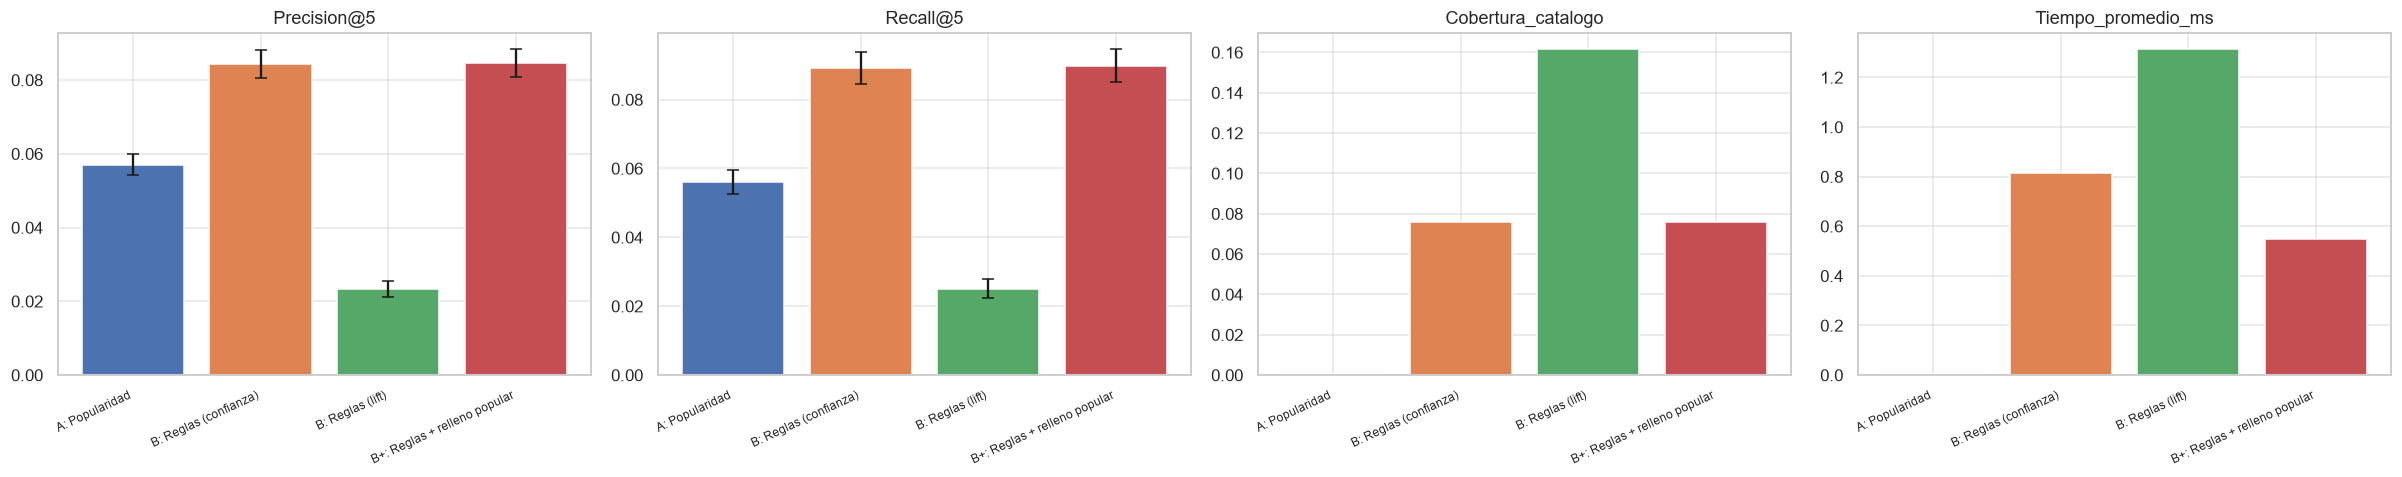

Ejemplo. Entrada: ['Raspberry Lime Seltzer', 'Clean Day Basil Hand Soap', 'Salted Butter', 'Sourdough English Muffins'] 
ocultos: ['Large Alfresco Eggs', 'Goldfish Cheddar Baked Snack Crackers', 'Ultra Soft Mega Rolls  Bathroom Tissue', 'Unsweetened Almondmilk']
  A: Popularidad                 ['Banana', 'Bag of Organic Bananas', 'Organic Strawberries', 'Organic Baby Spinach', 'Organic Hass Avocado']
  B: Reglas (confianza)          ['Banana', 'Lemon Seltzer', 'Granny Smith Apples', 'Organic Half & Half', 'Organic 1% Milk']
  B: Reglas (lift)               ['Chocolate Squares Premium A...', 'Diet Ginger Ale Soda', 'Lemon Seltzer', 'Organic Kosher Dill Baby Pi...', 'Passion Fruit On The Bottom...']
  B+: Reglas + relleno popular   ['Banana', 'Lemon Seltzer', 'Granny Smith Apples', 'Organic Half & Half', 'Organic 1% Milk']


In [43]:
pA = detalle7['A: Popularidad']
filas_sig = []
for nombre in list(SISTEMAS)[1:]:
    for met in ['prec', 'rec']:
        dif = detalle7[nombre][met] - pA[met]
        try:
            p = stats.wilcoxon(detalle7[nombre][met], pA[met]).pvalue
        except ValueError:
            p = np.nan
        filas_sig.append({'Sistema B': nombre, 'métrica': 'Precision@5' if met == 'prec' else 'Recall@5',
                          'diferencia_media (B - A)': dif.mean(), 'p_valor_wilcoxon': p})
sig7 = pd.DataFrame(filas_sig)
display(sig7.round(5))

fig, ax = plt.subplots(1, 4, figsize=(22, 4.5))
for a, met, key in zip(ax[:2], ['Precision@5', 'Recall@5'], ['prec', 'rec']):
    err = [1.96 * detalle7[s][key].std() / np.sqrt(len(casos)) for s in resultados7.Sistema]
    a.bar(range(len(resultados7)), resultados7[met], yerr=err, capsize=4, color=sns.color_palette()[:len(resultados7)])
    a.set_title(met); a.set_xticks(range(len(resultados7))); a.set_xticklabels(resultados7.Sistema, rotation=25, ha='right', fontsize=8)
for a, met in zip(ax[2:], ['Cobertura_catalogo', 'Tiempo_promedio_ms']):
    a.bar(range(len(resultados7)), resultados7[met], color=sns.color_palette()[:len(resultados7)])
    a.set_title(met); a.set_xticks(range(len(resultados7))); a.set_xticklabels(resultados7.Sistema, rotation=25, ha='right', fontsize=8)
plt.tight_layout(); plt.show()

i0, vis0, ocu0 = casos[0]
print('Ejemplo. Entrada:', [nombre_prod[i] for i in vis0], '\nocultos:', [nombre_prod[i] for i in ocu0])
for s, fn in SISTEMAS.items():
    print(f'  {s:30s}', [nombre_corto(i) for i in fn(vis0)])

El sistema de reglas ordenado por confianza (B) le gana a la popularidad (A): Precision@5 de 0.084 contra 0.057 (+48 %) y Recall@5 de 0.089 contra 0.056 (+59 %). La diferencia es significativa: el p de la prueba de Wilcoxon es prácticamente 0. Además, B recomienda 2,288 productos distintos (7.6 % del catálogo de entrenamiento), mientras que A siempre recomienda los mismos 9 (0.03 %); B se adapta a cada canasta y A no. Lo que cuesta es el tiempo, 0.77 ms por consulta contra 0.003 ms, que para una app interactiva no se nota.

B se queda sin recomendación en el 2.1 % de los casos (entradas sin reglas). B+ rellena esos huecos con populares, resuelve ese problema y sube un poquito (P@5 = 0.0845). Ordenar por lift sale contraproducente: P@5 baja a 0.023, peor que la popularidad, porque el lift favorece consecuentes raros con muy pocas transacciones. Sube la cobertura (16 %) pero pierde relevancia, como se ve en el ejemplo de arriba, donde por lift recomienda chocolates y pepinillos que casi nadie compra.

# Parte 8. Experimentos de robustez

Se reconstruye la base de reglas del sistema B en cinco escenarios y se compara contra la original:

| Escenario | Cambio |
|---|---|
| Original | 100 % del entrenamiento, soporte de la Parte 3, conteo mínimo de pares = 5 |
| Entrenamiento −10 % / −20 % | Se eliminan al azar el 10 % o el 20 % de las transacciones de entrenamiento |
| Soporte ×0.8 / ×1.5 / ×2 | Se multiplican el soporte de los conjuntos y el conteo mínimo de pares |

En cada escenario se mide el número de reglas, el porcentaje de reglas originales que se quedan, la similitud de Jaccard, qué tan estable es el lift (Spearman entre las reglas que comparten) y el desempeño en `N_EVAL_ROBUSTEZ` casos de prueba.

In [44]:
rng8 = np.random.default_rng(SEMILLA + 8)
def submuestra(frac_quitar):
    keep = np.sort(rng8.choice(n_tr, size=int(round(n_tr * (1 - frac_quitar))), replace=False))
    return [canastas_train[i] for i in keep]

VARIANTES = {
    'Original': (canastas_train, 1.0),
    'Entrenamiento -10%': (submuestra(0.10), 1.0),
    'Entrenamiento -20%': (submuestra(0.20), 1.0),
    'Soporte x0.8': (canastas_train, 0.8),
    'Soporte x1.5': (canastas_train, 1.5),
    'Soporte x2': (canastas_train, 2.0),
}
casos8 = casos[:N_EVAL_ROBUSTEZ]
claves_orig = list(zip(base_tr.antecedente, base_tr.consecuente))
set_orig = set(claves_orig)
lift_orig = dict(zip(claves_orig, base_tr.lift))

filas8, presencia = [], {}
for nombre, (cv, f) in VARIANTES.items():
    t0 = time.perf_counter()
    if nombre == 'Original':
        b, r_v = base_tr, rec_tr
    else:
        b = construir_base(cv, SOPORTE_REGLAS_USADO * f, max(2, int(round(MIN_CONTEO_PAR * f))))
        ii, cc = np.unique(np.concatenate(cv), return_counts=True)
        r_v = Recomendador(b, ii[np.argsort(-cc, kind='stable')])
    t_b = time.perf_counter() - t0
    claves = set(zip(b.antecedente, b.consecuente))
    presencia[nombre] = claves
    comunes = claves & set_orig
    lv = dict(zip(zip(b.antecedente, b.consecuente), b.lift))
    rho = stats.spearmanr([lift_orig[k] for k in comunes], [lv[k] for k in comunes])[0] if len(comunes) > 2 else np.nan
    met, _ = evaluar({'B': lambda v: r_v.recomendar_ids(v, K, min_lift=LIFT_MIN_EVAL),
                      'B+': lambda v: r_v.recomendar_ids(v, K, min_lift=LIFT_MIN_EVAL, rellenar=True)}, casos8, catalogo_tr)
    filas8.append({'Escenario': nombre, 'transacciones': len(cv), 'reglas': len(b),
                   '%_originales_conservadas': len(comunes) / len(set_orig), 'reglas_nuevas': len(claves - set_orig),
                   'jaccard_vs_original': len(comunes) / len(claves | set_orig), 'spearman_lift_comunes': rho,
                   'productos_con_reglas': len(r_v.items_con_reglas),
                   'P@5_B': met.loc[0, 'Precision@5'], 'R@5_B': met.loc[0, 'Recall@5'],
                   'P@5_B+': met.loc[1, 'Precision@5'], 'Cobertura_B': met.loc[0, 'Cobertura_catalogo'], 'tiempo_base_s': t_b})
    print(f'{nombre:20s} listo ({t_b:.1f} s)')
rob = pd.DataFrame(filas8)
display(rob.round(4))
rob.to_csv(os.path.join(DIR_SALIDA, 'robustez.csv'), index=False)

Original             listo (0.0 s)
Entrenamiento -10%   listo (2.3 s)
Entrenamiento -20%   listo (1.6 s)
Soporte x0.8         listo (2.6 s)
Soporte x1.5         listo (2.5 s)
Soporte x2           listo (1.6 s)


,Escenario,transacciones,reglas,%_originales_conservadas,reglas_nuevas,jaccard_vs_original,spearman_lift_comunes,productos_con_reglas,P@5_B,R@5_B,P@5_B+,Cobertura_B,tiempo_base_s
0,Original,86932,380405,1.0000,0,1.0000,1.0000,9165,0.0862,0.0936,0.0862,0.0486,0.0000
1,Entrenamiento -10%,78239,333598,0.8769,3,0.8769,0.9959,8521,0.0850,0.0918,0.0851,0.0466,2.2732
2,Entrenamiento -20%,69546,283386,0.7450,3,0.7449,0.9904,7860,0.0851,0.0924,0.0852,0.0447,1.5749
3,Soporte x0.8,86932,541748,1.0000,161343,0.7022,1.0000,11179,0.0882,0.0956,0.0882,0.0541,2.6244
4,Soporte x1.5,86932,178371,0.4689,0,0.4689,1.0000,5807,0.0819,0.0880,0.0824,0.0355,2.5165
5,Soporte x2,86932,124428,0.3271,0,0.3271,1.0000,4619,0.0801,0.0853,0.0808,0.0295,1.5844


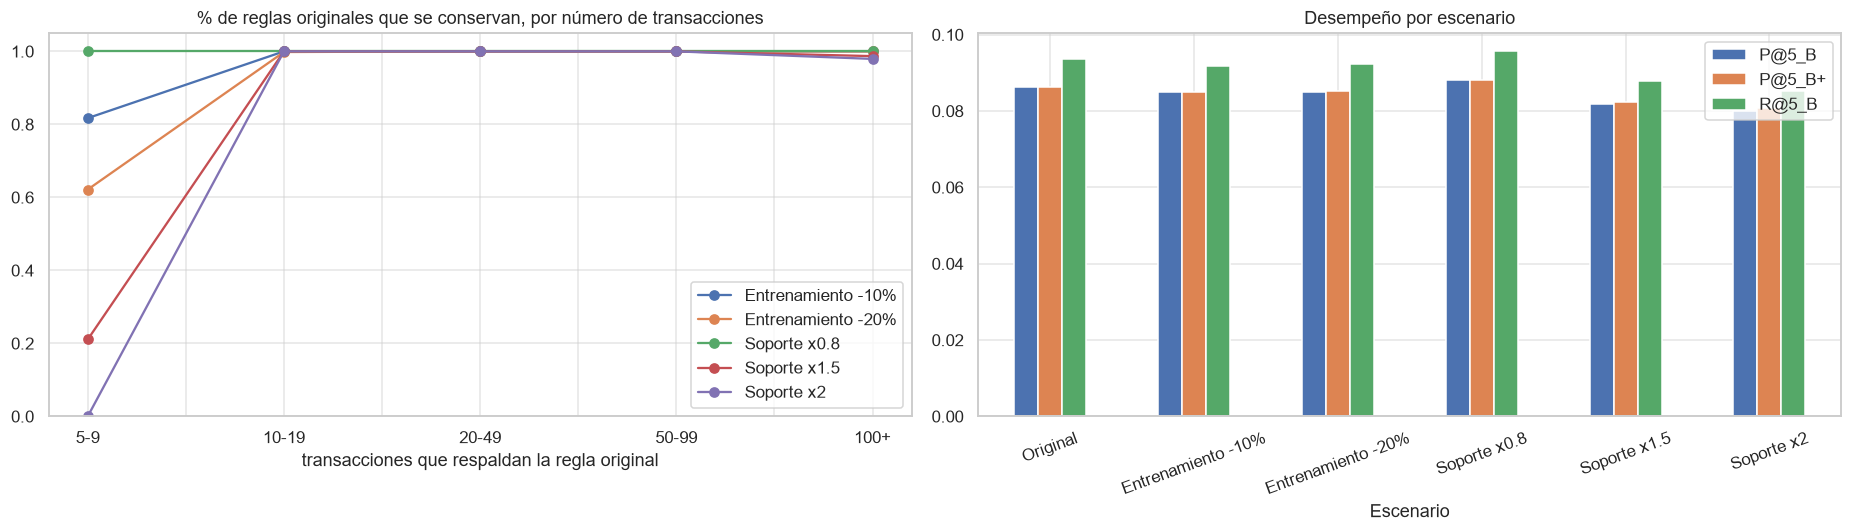

Reglas presentes en todos los escenarios: 32.7%
         n_transacciones  confianza   lift
estable                                   
False                6.0      0.024  4.753
True                15.0      0.031  2.809

Reglas ESTABLES con mayor leverage:


,regla,soporte,confianza,lift,leverage,conviction,jaccard,n_transacciones,escenarios_presente
0,{Organic Hass Avocado} → {Bag of Organic Bananas},0.0181,0.2760,2.4343,0.0107,1.2247,0.1125,1574,5
1,{Bag of Organic Bananas} → {Organic Hass Avocado},0.0181,0.1597,2.4343,0.0107,1.1120,0.1125,1574,5
2,{Organic Avocado} → {Banana},0.0164,0.3001,2.0591,0.0085,1.2206,0.0893,1429,5
3,{Banana} → {Organic Avocado},0.0164,0.1128,2.0591,0.0085,1.0654,0.0893,1429,5
4,{Organic Strawberries} → {Bag of Organic Bananas},0.0169,0.1973,1.7398,0.0072,1.1045,0.0929,1472,5
5,{Bag of Organic Bananas} → {Organic Strawberries},0.0169,0.1493,1.7398,0.0072,1.0746,0.0929,1472,5
6,{Organic Baby Spinach} → {Bag of Organic Bananas},0.0155,0.2097,1.8492,0.0071,1.1218,0.0903,1350,5
7,{Bag of Organic Bananas} → {Organic Baby Spinach},0.0155,0.1369,1.8492,0.0071,1.0729,0.0903,1350,5
8,{Organic Hass Avocado} → {Organic Strawberries},0.0127,0.1936,2.2559,0.0071,1.1337,0.0915,1104,5
9,{Organic Strawberries} → {Organic Hass Avocado},0.0127,0.1480,2.2559,0.0071,1.0967,0.0915,1104,5


Reglas que DESAPARECEN en algún escenario (mayor lift):


,regla,soporte,confianza,lift,leverage,conviction,jaccard,n_transacciones,escenarios_presente
0,{Cacao Chocolate Mint} → {Organic Bold Original Cacao Superfood Drink},0.0001,1.0000,17386.4000,0.0001,inf,1.0000,5,3
1,{Organic Bold Original Cacao Superfood Drink} → {Cacao Chocolate Mint},0.0001,1.0000,17386.4000,0.0001,inf,1.0000,5,3
2,{Wine Snack Herring} → {Mandarin Oranges In Light Syrup},0.0001,1.0000,14488.6667,0.0001,inf,0.8333,5,3
3,{Chocolate Mint Nutrition Bar} → {Double Dark Chocolate Nutrition Bar},0.0001,1.0000,14488.6667,0.0001,inf,0.8333,5,1
4,{Chocolate Mint Nutrition Bar} → {Strawberry Yogurt Nutrition Bar},0.0001,1.0000,14488.6667,0.0001,inf,0.8333,5,1
5,{Strawberry Yogurt Nutrition Bar} → {Chocolate Mint Nutrition Bar},0.0001,0.8333,14488.6667,0.0001,5.9997,0.8333,5,1
6,{Double Dark Chocolate Nutrition Bar} → {Chocolate Mint Nutrition Bar},0.0001,0.8333,14488.6667,0.0001,5.9997,0.8333,5,1
7,{Mandarin Oranges In Light Syrup} → {Wine Snack Herring},0.0001,0.8333,14488.6667,0.0001,5.9997,0.8333,5,3
8,{Pure Zero Punched Energy Drink} → {Ultra Red Energy},0.0001,0.7143,12418.8571,0.0001,3.4998,0.7143,5,3
9,{Ultra Blue Energy Drink} → {Pure Zero Punched Energy Drink},0.0001,1.0000,12418.8571,0.0001,inf,0.7143,5,3


In [45]:
# Estabilidad según el soporte de la regla original
bins = [5, 10, 20, 50, 100, np.inf]
etq_b = ['5-9', '10-19', '20-49', '50-99', '100+']
grupo_sop = pd.cut(base_tr.n_transacciones, bins=bins, right=False, labels=etq_b)
ret = pd.DataFrame({nombre: pd.Series([k in claves for k in claves_orig]).groupby(grupo_sop.to_numpy()).mean()
                    for nombre, claves in presencia.items() if nombre != 'Original'}).reindex(etq_b)
fig, ax = plt.subplots(1, 2, figsize=(17, 5))
ret.plot(marker='o', ax=ax[0]); ax[0].set_title('% de reglas originales que se conservan, por número de transacciones')
ax[0].set_xlabel('transacciones que respaldan la regla original'); ax[0].set_ylim(0, 1.05)
rob.set_index('Escenario')[['P@5_B', 'P@5_B+', 'R@5_B']].plot.bar(ax=ax[1], rot=20, title='Desempeño por escenario')
plt.tight_layout(); plt.show()

# Reglas estables vs reglas que desaparecen
n_esc = sum(1 for n in presencia if n != 'Original')
base_tr_ = base_tr.copy()
base_tr_['escenarios_presente'] = [sum(k in presencia[n] for n in presencia if n != 'Original') for k in claves_orig]
base_tr_['estable'] = base_tr_.escenarios_presente == n_esc
print(f'Reglas presentes en todos los escenarios: {base_tr_.estable.mean():.1%}')
print(base_tr_.groupby('estable')[['n_transacciones', 'confianza', 'lift']].median().round(3).to_string())
fiables = base_tr_[base_tr_.n_transacciones >= 20]
print('\nReglas ESTABLES con mayor leverage:')
ver(decorar(fiables[fiables.estable].nlargest(10, 'leverage')), COLS + ['escenarios_presente'])
print('Reglas que DESAPARECEN en algún escenario (mayor lift):')
ver(decorar(base_tr_[~base_tr_.estable].nlargest(10, 'lift')), COLS + ['escenarios_presente'])

### Comportamiento con productos poco frecuentes

In [46]:
bins_f = [1, 5, 20, 100, 500, np.inf]
etq_f = ['1-4', '5-19', '20-99', '100-499', '500+']
cons_con_reglas = set(base_tr.consecuente.tolist())
tab_f = pd.DataFrame({'product_id': ids_tr, 'conteo': cnt_tr})
tab_f['frecuencia'] = pd.cut(tab_f.conteo, bins=bins_f, right=False, labels=etq_f)
tab_f['con_reglas_antecedente'] = tab_f.product_id.isin(list(rec_tr.items_con_reglas))
tab_f['con_reglas_consecuente'] = tab_f.product_id.isin(list(cons_con_reglas))
res_f = tab_f.groupby('frecuencia').agg(productos=('product_id', 'size'), con_reglas_antecedente=('con_reglas_antecedente', 'mean'),
                                         con_reglas_consecuente=('con_reglas_consecuente', 'mean'))
for s in ['A: Popularidad', 'B: Reglas (confianza)', 'B+: Reglas + relleno popular']:
    h = pd.DataFrame(detalle7[s]['hits_items'], columns=['product_id', 'acierto'])
    h['frecuencia'] = pd.cut(h.product_id.map(cnt_tr_dict).fillna(0), bins=[0] + bins_f, right=False, labels=['0 (nuevo)'] + etq_f)
    res_f = res_f.join(h.groupby('frecuencia').acierto.mean().rename(f'tasa_acierto_{s[:2].strip(":")}'), how='outer')
res_f = res_f.reindex(['0 (nuevo)'] + etq_f)
display(res_f.round(3))

entradas_raras = np.array([max(cnt_tr_dict.get(i, 0) for i in v) < 20 for _, v, _ in casos])
print(f'\nCasos cuya entrada solo tiene productos raros (< 20 compras en entrenamiento): {entradas_raras.sum()}')
if entradas_raras.sum():
    for s in SISTEMAS:
        print(f'  {s:30s} P@5 = {detalle7[s]["prec"][entradas_raras].mean():.4f} | P@5 resto = {detalle7[s]["prec"][~entradas_raras].mean():.4f}')

,productos,con_reglas_antecedente,con_reglas_consecuente,tasa_acierto_A,tasa_acierto_B,tasa_acierto_B+
frecuencia,,,,,,
0 (nuevo),NaN,NaN,NaN,0.00,0.000,0.000
1-4,15078.0,0.000,0.000,0.00,0.000,0.000
5-19,8683.0,0.339,0.339,0.00,0.015,0.015
20-99,4936.0,0.955,0.955,0.00,0.040,0.040
100-499,1302.0,1.000,1.000,0.00,0.040,0.040
500+,201.0,1.000,1.000,0.17,0.177,0.177



Casos cuya entrada solo tiene productos raros (< 20 compras en entrenamiento): 125
  A: Popularidad                 P@5 = 0.0112 | P@5 resto = 0.0583
  B: Reglas (confianza)          P@5 = 0.0272 | P@5 resto = 0.0858
  B: Reglas (lift)               P@5 = 0.0256 | P@5 resto = 0.0233
  B+: Reglas + relleno popular   P@5 = 0.0336 | P@5 resto = 0.0858


El número de reglas cambia mucho con los parámetros, pero el desempeño casi no. Quitar el 10 % o el 20 % del entrenamiento elimina el 12 % y el 25 % de las reglas, y duplicar el soporte deja solo el 33 %. Aun así, la Precision@5 casi no se mueve (de 0.086 a entre 0.080 y 0.088), y las reglas que se quedan conservan su orden por lift (Spearman de 0.99 o más).

Solo el 32.7 % de las reglas está en todos los escenarios. Las que desaparecen son las que tienen pocas transacciones detrás (mediana de 6 contra 15 en las estables) y lift alto (4.75 contra 2.81). Son reglas de productos raros, con un lift muy inestable; por ejemplo, hay una regla con 5 transacciones y lift de 17,386. Por eso el desempeño no cambia: las recomendaciones que aciertan vienen de reglas con mucho soporte, y esas siempre se quedan.

El punto débil es la cola larga. Los productos con menos de 5 compras (15,078, la mitad del catálogo) no tienen ni una regla, y los de 5 a 19 compras solo el 34 %. Aun así, en las 125 canastas cuya entrada solo tiene productos raros, las reglas siguen siendo mejores que la popularidad (P@5 de 0.027 en B y 0.034 en B+ contra 0.011 en A), aunque todos los sistemas aciertan mucho menos que con productos comunes.

# Reto final

**¿Es posible construir un sistema de recomendaciones que genere resultados más relevantes que recomendar simplemente los productos más populares?**

In [47]:
r7 = resultados7.set_index('Sistema')
A_ = r7.loc['A: Popularidad']
mejor_b = r7.drop('A: Popularidad')['Precision@5'].idxmax()
B_ = r7.loc[mejor_b]
s_b = sig7[(sig7['Sistema B'] == mejor_b) & (sig7['métrica'] == 'Precision@5')].iloc[0]
print(f'Mejor sistema basado en reglas: {mejor_b}')
for m in ['Precision@5', 'Recall@5', 'Cobertura_catalogo', 'Tiempo_promedio_ms']:
    cambio = (B_[m] / A_[m] - 1) if A_[m] else np.nan
    print(f'  {m:22s} A = {A_[m]:.4f} | B = {B_[m]:.4f} | cambio relativo {cambio:+.1%}')
print(f'  Diferencia en Precision@5: {s_b["diferencia_media (B - A)"]:+.4f} '
      f'(p Wilcoxon = {s_b.p_valor_wilcoxon:.2e})')
supera = s_b['diferencia_media (B - A)'] > 0 and s_b.p_valor_wilcoxon < 0.05
print('\nRespuesta experimental:', 'SÍ, el sistema de reglas supera a la popularidad de forma significativa.' if supera
      else 'NO de forma concluyente, el sistema de reglas no supera significativamente a la popularidad en precisión.')

Mejor sistema basado en reglas: B+: Reglas + relleno popular
  Precision@5            A = 0.0571 | B = 0.0845 | cambio relativo +48.1%
  Recall@5               A = 0.0562 | B = 0.0899 | cambio relativo +59.9%
  Cobertura_catalogo     A = 0.0003 | B = 0.0758 | cambio relativo +25322.2%
  Tiempo_promedio_ms     A = 0.0027 | B = 0.5471 | cambio relativo +20133.4%
  Diferencia en Precision@5: +0.0274 (p Wilcoxon = 3.48e-63)

Respuesta experimental: SÍ, el sistema de reglas supera a la popularidad de forma significativa.


Sí. Los resultados de las Partes 5, 7 y 8 apuntan a lo mismo.

El mejor sistema de reglas (B+) llega a Precision@5 = 0.0845 y Recall@5 = 0.0899, contra 0.0571 y 0.0562 de la popularidad (+48 % y +60 %). La diferencia es significativa (p de Wilcoxon = 3.5 × 10⁻⁶³) y se midió en 5,000 canastas de prueba que son posteriores en el tiempo a las de entrenamiento.

Las reglas también recomiendan mucho más variado: 2,288 productos distintos contra 9 de la popularidad (cobertura de 7.6 % contra 0.03 %), porque cambian según la canasta. Incluso cuando la entrada solo tiene productos poco frecuentes, las reglas triplican la precisión de la popularidad (0.034 contra 0.011). Con 20 % menos datos o el doble de soporte, la precisión casi no cambia (0.080 a 0.088) aunque el número de reglas varía mucho, y cada consulta tarda menos de 1 ms.

Para que funcione hay que ordenar por confianza y filtrar con lift > 1 (ordenar por lift lo empeora), y completar con populares cuando no hay reglas que apliquen. La ventaja en números absolutos es pequeña, como 1 acierto extra cada 7 consultas de 5 productos, porque la demanda está muy concentrada y los productos populares son difíciles de superar. Donde más aportan las reglas es en personalizar y variar las recomendaciones, que es algo que la popularidad no puede hacer.

## Reproducibilidad

In [48]:
config = {k: v for k, v in globals().items() if k.isupper() and isinstance(v, (int, float, str, list))}
config['SOPORTE_REGLAS_USADO'] = SOPORTE_REGLAS_USADO
try:
    import gradio
    VERSIONES['gradio'] = gradio.__version__
except Exception:
    pass
with open(os.path.join(DIR_SALIDA, 'configuracion_reproducibilidad.json'), 'w') as f:
    json.dump({'parametros': config, 'versiones': VERSIONES}, f, indent=2, ensure_ascii=False, default=str)
print(json.dumps({'parametros': config, 'versiones': VERSIONES}, indent=2, ensure_ascii=False, default=str))
print('\nArchivos generados:')
for p in sorted(os.listdir(DIR_SALIDA)):
    print(f'  {p:40s} {os.path.getsize(os.path.join(DIR_SALIDA, p))/2**20:8.2f} MB')

{
  "parametros": {
    "SEMILLA": 42,
    "EN_COLAB": false,
    "DIR_DATOS_LOCAL": "data",
    "DIR_SALIDA": "artefactos",
    "N_ORDENES_OBJETIVO": 120000,
    "SOPORTES": [
      0.02,
      0.01,
      0.0075,
      0.005,
      0.003
    ],
    "SOPORTE_REGLAS": 0.002,
    "CONF_MIN_REGLAS": 0.05,
    "MEJORA_MIN": 0.01,
    "SOPORTE_SEG": 0.004,
    "MIN_CONTEO_PAR": 5,
    "PROP_ENTRENAMIENTO": 0.7,
    "N_CANASTAS_EVAL": 5000,
    "N_EVAL_ROBUSTEZ": 2000,
    "PROP_OCULTA": 0.5,
    "K": 5,
    "K_ENTRADA_MAX": 5,
    "LIFT_MIN_EVAL": 1.0,
    "SOPORTE_APP": 0.001,
    "TOP_K_APP_CONF": 30,
    "TOP_K_APP_LIFT": 20,
    "DIR_DATOS": "data",
    "ARCHIVOS": [
      "orders.csv",
      "order_products__prior.csv",
      "order_products__train.csv",
      "products.csv",
      "aisles.csv",
      "departments.csv"
    ],
    "N_MUESTRA": 120003,
    "LIM_ATIPICO": 41.0,
    "N": 119533,
    "N_TOT": 119533,
    "SOPORTE_REGLAS_USADO": 0.002,
    "COLS": [
      "regla",
      "so